# EduGap-XAI

**Integrasi Spatial Autocorrelation, Association Rule Mining, dan SHAP-Based Forecasting sebagai Sistem Cerdas Peringatan Dini Kesenjangan Partisipasi Sekolah Menengah Antarprovinsi di Indonesia**

DIMAS-TI AMLI 2026, Divisi Penambangan Data.

Notebook ini menjalankan seluruh pipeline dari awal sampai akhir: memuat data, EDA sebelum preprocessing, preprocessing, EDA setelah preprocessing, autokorelasi spasial (Global Moran's I dan LISA), association rule mining, explainable forecasting dengan SHAP, lalu triangulasi ketiga bukti menjadi Indeks Prioritas Intervensi.

Ketiga metode disusun berantai, bukan paralel:

1. **Spatial Autocorrelation** menghasilkan spatial lag dan regime spasial (HH, LL, LH, HL) untuk setiap provinsi-tahun.
2. **Association Rule Mining** memakai spatial lag (kondisi lingkungan tetangga) sebagai item, lalu menghasilkan aturan risiko yang teruji secara statistik.
3. **Explainable Forecasting** dengan ElasticNet dan LightGBM memproyeksikan APS 16-18 tahun 2026 dan 2027, memakai fitur spasial dan fitur aturan sebagai input, lalu diuji dengan ablation study dan dijelaskan dengan SHAP.
4. **Triangulasi** menyatukan ketiga sinyal menjadi tipologi dan prioritas intervensi per provinsi.

Pertanyaan riset:

- **RQ1** Apakah kesenjangan APS 16-18 mengelompok secara spasial dan apakah pengelompokannya menguat?
- **RQ2** Kombinasi kondisi apa yang konsisten muncul bersama APS 16-18 rendah, dan apakah lingkungan tetangga memengaruhi peluang provinsi naik atau turun kelas?
- **RQ3** Seberapa akurat APS 16-18 tahun 2026 dan 2027 dapat diproyeksikan dengan ElasticNet dan LightGBM, faktor apa yang mendorongnya, dan seberapa besar ketidakpastiannya?
- **RQ4** Provinsi mana yang ditandai berisiko oleh ketiga bukti sekaligus?


## 0. Instalasi Paket

Colab sudah menyediakan pandas, numpy, scikit-learn, matplotlib, dan seaborn. Paket untuk analisis spasial (libpysal, esda), pattern mining (mlxtend), model boosting (lightgbm), dan explainability (shap) dipasang hanya jika belum tersedia.

In [1]:
import importlib.util
import subprocess
import sys

REQUIRED = {"libpysal": "libpysal", "esda": "esda", "mlxtend": "mlxtend", "lightgbm": "lightgbm", "shap": "shap"}
missing = [pkg for module, pkg in REQUIRED.items() if importlib.util.find_spec(module) is None]
if missing:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *missing], check=True)
print("Paket yang dipasang:", ", ".join(missing) if missing else "tidak ada, semua sudah tersedia")

Paket yang dipasang: tidak ada, semua sudah tersedia


## 0.1 Import Library dan Konfigurasi Global

Semua parameter penting dikumpulkan di satu tempat supaya mudah dijelaskan di makalah dan direproduksi: jumlah tetangga KNN, jumlah permutasi uji signifikansi, tingkat signifikansi, ambang association rule, jumlah bootstrap, serta seed acak.

In [2]:
import json
import shutil
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
import seaborn as sns
from scipy import stats
from libpysal.weights import KNN
from esda.moran import Moran, Moran_Local, Moran_BV, Moran_Local_BV
from mlxtend.frequent_patterns import fpgrowth
from sklearn.linear_model import ElasticNetCV
from sklearn.model_selection import KFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, cohen_kappa_score
import lightgbm as lgb
import shap

warnings.filterwarnings("ignore")
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 50)
pd.set_option("display.max_colwidth", 80)

SEED = 42
np.random.seed(SEED)
TARGET = "aps_16_18"
K_NEIGHBORS = 4
K_SENSITIVITY = [3, 4, 5, 6]
PERMUTATIONS = 9999
ALPHA = 0.05
RULE_MIN_SUPPORT = 0.08
RULE_MIN_CONFIDENCE = 0.60
RULE_MIN_LIFT = 1.20
RULE_MAX_LEN = 4
RULE_STABILITY = 0.60
RULE_TOP_K = 10
BOOTSTRAP_MAIN = 500
BOOTSTRAP_FOLD = 200
CONFORMAL_ALPHA = 0.10
SPLIT_YEAR = 2024

plt.rcParams.update({
    "figure.dpi": 110,
    "savefig.dpi": 200,
    "font.size": 10,
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "axes.labelsize": 10,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "legend.frameon": False,
})
sns.set_palette("deep")

COLORS = {"primary": "#1F4E79", "accent": "#C0392B", "muted": "#7F8C8D", "good": "#1E8449", "warn": "#D68910"}
LISA_COLORS = {"HH": "#C0392B", "LL": "#2471A3", "LH": "#85C1E9", "HL": "#F5B041", "Tidak signifikan": "#D5D8DC"}
REGION_COLORS = {"Sumatera": "#1F77B4", "Jawa": "#D62728", "Bali-Nusa Tenggara": "#2CA02C",
                 "Kalimantan": "#FF7F0E", "Sulawesi": "#9467BD", "Maluku-Papua": "#8C564B"}
print("Konfigurasi siap. Target analisis:", TARGET)

Konfigurasi siap. Target analisis: aps_16_18


## 0.2 Folder Output dan Fungsi Bantu

Struktur output dibuat terpisah per jenis dan per tahap analisis, sehingga mudah dipindahkan ke VS Code lalu ke repositori web:

- `figures/<tahap>/` berisi seluruh gambar PNG.
- `tables/<tahap>/` berisi seluruh tabel CSV.
- `data/` berisi dataset bersih dan log imputasi.
- `web_data/` berisi file JSON siap pakai untuk dashboard web.
- `report/` berisi ringkasan temuan otomatis dalam Markdown.

Fungsi bantu di sel ini dipakai berulang: menyimpan gambar dan tabel, memberi label angka pada grafik, koreksi Benjamini-Hochberg, dan menggambar peta gelembung provinsi.

In [3]:
OUT = Path("EduGap_XAI_outputs")
if OUT.exists():
    shutil.rmtree(OUT)
STAGES = ["01_eda_raw", "02_eda_clean", "03_spatial", "04_pattern", "05_forecast", "06_xai", "07_triangulation"]
DIRS = {"fig": OUT / "figures", "tab": OUT / "tables", "data": OUT / "data", "web": OUT / "web_data", "rep": OUT / "report"}
for stage in STAGES:
    (DIRS["fig"] / stage).mkdir(parents=True, exist_ok=True)
    (DIRS["tab"] / stage).mkdir(parents=True, exist_ok=True)
for key in ["data", "web", "rep"]:
    DIRS[key].mkdir(parents=True, exist_ok=True)


def save_fig(fig, stage, name):
    fig.savefig(DIRS["fig"] / stage / f"{name}.png", bbox_inches="tight", facecolor="white")
    plt.show()
    plt.close(fig)


def save_table(df, stage, name, index=False):
    df.to_csv(DIRS["tab"] / stage / f"{name}.csv", index=index)
    return df


def label_bars(ax, fmt="{:.2f}", fontsize=8, padding=2):
    for container in ax.containers:
        ax.bar_label(container, fmt=fmt, fontsize=fontsize, padding=padding)


def bh_fdr(pvalues):
    p = np.asarray(pvalues, dtype=float)
    n = len(p)
    if n == 0:
        return p
    order = np.argsort(p)
    ranked = p[order] * n / np.arange(1, n + 1)
    ranked = np.minimum.accumulate(ranked[::-1])[::-1]
    q = np.empty(n)
    q[order] = np.clip(ranked, 0, 1)
    return q


def outlined(text_obj):
    text_obj.set_path_effects([pe.withStroke(linewidth=2.5, foreground="white")])
    return text_obj


LABEL_NUDGE = {"BANTEN": (-12, -1), "DKI": (6, 1), "JABAR": (12, -1), "JATENG": (0, 1), "DIY": (0, -1),
               "BALI": (-8, -1), "NTB": (8, 1), "LAMPUNG": (-14, 1), "KALSEL": (0, -1)}


def province_map(ax, frame, color, size=220, label_col="kode", value_col=None, value_fmt="{:.1f}",
                 edge=None, linewidth=None, title=None):
    ax.set_facecolor("#F4F8FB")
    sizes = np.broadcast_to(np.asarray(size, dtype=float), (len(frame),))
    ax.scatter(frame["lon"], frame["lat"], s=sizes, c=color,
               edgecolors=edge if edge is not None else "white",
               linewidths=linewidth if linewidth is not None else 1.0, zorder=3)
    for (_, row), s_point in zip(frame.iterrows(), sizes):
        text = row[label_col] if value_col is None else f"{row[label_col]}\n{value_fmt.format(row[value_col])}"
        dx, direction = LABEL_NUDGE.get(row["kode"], (0, 1))
        dy = direction * (np.sqrt(s_point) / 2 + 3)
        outlined(ax.annotate(text, (row["lon"], row["lat"]), xytext=(dx, dy), textcoords="offset points",
                             ha="center", va="bottom" if direction > 0 else "top", fontsize=6.5, zorder=4))
    ax.set_xlim(93.5, 142.5)
    ax.set_ylim(-11.8, 7.8)
    ax.set_xlabel("Bujur")
    ax.set_ylabel("Lintang")
    ax.grid(alpha=0.15)
    if title:
        ax.set_title(title)


print("Folder output:", OUT.resolve())

Folder output: /content/EduGap_XAI_outputs


## 0.3 Metadata Provinsi

Metadata berisi kode singkat, wilayah, dan koordinat ibu kota provinsi. Koordinat ibu kota dipakai sebagai titik representatif untuk matriks bobot spasial K-Nearest Neighbors. Pendekatan berbasis jarak dipilih karena Indonesia adalah negara kepulauan, sehingga banyak provinsi tidak bersinggungan darat dan matriks contiguity (queen atau rook) akan menghasilkan provinsi tanpa tetangga.

Pemetaan provinsi induk dipakai untuk empat Daerah Otonomi Baru (DOB) Papua hasil pemekaran 2022.

In [4]:
PROVINCE_META = pd.DataFrame([
    ("ACEH", "ACEH", "Sumatera", 5.55, 95.32), ("SUMATERA UTARA", "SUMUT", "Sumatera", 3.59, 98.67),
    ("SUMATERA BARAT", "SUMBAR", "Sumatera", -0.95, 100.35), ("RIAU", "RIAU", "Sumatera", 0.51, 101.45),
    ("JAMBI", "JAMBI", "Sumatera", -1.61, 103.61), ("SUMATERA SELATAN", "SUMSEL", "Sumatera", -2.98, 104.76),
    ("BENGKULU", "BENGKULU", "Sumatera", -3.80, 102.27), ("LAMPUNG", "LAMPUNG", "Sumatera", -5.43, 105.26),
    ("KEP. BANGKA BELITUNG", "BABEL", "Sumatera", -2.13, 106.11), ("KEP. RIAU", "KEPRI", "Sumatera", 0.92, 104.45),
    ("DKI JAKARTA", "DKI", "Jawa", -6.21, 106.85), ("JAWA BARAT", "JABAR", "Jawa", -6.91, 107.61),
    ("JAWA TENGAH", "JATENG", "Jawa", -6.99, 110.42), ("DI YOGYAKARTA", "DIY", "Jawa", -7.80, 110.36),
    ("JAWA TIMUR", "JATIM", "Jawa", -7.25, 112.75), ("BANTEN", "BANTEN", "Jawa", -6.12, 106.15),
    ("BALI", "BALI", "Bali-Nusa Tenggara", -8.65, 115.22), ("NUSA TENGGARA BARAT", "NTB", "Bali-Nusa Tenggara", -8.58, 116.12),
    ("NUSA TENGGARA TIMUR", "NTT", "Bali-Nusa Tenggara", -10.18, 123.61), ("KALIMANTAN BARAT", "KALBAR", "Kalimantan", -0.03, 109.33),
    ("KALIMANTAN TENGAH", "KALTENG", "Kalimantan", -2.21, 113.92), ("KALIMANTAN SELATAN", "KALSEL", "Kalimantan", -3.44, 114.83),
    ("KALIMANTAN TIMUR", "KALTIM", "Kalimantan", -0.50, 117.15), ("KALIMANTAN UTARA", "KALTARA", "Kalimantan", 2.84, 117.37),
    ("SULAWESI UTARA", "SULUT", "Sulawesi", 1.47, 124.84), ("SULAWESI TENGAH", "SULTENG", "Sulawesi", -0.90, 119.87),
    ("SULAWESI SELATAN", "SULSEL", "Sulawesi", -5.15, 119.43), ("SULAWESI TENGGARA", "SULTRA", "Sulawesi", -3.97, 122.51),
    ("GORONTALO", "GORONTALO", "Sulawesi", 0.54, 123.06), ("SULAWESI BARAT", "SULBAR", "Sulawesi", -2.68, 118.89),
    ("MALUKU", "MALUKU", "Maluku-Papua", -3.70, 128.18), ("MALUKU UTARA", "MALUT", "Maluku-Papua", 0.74, 127.56),
    ("PAPUA BARAT", "PABAR", "Maluku-Papua", -0.86, 134.06), ("PAPUA BARAT DAYA", "PBD", "Maluku-Papua", -0.88, 131.25),
    ("PAPUA", "PAPUA", "Maluku-Papua", -2.53, 140.72), ("PAPUA SELATAN", "PASEL", "Maluku-Papua", -8.49, 140.40),
    ("PAPUA TENGAH", "PATENG", "Maluku-Papua", -3.37, 135.50), ("PAPUA PEGUNUNGAN", "PAPEG", "Maluku-Papua", -4.10, 138.95),
], columns=["provinsi", "kode", "wilayah", "lat", "lon"])

DOB_PARENT = {"PAPUA BARAT DAYA": "PAPUA BARAT", "PAPUA SELATAN": "PAPUA",
              "PAPUA TENGAH": "PAPUA", "PAPUA PEGUNUNGAN": "PAPUA"}
SPLIT_GROUP = sorted(set(DOB_PARENT) | set(DOB_PARENT.values()))
print(PROVINCE_META.groupby("wilayah").size().rename("jumlah_provinsi").to_string())
print("\nDOB dan provinsi induk:", DOB_PARENT)

wilayah
Bali-Nusa Tenggara     3
Jawa                   6
Kalimantan             5
Maluku-Papua           8
Sulawesi               6
Sumatera              10

DOB dan provinsi induk: {'PAPUA BARAT DAYA': 'PAPUA BARAT', 'PAPUA SELATAN': 'PAPUA', 'PAPUA TENGAH': 'PAPUA', 'PAPUA PEGUNUNGAN': 'PAPUA'}


## 1. Memuat Data

Dataset bersumber dari BPS: 38 provinsi x 5 tahun (2021-2025) dengan 22 kolom indikator pendidikan, ketenagakerjaan, kemiskinan, pembangunan manusia, pangan, ekonomi, dan infrastruktur dasar.

In [5]:
DATA_FILE = "Dataset_BPS_csv_-_DATA.csv"
if not Path(DATA_FILE).exists():
    try:
        from google.colab import files
        uploaded = files.upload()
        DATA_FILE = next(iter(uploaded))
    except ImportError as error:
        raise FileNotFoundError(f"File {DATA_FILE} tidak ditemukan di direktori kerja.") from error

raw = pd.read_csv(DATA_FILE)
print(f"File : {DATA_FILE}")
print(f"Ukuran: {raw.shape[0]} baris x {raw.shape[1]} kolom")
raw.head()

Saving Dataset BPS.csv - DATA.csv to Dataset BPS.csv - DATA.csv
File : Dataset BPS.csv - DATA.csv
Ukuran: 190 baris x 22 kolom


,Provinsi,Tahun,APS 7-12,APS 13-15,APS 16-18,APS 19-23,Tingkat Pengangguran Terbuka (persen),Angkatan Kerja Terhadap Penduduk Usia Kerja (TPAK) (persen),Garis Kemiskinan (Rupiah/Kapita/Bulan),Penduduk Miskin (persen),Indeks Pembangunan Manusia (IPM),Rata-rata Lama Sekolah (Tahun),Harapan Lama Sekolah (Tahun),Indeks Ketahanan Pangan,Luas Panen Tanaman Padi (ha) (Ha),Produktivitas Tanaman Padi (ku/ha) (Ku/ha),Rekap Produksi Padi (ton) (Ton),Produk Domestik Regional Bruto per Kapita (ribu rupiah),Rata-rata Pengeluaran per Kapita Sebulan Makanan (rupiah),Persentase Rumah Tangga yang Memiliki Akses terhadap Sumber Air Minum Layak (persen),Persentase Rumah Tangga menurut Provinsi dan Sumber Penerangan Utama dari Listrik,Prevalence of Undernourishment (Percent)
0,ACEH,2021,99.67,98.42,83.28,34.95,6.300,64.460,553270.3,15.43,72.18,9.37,14.36,71.63,297058.38,55.03,1634639.60,34674,643591.4,88.79,99.87,"6,9"
1,SUMATERA UTARA,2021,99.32,96.99,78.66,29.34,6.170,69.245,529548.5,8.75,72.00,9.58,13.27,72.25,385405.00,52.00,2004142.51,57442,607811.56,90.89,99.16,"6,33"
2,SUMATERA BARAT,2021,99.61,96.63,84.07,39.40,6.595,68.065,573911.0,6.00,72.65,9.07,14.09,79.55,272391.95,48.36,1317209.38,45218,668029.07,83.4,98.86,"6,02"
3,RIAU,2021,99.65,95.66,77.81,30.38,4.690,65.420,581382.3,7.06,72.94,9.19,13.28,66.84,53062.35,40.98,217458.87,129741,672142.73,89.76,98.32,"10,61"
4,JAMBI,2021,99.66,96.39,72.50,25.63,4.925,67.235,532922.5,7.88,71.63,8.60,13.04,74.18,64412.26,46.29,298149.25,64771,613752.76,79.7,99.03,"9,25"


### 1.1 Penamaan Kolom

Nama kolom asli BPS sangat panjang. Kolom diganti dengan nama pendek berformat snake_case agar kode bersih, sementara label lengkap disimpan terpisah untuk grafik dan tabel.

In [6]:
SHORT_NAMES = ["provinsi", "tahun", "aps_7_12", "aps_13_15", "aps_16_18", "aps_19_23", "tpt", "tpak",
               "garis_kemiskinan", "miskin", "ipm", "rls", "hls", "ikp", "luas_panen_padi", "produktivitas_padi",
               "produksi_padi", "pdrb_kapita", "pengeluaran_makanan", "air_minum_layak", "listrik", "pou"]
assert len(raw.columns) == len(SHORT_NAMES), "Jumlah kolom tidak sesuai dengan struktur dataset yang diharapkan."
column_map = pd.DataFrame({"kolom_asli": raw.columns, "kolom_baru": SHORT_NAMES})
raw.columns = SHORT_NAMES
raw["provinsi"] = raw["provinsi"].astype(str).str.strip().str.upper()

LABELS = {
    "aps_7_12": "APS 7-12 (%)", "aps_13_15": "APS 13-15 (%)", "aps_16_18": "APS 16-18 (%)", "aps_19_23": "APS 19-23 (%)",
    "tpt": "Pengangguran Terbuka (%)", "tpak": "TPAK (%)", "garis_kemiskinan": "Garis Kemiskinan (Rp)",
    "miskin": "Penduduk Miskin (%)", "ipm": "IPM", "rls": "Rata-rata Lama Sekolah (th)", "hls": "Harapan Lama Sekolah (th)",
    "ikp": "Indeks Ketahanan Pangan", "luas_panen_padi": "Luas Panen Padi (ha)", "produktivitas_padi": "Produktivitas Padi (ku/ha)",
    "produksi_padi": "Produksi Padi (ton)", "pdrb_kapita": "PDRB per Kapita (ribu Rp)",
    "pengeluaran_makanan": "Pengeluaran Makanan per Kapita (Rp)", "air_minum_layak": "Air Minum Layak (%)",
    "listrik": "Rumah Tangga Berlistrik (%)", "pou": "Prevalensi Kurang Gizi (%)",
    "log_pdrb_kapita": "log PDRB per Kapita", "log_pengeluaran_makanan": "log Pengeluaran Makanan",
    "w_aps_16_18": "Spatial Lag APS 16-18", "w_miskin": "Spatial Lag Kemiskinan", "regime_ll": "Regime Spasial LL",
    "rule_count": "Jumlah Aturan Risiko Terpenuhi", "rule_max_conf": "Confidence Maks Aturan Risiko",
}
save_table(column_map, "01_eda_raw", "pemetaan_nama_kolom")
column_map

,kolom_asli,kolom_baru
0,Provinsi,provinsi
1,Tahun,tahun
2,APS 7-12,aps_7_12
3,APS 13-15,aps_13_15
4,APS 16-18,aps_16_18
5,APS 19-23,aps_19_23
6,Tingkat Pengangguran Terbuka (persen),tpt
7,Angkatan Kerja Terhadap Penduduk Usia Kerja (TPAK) (persen),tpak
8,Garis Kemiskinan (Rupiah/Kapita/Bulan),garis_kemiskinan
9,Penduduk Miskin (persen),miskin


## 2. EDA Sebelum Preprocessing

### 2.1 Struktur Data

Langkah pertama memastikan struktur panel lengkap: setiap provinsi muncul di setiap tahun dan tidak ada duplikasi kunci provinsi-tahun. Tipe data juga diperiksa karena kolom angka yang terbaca sebagai teks menandakan ada format tidak standar.

In [7]:
panel_counts = raw.groupby("tahun")["provinsi"].nunique()
duplicate_keys = raw.duplicated(["provinsi", "tahun"]).sum()
unknown_provinces = sorted(set(raw["provinsi"]) - set(PROVINCE_META["provinsi"]))
dtype_table = pd.DataFrame({"kolom": raw.columns, "tipe_data": raw.dtypes.astype(str).values,
                            "nilai_unik": raw.nunique().values})
print("Jumlah provinsi per tahun:\n" + panel_counts.to_string())
print(f"\nDuplikasi kunci provinsi-tahun : {duplicate_keys}")
print(f"Provinsi tidak dikenal metadata: {unknown_provinces if unknown_provinces else 'tidak ada'}")
print(f"Kolom terbaca sebagai teks      : {[c for c in raw.columns[2:] if not pd.api.types.is_numeric_dtype(raw[c])]}")
save_table(dtype_table, "01_eda_raw", "tipe_data_mentah")
dtype_table

Jumlah provinsi per tahun:
tahun
2021    38
2022    38
2023    38
2024    38
2025    38

Duplikasi kunci provinsi-tahun : 0
Provinsi tidak dikenal metadata: tidak ada
Kolom terbaca sebagai teks      : ['pdrb_kapita', 'pengeluaran_makanan', 'air_minum_layak', 'listrik', 'pou']


,kolom,tipe_data,nilai_unik
0,provinsi,object,38
1,tahun,int64,5
2,aps_7_12,float64,97
3,aps_13_15,float64,160
4,aps_16_18,float64,170
5,aps_19_23,float64,168
6,tpt,float64,160
7,tpak,float64,171
8,garis_kemiskinan,float64,178
9,miskin,float64,133


### 2.2 Audit Kualitas Nilai Mentah

Setiap kolom diaudit untuk lima jenis masalah: nilai kosong, tanda strip (`-`), tanda tiga titik (`...`), penanda angka sementara BPS (`(*)` dan `(**)`), serta desimal koma (format Indonesia). Masalah ini harus dibereskan sebelum analisis karena akan membuat kolom terbaca sebagai teks.

                                     kosong_NaN  tanda_strip  tanda_tiga_titik  penanda_sementara  desimal_koma  total_masalah
Pengeluaran Makanan per Kapita (Rp)           8            0                 4                  0             0             12
Air Minum Layak (%)                           0           12                 0                  0             0             12
Rumah Tangga Berlistrik (%)                   0           12                 0                  0             0             12
PDRB per Kapita (ribu Rp)                     0            0                 8                 76             0             84
Prevalensi Kurang Gizi (%)                    0           12                 0                  0           176            188


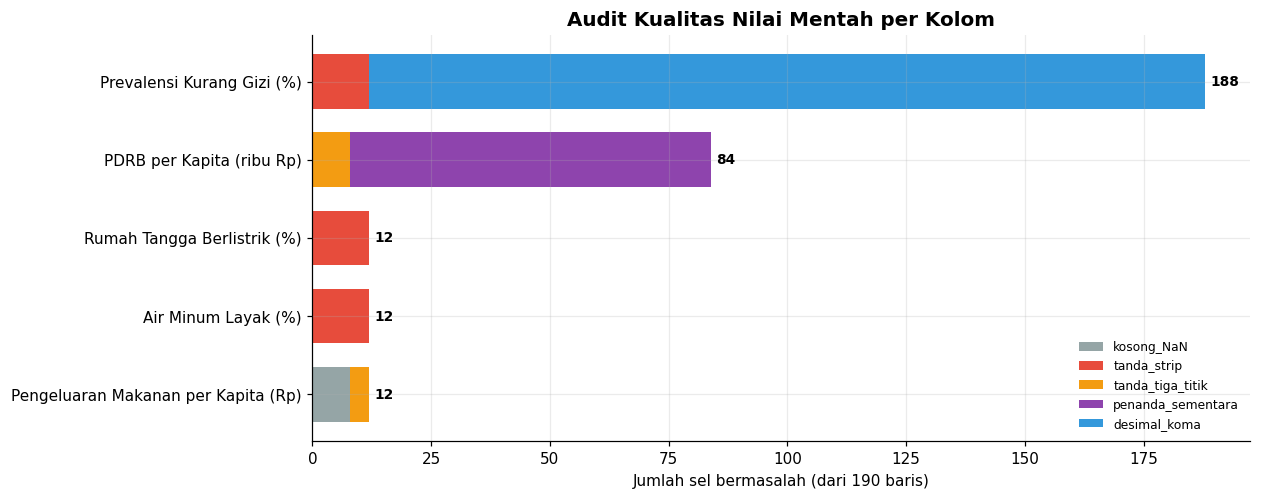

,kolom,kosong_NaN,tanda_strip,tanda_tiga_titik,penanda_sementara,desimal_koma,total_masalah
0,Pengeluaran Makanan per Kapita (Rp),8,0,4,0,0,12
1,Air Minum Layak (%),0,12,0,0,0,12
2,Rumah Tangga Berlistrik (%),0,12,0,0,0,12
3,PDRB per Kapita (ribu Rp),0,0,8,76,0,84
4,Prevalensi Kurang Gizi (%),0,12,0,0,176,188


In [8]:
def audit_column(series):
    text = series.astype("string").str.strip()
    return {
        "kosong_NaN": int(series.isna().sum()),
        "tanda_strip": int((text == "-").sum()),
        "tanda_tiga_titik": int((text == "...").sum()),
        "penanda_sementara": int(text.str.contains(r"\(\*", regex=True, na=False).sum()),
        "desimal_koma": int(text.str.fullmatch(r"-?\d+,\d+", na=False).sum()),
    }


audit = pd.DataFrame({col: audit_column(raw[col]) for col in raw.columns[2:]}).T
audit["total_masalah"] = audit.sum(axis=1)
audit = audit[audit["total_masalah"] > 0].sort_values("total_masalah", ascending=True)
audit.index = [LABELS.get(c, c) for c in audit.index]
print(audit.to_string())

fig, ax = plt.subplots(figsize=(11, 4.8))
audit.drop(columns="total_masalah").plot.barh(stacked=True, ax=ax, width=0.7,
                                              color=["#95A5A6", "#E74C3C", "#F39C12", "#8E44AD", "#3498DB"])
for i, total in enumerate(audit["total_masalah"]):
    ax.text(total + 1, i, f"{total}", va="center", fontsize=9, fontweight="bold")
ax.set_title("Audit Kualitas Nilai Mentah per Kolom")
ax.set_xlabel("Jumlah sel bermasalah (dari 190 baris)")
ax.legend(loc="lower right", fontsize=8)
save_fig(fig, "01_eda_raw", "audit_kualitas_nilai")
save_table(audit.reset_index().rename(columns={"index": "kolom"}), "01_eda_raw", "audit_kualitas_nilai")

### 2.3 Deteksi Data Salinan pada DOB Papua

Empat DOB Papua baru terbentuk pada 2022, tetapi dataset sudah memuat baris mereka sejak 2021. Jika nilai APS DOB pada 2021-2023 identik dengan provinsi induknya, berarti angka tersebut adalah salinan (backcast), bukan pengukuran mandiri. Baris salinan seperti ini berbahaya untuk analisis spasial karena menciptakan tetangga dengan nilai kembar yang menaikkan autokorelasi secara artifisial, dan berbahaya untuk forecasting karena pemisahan wilayah tampak seperti perubahan nyata.

Apakah APS DOB identik dengan provinsi induk?
tahun             2021  2022  2023   2024   2025
dob                                             
PAPUA BARAT DAYA  True  True  True  False  False
PAPUA PEGUNUNGAN  True  True  True  False  False
PAPUA SELATAN     True  True  True  False  False
PAPUA TENGAH      True  True  True  False  False

Tahun dengan data salinan: [np.int64(2021), np.int64(2022), np.int64(2023)]


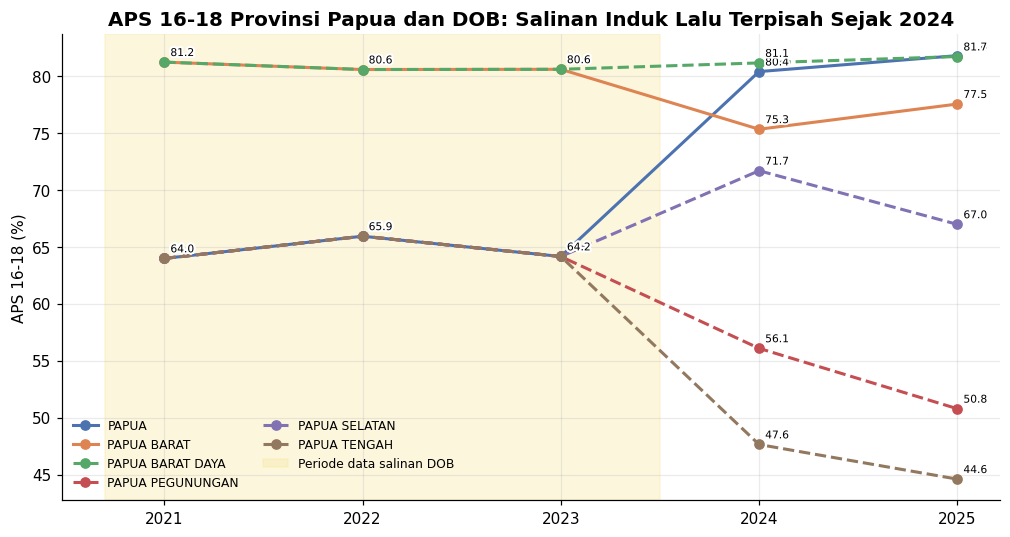

In [9]:
aps_cols = ["aps_7_12", "aps_13_15", "aps_16_18", "aps_19_23"]
copy_rows = []
for child, parent in DOB_PARENT.items():
    for year in sorted(raw["tahun"].unique()):
        child_values = raw.loc[(raw["provinsi"] == child) & (raw["tahun"] == year), aps_cols].iloc[0].astype(float)
        parent_values = raw.loc[(raw["provinsi"] == parent) & (raw["tahun"] == year), aps_cols].iloc[0].astype(float)
        copy_rows.append({"dob": child, "induk": parent, "tahun": year,
                          "selisih_aps_maks": round(float((child_values - parent_values).abs().max()), 3),
                          "aps_identik_dengan_induk": bool(np.allclose(child_values, parent_values))})
copy_check = pd.DataFrame(copy_rows)
copy_summary = copy_check.pivot(index="dob", columns="tahun", values="aps_identik_dengan_induk")
print("Apakah APS DOB identik dengan provinsi induk?\n" + copy_summary.to_string())
backcast_years = sorted(copy_check.loc[copy_check["aps_identik_dengan_induk"], "tahun"].unique())
print(f"\nTahun dengan data salinan: {backcast_years}")
save_table(copy_check, "01_eda_raw", "deteksi_salinan_dob")

fig, ax = plt.subplots(figsize=(11, 5.5))
for prov in SPLIT_GROUP:
    series = raw.loc[raw["provinsi"] == prov].sort_values("tahun")
    style = "-" if prov in DOB_PARENT.values() else "--"
    ax.plot(series["tahun"], series["aps_16_18"], style, marker="o", linewidth=2, label=prov)
    for x, y in zip(series["tahun"], series["aps_16_18"]):
        outlined(ax.annotate(f"{y:.1f}", (x, y), xytext=(4, 4), textcoords="offset points", fontsize=7))
ax.axvspan(2020.7, 2023.5, color="#F9E79F", alpha=0.35, label="Periode data salinan DOB")
ax.set_xticks(sorted(raw["tahun"].unique()))
ax.set_title("APS 16-18 Provinsi Papua dan DOB: Salinan Induk Lalu Terpisah Sejak 2024")
ax.set_ylabel(LABELS["aps_16_18"])
ax.legend(fontsize=8, ncol=2, loc="lower left")
save_fig(fig, "01_eda_raw", "salinan_dob_papua")

### 2.4 Statistik Deskriptif Data Mentah

Statistik ini hanya mencakup kolom yang sudah terbaca numerik. Kolom bertipe teks belum bisa diringkas dan akan ditangani di tahap preprocessing.

In [10]:
raw_numeric = raw.select_dtypes(include="number").drop(columns="tahun")
raw_describe = raw_numeric.describe().T
raw_describe["cv_persen"] = raw_describe["std"] / raw_describe["mean"] * 100
raw_describe.index = [LABELS.get(c, c) for c in raw_describe.index]
save_table(raw_describe.round(3).reset_index().rename(columns={"index": "kolom"}), "01_eda_raw", "statistik_deskriptif_mentah")
raw_describe.round(2)

,count,mean,std,min,25%,50%,75%,max,cv_persen
APS 7-12 (%),190.0,97.74,4.74,74.63,98.81,99.37,99.53,99.76,4.85
APS 13-15 (%),190.0,94.48,5.59,67.86,94.04,96.16,97.50,99.60,5.91
APS 16-18 (%),190.0,75.12,7.19,44.61,71.14,75.35,79.67,93.03,9.58
APS 19-23 (%),190.0,29.88,6.92,12.48,25.33,28.96,33.93,56.69,23.16
Pengangguran Terbuka (%),190.0,4.74,1.53,1.25,3.55,4.47,5.81,10.02,32.26
TPAK (%),190.0,69.80,4.22,62.52,66.97,69.28,71.31,89.46,6.05
Garis Kemiskinan (Rp),190.0,616838.29,142163.66,374774.30,511927.38,604153.65,693358.98,1325738.00,23.05
Penduduk Miskin (%),190.0,11.41,6.65,3.57,6.12,10.00,14.39,31.00,58.31
IPM,190.0,71.95,5.25,51.70,70.20,72.57,74.33,85.05,7.29
Rata-rata Lama Sekolah (th),190.0,8.77,1.11,4.21,8.08,8.84,9.45,11.59,12.63


### 2.5 Distribusi APS Mentah per Jenjang

Distribusi empat jenjang APS memperlihatkan pola khas pendidikan Indonesia: partisipasi SD hampir universal, lalu turun dan makin menyebar di jenjang SMA dan perguruan tinggi. Sebaran yang melebar di APS 16-18 adalah alasan jenjang ini dijadikan target utama.

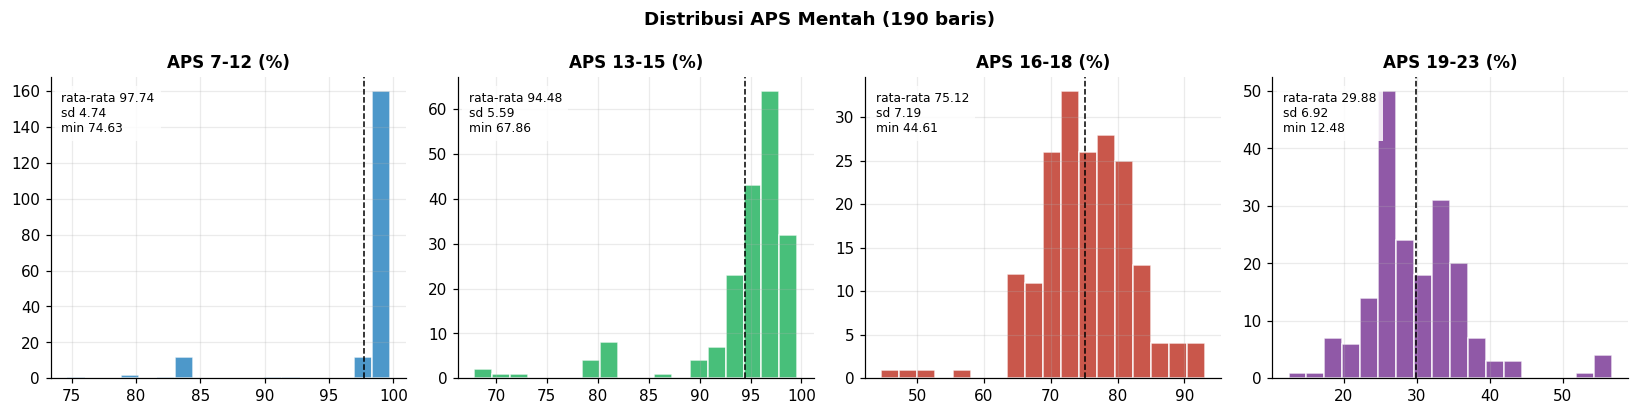

In [11]:
fig, axes = plt.subplots(1, 4, figsize=(15, 3.8))
for ax, col, color in zip(axes, aps_cols, ["#2E86C1", "#28B463", "#C0392B", "#7D3C98"]):
    values = raw[col].astype(float)
    ax.hist(values, bins=18, color=color, alpha=0.85, edgecolor="white")
    ax.axvline(values.mean(), color="black", linestyle="--", linewidth=1)
    ax.set_title(LABELS[col], fontsize=11)
    ax.text(0.03, 0.95, f"rata-rata {values.mean():.2f}\nsd {values.std():.2f}\nmin {values.min():.2f}",
            transform=ax.transAxes, va="top", fontsize=8, bbox=dict(facecolor="white", alpha=0.85, edgecolor="none"))
fig.suptitle("Distribusi APS Mentah (190 baris)", fontweight="bold")
fig.tight_layout()
save_fig(fig, "01_eda_raw", "distribusi_aps_mentah")

## 3. Preprocessing

### 3.1 Parsing Nilai Numerik

Aturan parsing:

1. Penanda angka sementara `(*)` dan `(**)` dihapus, tetapi statusnya disimpan di kolom `status_pdrb` agar tetap tercatat.
2. Desimal koma diubah menjadi titik.
3. Tanda `-` dan `...` diperlakukan sebagai nilai hilang (BPS memakainya untuk data yang tidak tersedia).

In [12]:
def to_number(series):
    text = series.astype("string").str.strip()
    text = text.str.replace(r"\(\*+\)", "", regex=True).str.strip().str.replace(",", ".", regex=False)
    text = text.replace({"-": pd.NA, "...": pd.NA, "": pd.NA})
    return pd.to_numeric(text, errors="coerce").astype(float)


df = raw.copy()
pdrb_text = df["pdrb_kapita"].astype("string")
df["status_pdrb"] = np.select([pdrb_text.str.contains(r"\(\*\*\)", regex=True, na=False),
                               pdrb_text.str.contains(r"\(\*\)", regex=True, na=False)],
                              ["sangat sementara", "sementara"], default="tetap")
NUMERIC_COLS = SHORT_NAMES[2:]
for col in NUMERIC_COLS:
    df[col] = to_number(df[col])
df = df.sort_values(["provinsi", "tahun"]).reset_index(drop=True)

missing_after_parse = df[NUMERIC_COLS].isna().sum()
missing_after_parse = missing_after_parse[missing_after_parse > 0]
print("Status PDRB:\n" + df["status_pdrb"].value_counts().to_string())
print("\nNilai hilang setelah parsing:\n" + missing_after_parse.rename(index=LABELS).to_string())
print(f"\nSemua kolom indikator kini numerik: {all(pd.api.types.is_numeric_dtype(df[c]) for c in NUMERIC_COLS)}")

Status PDRB:
status_pdrb
tetap               114
sementara            38
sangat sementara     38

Nilai hilang setelah parsing:
PDRB per Kapita (ribu Rp)               8
Pengeluaran Makanan per Kapita (Rp)    12
Air Minum Layak (%)                    12
Rumah Tangga Berlistrik (%)            12
Prevalensi Kurang Gizi (%)             12

Semua kolom indikator kini numerik: True


### 3.2 Imputasi Nilai Hilang

Aturan imputasi sesuai rancangan penelitian:

1. Isi dengan nilai **tahun sebelumnya** dari provinsi yang sama (forward fill).
2. Jika tidak ada, isi dengan nilai **tahun sesudahnya** dari provinsi yang sama (backward fill).
3. Jika provinsi tersebut tidak punya nilai sama sekali, isi dengan nilai **provinsi induk** pada tahun yang sama.

Setiap sel yang diisi dicatat sumbernya di log imputasi supaya transparan dan bisa dicantumkan di lampiran makalah.

In [13]:
original = df.copy()
lookup = original.set_index(["provinsi", "tahun"])
impute_log = []
for col in NUMERIC_COLS:
    for prov, group in original.groupby("provinsi"):
        series = group.set_index("tahun")[col]
        for year in series[series.isna()].index:
            earlier = series.loc[:year - 1].dropna()
            later = series.loc[year + 1:].dropna()
            if len(earlier):
                value, method, source = earlier.iloc[-1], "nilai tahun sebelumnya", f"{prov} {earlier.index[-1]}"
            elif len(later):
                value, method, source = later.iloc[0], "nilai tahun sesudahnya", f"{prov} {later.index[0]}"
            elif prov in DOB_PARENT and pd.notna(lookup.loc[(DOB_PARENT[prov], year), col]):
                value, method, source = lookup.loc[(DOB_PARENT[prov], year), col], "provinsi induk", f"{DOB_PARENT[prov]} {year}"
            else:
                continue
            df.loc[(df["provinsi"] == prov) & (df["tahun"] == year), col] = value
            impute_log.append({"provinsi": prov, "tahun": year, "kolom": col, "nilai_isi": value,
                               "metode": method, "sumber": source})
impute_log = pd.DataFrame(impute_log)
remaining = int(df[NUMERIC_COLS].isna().sum().sum())
print(f"Sel yang diimputasi : {len(impute_log)}")
print(f"Sisa nilai hilang   : {remaining}")
print("\nRingkasan metode:\n" + impute_log["metode"].value_counts().to_string())
print("\nRingkasan per kolom:\n" + impute_log.groupby("kolom").size().rename(index=LABELS).to_string())
impute_log.to_csv(DIRS["data"] / "log_imputasi.csv", index=False)
impute_log.head(12)

Sel yang diimputasi : 56
Sisa nilai hilang   : 0

Ringkasan metode:
metode
nilai tahun sesudahnya    56

Ringkasan per kolom:
kolom
Air Minum Layak (%)                    12
Rumah Tangga Berlistrik (%)            12
PDRB per Kapita (ribu Rp)               8
Pengeluaran Makanan per Kapita (Rp)    12
Prevalensi Kurang Gizi (%)             12


,provinsi,tahun,kolom,nilai_isi,metode,sumber
0,PAPUA BARAT DAYA,2021,pdrb_kapita,58450.0,nilai tahun sesudahnya,PAPUA BARAT DAYA 2023
1,PAPUA BARAT DAYA,2022,pdrb_kapita,58450.0,nilai tahun sesudahnya,PAPUA BARAT DAYA 2023
2,PAPUA PEGUNUNGAN,2021,pdrb_kapita,16870.0,nilai tahun sesudahnya,PAPUA PEGUNUNGAN 2023
3,PAPUA PEGUNUNGAN,2022,pdrb_kapita,16870.0,nilai tahun sesudahnya,PAPUA PEGUNUNGAN 2023
4,PAPUA SELATAN,2021,pdrb_kapita,58581.0,nilai tahun sesudahnya,PAPUA SELATAN 2023
5,PAPUA SELATAN,2022,pdrb_kapita,58581.0,nilai tahun sesudahnya,PAPUA SELATAN 2023
6,PAPUA TENGAH,2021,pdrb_kapita,103508.0,nilai tahun sesudahnya,PAPUA TENGAH 2023
7,PAPUA TENGAH,2022,pdrb_kapita,103508.0,nilai tahun sesudahnya,PAPUA TENGAH 2023
8,PAPUA BARAT DAYA,2021,pengeluaran_makanan,810863.0,nilai tahun sesudahnya,PAPUA BARAT DAYA 2024
9,PAPUA BARAT DAYA,2022,pengeluaran_makanan,810863.0,nilai tahun sesudahnya,PAPUA BARAT DAYA 2024


### 3.3 Penandaan Baris Analisis dan Fitur Turunan

Dua penanda dibuat untuk menjaga validitas analisis:

- `backcast_dob`: baris DOB pada tahun data salinan. Baris ini **dikeluarkan dari analisis inti** sehingga periode 2021-2023 dianalisis dengan 34 provinsi (batas wilayah lama) dan 2024-2025 dengan 38 provinsi.
- Transisi tahun 2023 ke 2024 untuk enam provinsi kelompok Papua juga **tidak dipakai** sebagai perubahan, karena perubahan nilainya mencerminkan pemekaran wilayah, bukan perubahan partisipasi sekolah.

Pemeriksaan di bawah juga menunjukkan di mana seluruh nilai hasil imputasi berada. Jika semuanya ada di baris salinan DOB, maka imputasi (termasuk pengisian dari tahun sesudahnya) tidak menyentuh data analisis inti dan tidak menimbulkan kebocoran informasi masa depan.

Fitur turunan berupa logaritma dibuat untuk PDRB per kapita dan pengeluaran makanan karena keduanya sangat menceng ke kanan.

In [14]:
df["backcast_dob"] = df["provinsi"].isin(DOB_PARENT) & df["tahun"].isin(backcast_years)
df["valid"] = ~df["backcast_dob"]
df["log_pdrb_kapita"] = np.log(df["pdrb_kapita"])
df["log_pengeluaran_makanan"] = np.log(df["pengeluaran_makanan"])
df = df.merge(PROVINCE_META, on="provinsi", how="left")

imputed_keys = set(zip(impute_log["provinsi"], impute_log["tahun"]))
imputed_in_core = [key for key in imputed_keys if bool(df.loc[(df["provinsi"] == key[0]) & (df["tahun"] == key[1]), "valid"].iloc[0])]
analysis = df[df["valid"]].copy().reset_index(drop=True)

print(f"Baris salinan DOB dikeluarkan : {int(df['backcast_dob'].sum())}")
print(f"Baris analisis inti           : {len(analysis)}")
print("Provinsi per tahun (analisis inti):\n" + analysis.groupby("tahun").size().to_string())
print(f"\nNilai imputasi yang jatuh di analisis inti: {len(imputed_in_core)}")
if not imputed_in_core:
    print("Seluruh nilai imputasi berada di baris salinan DOB, sehingga analisis inti bebas dari nilai imputasi.")

df.to_csv(DIRS["data"] / "dataset_bersih_lengkap.csv", index=False)
analysis.to_csv(DIRS["data"] / "dataset_analisis_inti.csv", index=False)

Baris salinan DOB dikeluarkan : 12
Baris analisis inti           : 178
Provinsi per tahun (analisis inti):
tahun
2021    34
2022    34
2023    34
2024    38
2025    38

Nilai imputasi yang jatuh di analisis inti: 0
Seluruh nilai imputasi berada di baris salinan DOB, sehingga analisis inti bebas dari nilai imputasi.


## 4. EDA Setelah Preprocessing

### 4.1 Statistik Deskriptif Data Bersih

Statistik dihitung pada data analisis inti (178 baris provinsi-tahun yang valid). Koefisien variasi (CV) menunjukkan indikator mana yang paling timpang antarprovinsi.

In [15]:
clean_describe = analysis[NUMERIC_COLS].describe().T
clean_describe["cv_persen"] = clean_describe["std"] / clean_describe["mean"] * 100
clean_describe["skewness"] = analysis[NUMERIC_COLS].skew()
clean_describe.index = [LABELS.get(c, c) for c in clean_describe.index]
save_table(clean_describe.round(3).reset_index().rename(columns={"index": "indikator"}), "02_eda_clean", "statistik_deskriptif_bersih")
clean_describe.round(2)

,count,mean,std,min,25%,50%,75%,max,cv_persen,skewness
APS 7-12 (%),178.0,98.44,3.69,74.63,99.00,99.39,99.54,99.76,3.74,-4.60
APS 13-15 (%),178.0,95.12,4.83,67.86,94.65,96.24,97.64,99.60,5.08,-3.69
APS 16-18 (%),178.0,75.55,7.00,44.61,71.54,75.74,79.67,93.03,9.26,-0.78
APS 19-23 (%),178.0,30.01,7.04,12.48,25.42,29.17,33.93,56.69,23.47,1.16
Pengangguran Terbuka (%),178.0,4.80,1.54,1.25,3.65,4.48,5.88,10.02,32.06,0.65
TPAK (%),178.0,69.43,3.99,62.52,66.66,69.20,71.04,89.46,5.75,1.47
Garis Kemiskinan (Rp),178.0,613508.74,145920.55,374774.30,508058.70,593870.00,692108.62,1325738.00,23.78,1.25
Penduduk Miskin (%),178.0,10.47,5.74,3.57,6.00,9.00,12.84,31.00,54.79,1.37
IPM,178.0,72.66,4.41,53.42,70.93,72.76,74.49,85.05,6.07,-0.72
Rata-rata Lama Sekolah (th),178.0,8.87,1.06,4.21,8.21,8.91,9.55,11.59,11.94,-0.75


### 4.2 Tren Nasional Partisipasi Sekolah

Rata-rata antarprovinsi untuk setiap jenjang APS per tahun. Grafik ini menjawab apakah partisipasi sekolah membaik secara umum, sebelum melihat apakah perbaikannya merata.

       aps_7_12  aps_13_15  aps_16_18  aps_19_23
tahun                                           
2021      98.83      95.55      75.22      29.74
2022      98.79      95.46      75.14      29.74
2023      98.82      95.56      75.50      30.72
2024      97.83      94.51      75.07      30.39
2025      98.06      94.66      76.75      29.48


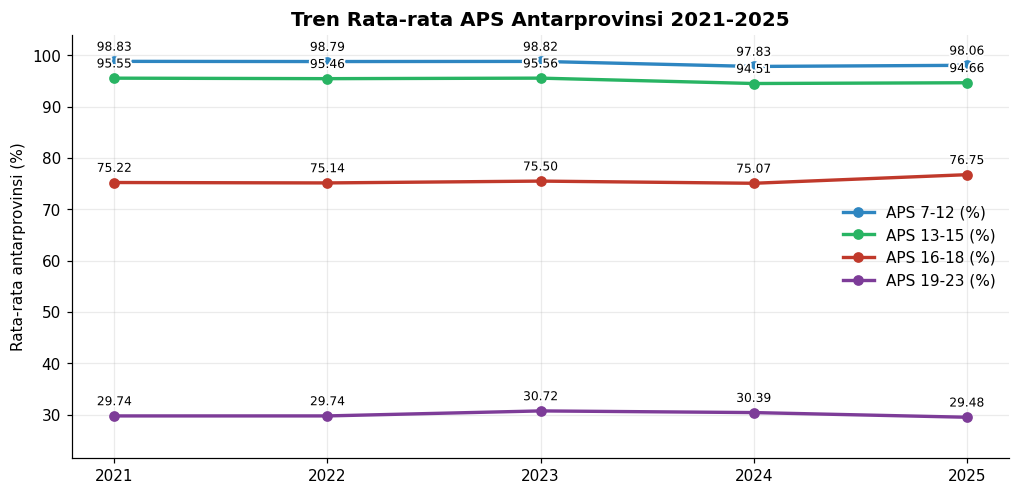

,tahun,aps_7_12,aps_13_15,aps_16_18,aps_19_23
0,2021,98.825,95.552,75.218,29.739
1,2022,98.791,95.456,75.139,29.741
2,2023,98.817,95.556,75.495,30.716
3,2024,97.833,94.510,75.071,30.392
4,2025,98.057,94.659,76.745,29.482


In [16]:
trend = analysis.groupby("tahun")[aps_cols].mean()
print(trend.round(2).to_string())
fig, ax = plt.subplots(figsize=(11, 5))
for col, color in zip(aps_cols, ["#2E86C1", "#28B463", "#C0392B", "#7D3C98"]):
    ax.plot(trend.index, trend[col], marker="o", linewidth=2.2, color=color, label=LABELS[col])
    for x, y in zip(trend.index, trend[col]):
        outlined(ax.annotate(f"{y:.2f}", (x, y), xytext=(0, 7), textcoords="offset points", ha="center", fontsize=8))
ax.set_xticks(trend.index)
ax.set_ylim(trend.min().min() - 8, 104)
ax.set_ylabel("Rata-rata antarprovinsi (%)")
ax.set_title("Tren Rata-rata APS Antarprovinsi 2021-2025")
ax.legend(loc="center right")
save_fig(fig, "02_eda_clean", "tren_nasional_aps")
save_table(trend.round(3).reset_index(), "02_eda_clean", "tren_nasional_aps")

### 4.3 Kesenjangan Antarprovinsi: Mana yang Tren Nyata, Mana yang Efek Pemekaran?

Simpangan baku APS 16-18 dihitung dengan dua cara:

- **Semua provinsi valid**: 34 provinsi pada 2021-2023 dan 38 provinsi pada 2024-2025.
- **32 provinsi dengan batas wilayah konsisten**: enam provinsi kelompok Papua dikeluarkan di semua tahun.

Jika kenaikan simpangan baku hanya muncul pada versi pertama, berarti kesenjangan yang tampak melebar sebagian besar adalah **kesenjangan yang tersingkap** oleh pemekaran: ketimpangan di dalam Papua sebelumnya tersembunyi di balik rata-rata provinsi induk.

                    cakupan  tahun    n  rata_rata  simpangan_baku  cv_persen  minimum  maksimum  rentang  rasio_p90_p10
       semua_provinsi_valid   2021 34.0     75.218           6.001      7.978    63.98     89.63    25.65          1.225
       semua_provinsi_valid   2022 34.0     75.139           5.848      7.782    65.93     89.95    24.02          1.216
       semua_provinsi_valid   2023 34.0     75.495           6.075      8.047    64.15     91.17    27.02          1.212
       semua_provinsi_valid   2024 38.0     75.071           7.525     10.024    47.65     90.36    42.71          1.174
       semua_provinsi_valid   2025 38.0     76.745           8.951     11.663    44.61     93.03    48.42          1.213
32_provinsi_batas_konsisten   2021 32.0     75.382           5.751      7.629    66.70     89.63    22.93          1.216
32_provinsi_batas_konsisten   2022 32.0     75.258           5.719      7.599    66.32     89.95    23.63          1.216
32_provinsi_batas_konsisten   20

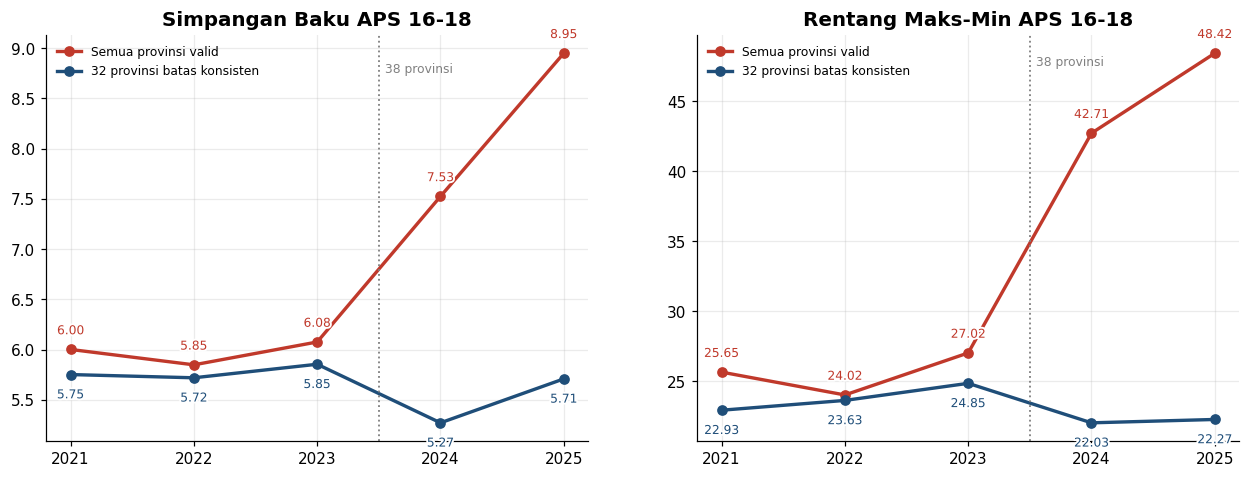


Perubahan simpangan baku 2021-2025, semua provinsi valid : +49.2%
Perubahan simpangan baku 2021-2025, 32 provinsi konsisten: -0.7%


In [17]:
def disparity(frame):
    values = frame[TARGET]
    return pd.Series({"n": len(values), "rata_rata": values.mean(), "simpangan_baku": values.std(),
                      "cv_persen": values.std() / values.mean() * 100, "minimum": values.min(), "maksimum": values.max(),
                      "rentang": values.max() - values.min(), "rasio_p90_p10": values.quantile(0.9) / values.quantile(0.1)})


disp_all = analysis.groupby("tahun").apply(disparity)
disp_fixed = analysis[~analysis["provinsi"].isin(SPLIT_GROUP)].groupby("tahun").apply(disparity)
disp_table = pd.concat({"semua_provinsi_valid": disp_all, "32_provinsi_batas_konsisten": disp_fixed}, names=["cakupan"]).reset_index()
print(disp_table.round(3).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
for frame, label, color, dy in [(disp_all, "Semua provinsi valid", COLORS["accent"], 8), (disp_fixed, "32 provinsi batas konsisten", COLORS["primary"], -9)]:
    axes[0].plot(frame.index, frame["simpangan_baku"], marker="o", linewidth=2.2, color=color, label=label)
    axes[1].plot(frame.index, frame["rentang"], marker="o", linewidth=2.2, color=color, label=label)
    for ax, col in [(axes[0], "simpangan_baku"), (axes[1], "rentang")]:
        for x, y in zip(frame.index, frame[col]):
            outlined(ax.annotate(f"{y:.2f}", (x, y), xytext=(0, dy), textcoords="offset points", ha="center",
                                 va="bottom" if dy > 0 else "top", fontsize=8, color=color))
for ax, title in zip(axes, ["Simpangan Baku APS 16-18", "Rentang Maks-Min APS 16-18"]):
    ax.axvline(2023.5, color="grey", linestyle=":", linewidth=1.2)
    ax.text(2023.55, ax.get_ylim()[1] * 0.97, "38 provinsi", fontsize=8, va="top", color="grey")
    ax.set_xticks(disp_all.index)
    ax.set_title(title)
    ax.legend(fontsize=8)
save_fig(fig, "02_eda_clean", "kesenjangan_tren_vs_pemekaran")
save_table(disp_table.round(4), "02_eda_clean", "metrik_kesenjangan")

sd_change_all = disp_all["simpangan_baku"].iloc[-1] / disp_all["simpangan_baku"].iloc[0] - 1
sd_change_fixed = disp_fixed["simpangan_baku"].iloc[-1] / disp_fixed["simpangan_baku"].iloc[0] - 1
print(f"\nPerubahan simpangan baku 2021-2025, semua provinsi valid : {sd_change_all:+.1%}")
print(f"Perubahan simpangan baku 2021-2025, 32 provinsi konsisten: {sd_change_fixed:+.1%}")

### 4.4 Peta Panas APS 16-18 per Provinsi dan Tahun

Provinsi diurutkan dari APS 16-18 tertinggi ke terendah pada 2025. Sel kosong adalah baris salinan DOB yang dikeluarkan dari analisis.

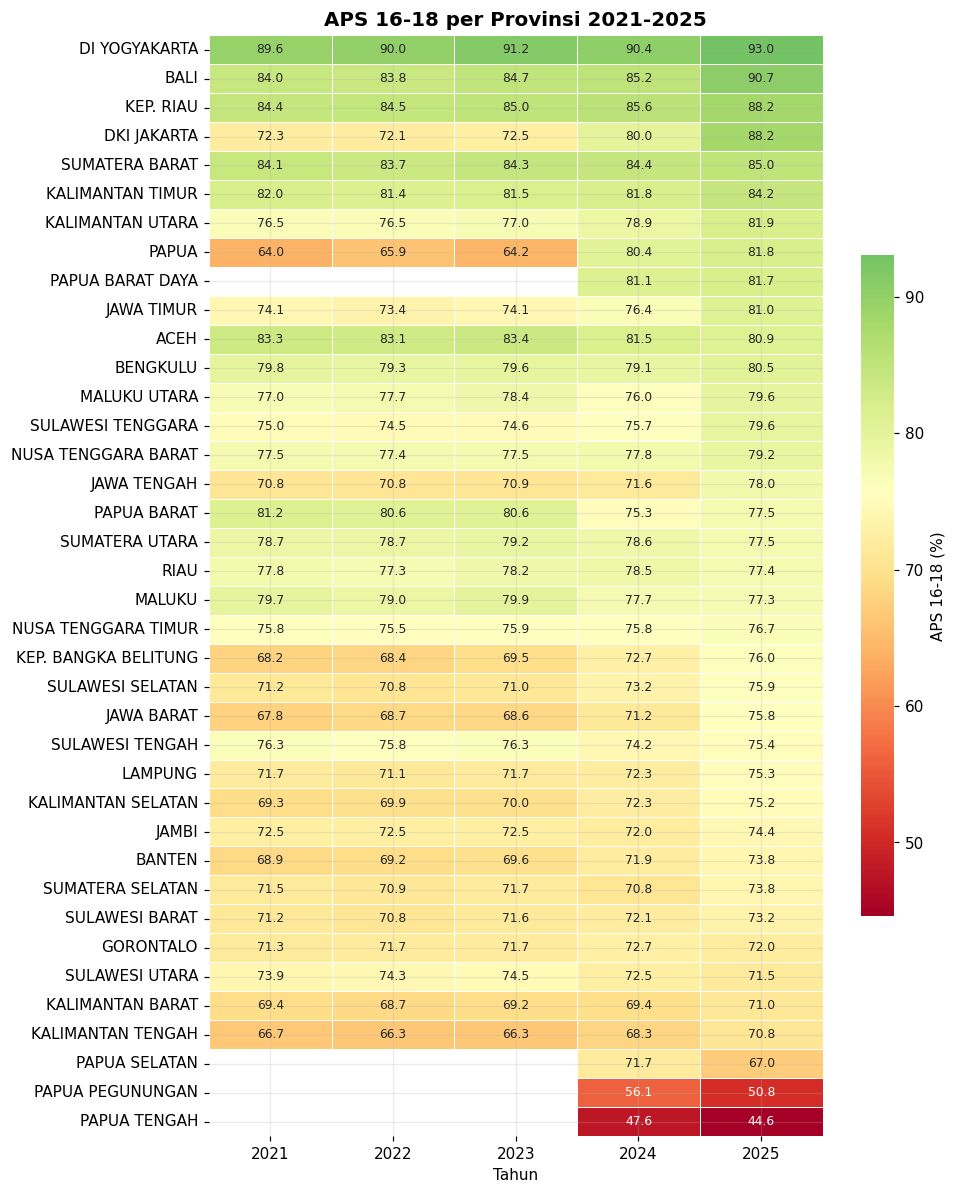

tahun,provinsi,2021,2022,2023,2024,2025
0,DI YOGYAKARTA,89.63,89.95,91.17,90.36,93.03
1,BALI,83.96,83.84,84.73,85.17,90.68
2,KEP. RIAU,84.40,84.54,84.97,85.56,88.24
3,DKI JAKARTA,72.32,72.10,72.50,79.95,88.22
4,SUMATERA BARAT,84.07,83.71,84.33,84.40,85.04
5,KALIMANTAN TIMUR,82.01,81.43,81.50,81.84,84.15
6,KALIMANTAN UTARA,76.50,76.50,77.03,78.89,81.93
7,PAPUA,63.98,65.93,64.15,80.38,81.78
8,PAPUA BARAT DAYA,NaN,NaN,NaN,81.14,81.70
9,JAWA TIMUR,74.14,73.40,74.07,76.44,80.96


In [18]:
heat = analysis.pivot(index="provinsi", columns="tahun", values=TARGET)
heat = heat.loc[heat[2025].sort_values(ascending=False).index]
fig, ax = plt.subplots(figsize=(9, 13))
sns.heatmap(heat, annot=True, fmt=".1f", cmap="RdYlGn", center=heat.stack().median(), linewidths=0.4,
            cbar_kws={"label": LABELS[TARGET], "shrink": 0.6}, ax=ax, annot_kws={"fontsize": 8})
ax.set_title("APS 16-18 per Provinsi 2021-2025")
ax.set_xlabel("Tahun")
ax.set_ylabel("")
save_fig(fig, "02_eda_clean", "heatmap_aps_16_18")
save_table(heat.round(2).reset_index(), "02_eda_clean", "matriks_aps_16_18")

### 4.5 Peringkat APS 16-18 Tahun 2025 per Wilayah

Warna batang menunjukkan wilayah kepulauan. Jika provinsi dengan APS rendah berkumpul di satu wilayah, itu menjadi indikasi awal adanya pola spasial yang akan diuji secara formal dengan Moran's I.

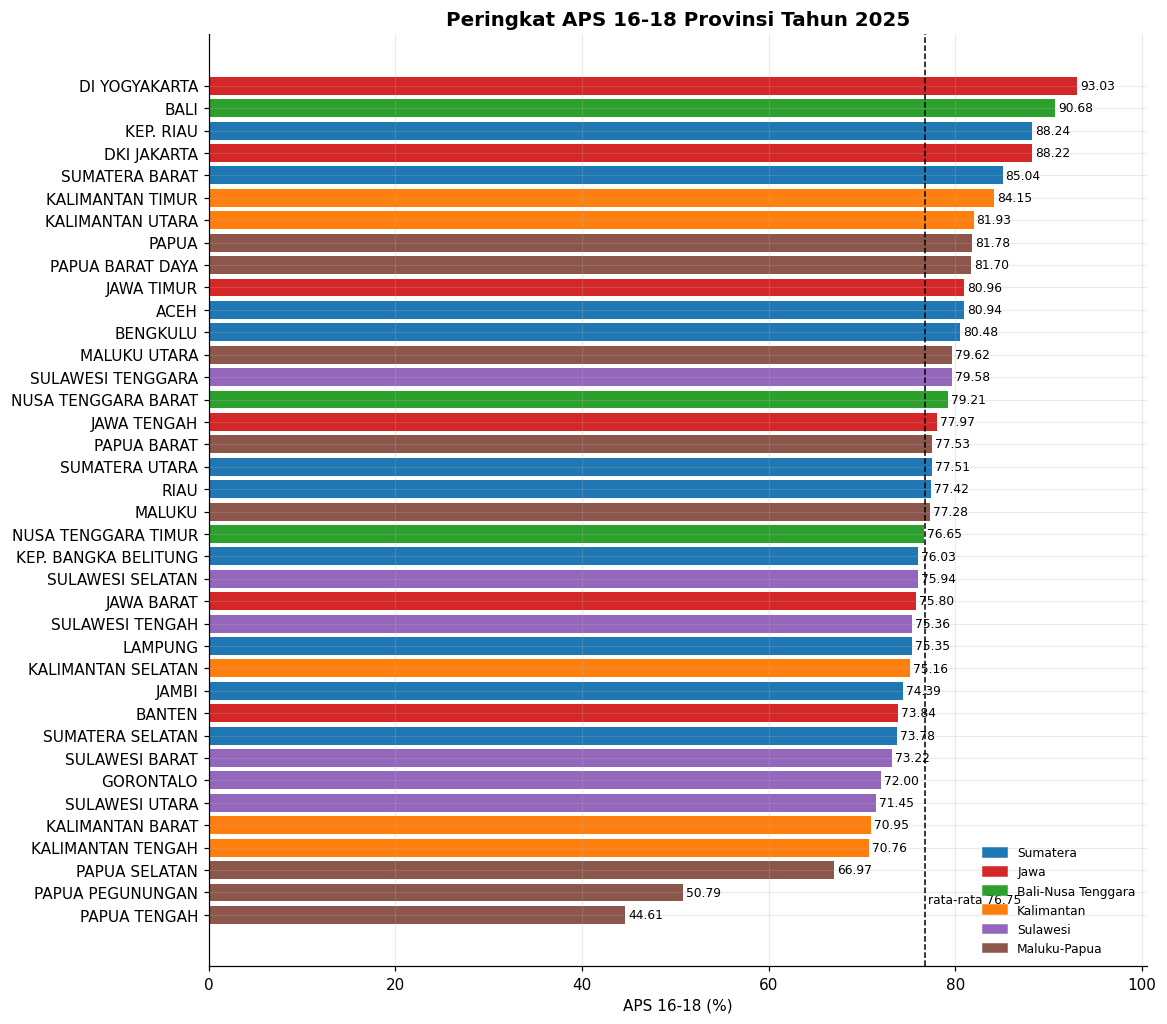

                    count   mean    min    max
wilayah                                       
Maluku-Papua            8  70.04  44.61  81.78
Sulawesi                6  74.59  71.45  79.58
Kalimantan              5  76.59  70.76  84.15
Sumatera               10  78.92  73.78  88.24
Jawa                    6  81.64  73.84  93.03
Bali-Nusa Tenggara      3  82.18  76.65  90.68


,wilayah,count,mean,min,max
0,Maluku-Papua,8,70.035,44.61,81.78
1,Sulawesi,6,74.592,71.45,79.58
2,Kalimantan,5,76.590,70.76,84.15
3,Sumatera,10,78.918,73.78,88.24
4,Jawa,6,81.637,73.84,93.03
5,Bali-Nusa Tenggara,3,82.180,76.65,90.68


In [19]:
latest = analysis[analysis["tahun"] == 2025].sort_values(TARGET).reset_index(drop=True)
national_mean_2025 = latest[TARGET].mean()
fig, ax = plt.subplots(figsize=(11, 11))
bars = ax.barh(latest["provinsi"], latest[TARGET], color=latest["wilayah"].map(REGION_COLORS))
ax.bar_label(bars, fmt="{:.2f}", fontsize=8, padding=2)
ax.axvline(national_mean_2025, color="black", linestyle="--", linewidth=1)
ax.text(national_mean_2025 + 0.3, 0.5, f"rata-rata {national_mean_2025:.2f}", fontsize=8)
ax.set_xlim(0, latest[TARGET].max() * 1.08)
ax.set_xlabel(LABELS[TARGET])
ax.set_title("Peringkat APS 16-18 Provinsi Tahun 2025")
ax.legend(handles=[Patch(color=c, label=r) for r, c in REGION_COLORS.items()], loc="lower right", fontsize=8)
save_fig(fig, "02_eda_clean", "peringkat_aps_2025")
region_summary = latest.groupby("wilayah")[TARGET].agg(["count", "mean", "min", "max"]).sort_values("mean")
print(region_summary.round(2).to_string())
save_table(region_summary.round(3).reset_index(), "02_eda_clean", "ringkasan_wilayah_2025")

### 4.6 Korelasi Spearman Antarindikator

Korelasi Spearman dipakai karena tahan terhadap outlier dan hubungan non-linear. Perhatikan korelasi APS 16-18 dengan HLS dan IPM: keduanya sangat tinggi karena HLS dihitung dari angka partisipasi sekolah per umur dan IPM memuat komponen pendidikan. Karena itu HLS dan IPM **tidak dipakai sebagai fitur** prediksi, agar model tidak "menebak target dari definisinya sendiri".

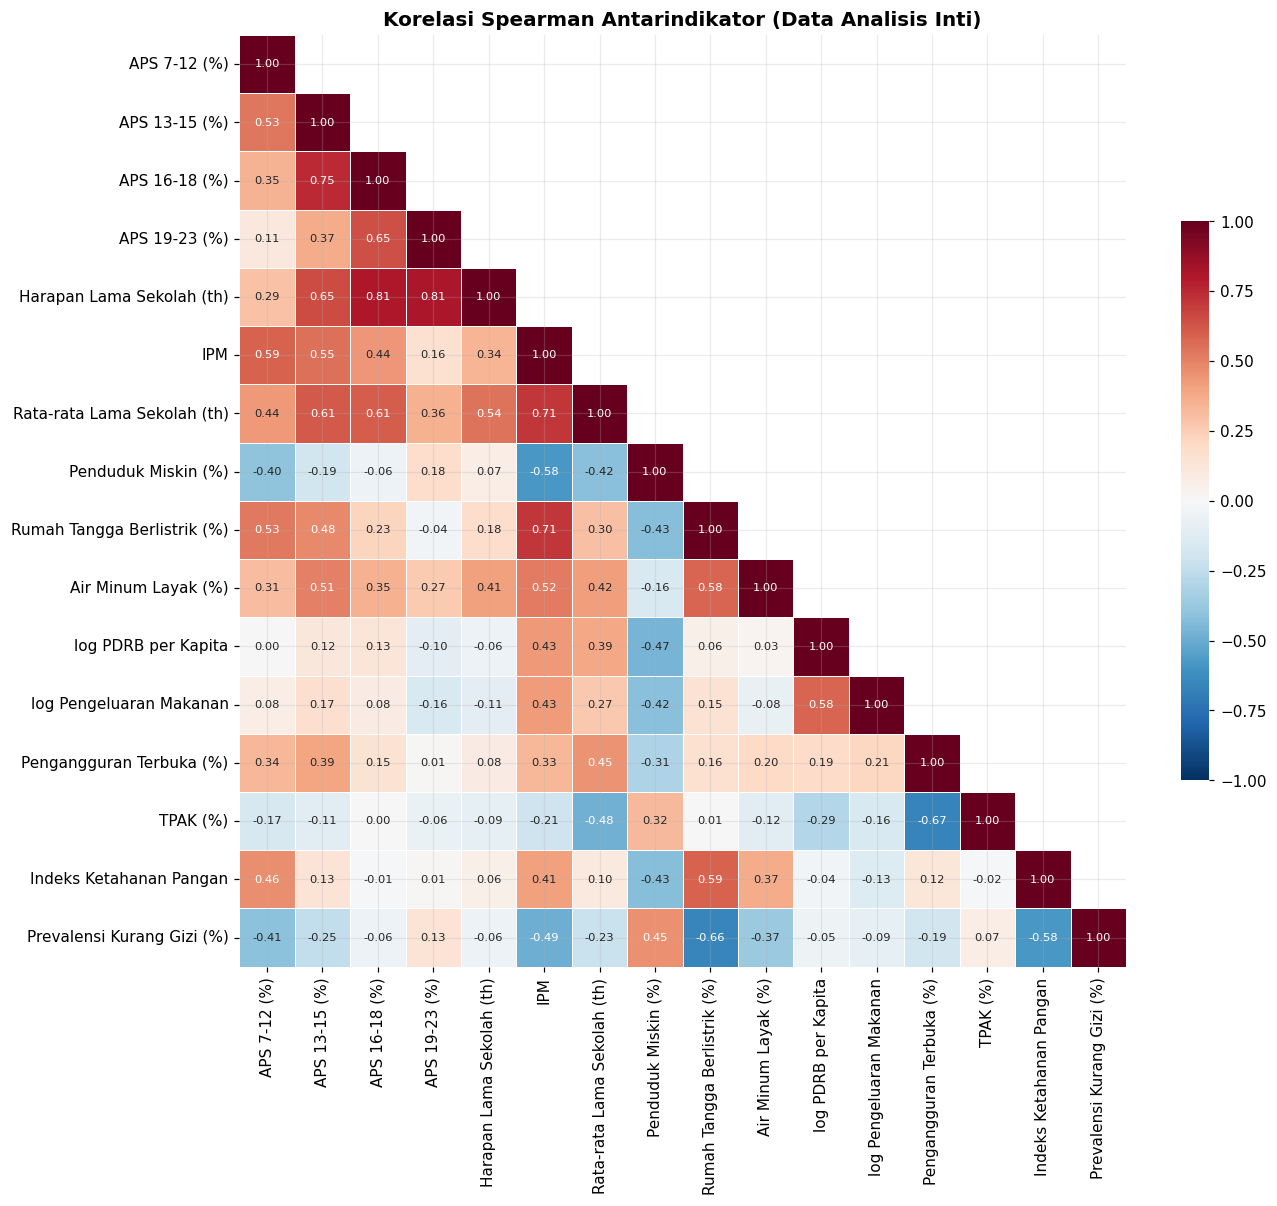

Korelasi Spearman terhadap APS 16-18:
Harapan Lama Sekolah (th)      0.805
APS 13-15 (%)                  0.747
APS 19-23 (%)                  0.646
Rata-rata Lama Sekolah (th)    0.609
IPM                            0.444
Air Minum Layak (%)            0.353
APS 7-12 (%)                   0.351
Rumah Tangga Berlistrik (%)    0.225
Pengangguran Terbuka (%)       0.146
log PDRB per Kapita            0.128
log Pengeluaran Makanan        0.082
Penduduk Miskin (%)           -0.062
Prevalensi Kurang Gizi (%)    -0.057
Indeks Ketahanan Pangan       -0.014
TPAK (%)                       0.003


,indikator,aps_7_12,aps_13_15,aps_16_18,aps_19_23,hls,ipm,rls,miskin,listrik,air_minum_layak,log_pdrb_kapita,log_pengeluaran_makanan,tpt,tpak,ikp,pou
0,aps_7_12,1.0000,0.5344,0.3506,0.1083,0.2928,0.5865,0.4357,-0.4041,0.5255,0.3091,0.0013,0.0770,0.3356,-0.1669,0.4615,-0.4123
1,aps_13_15,0.5344,1.0000,0.7466,0.3709,0.6516,0.5494,0.6113,-0.1887,0.4787,0.5063,0.1156,0.1709,0.3937,-0.1132,0.1350,-0.2466
2,aps_16_18,0.3506,0.7466,1.0000,0.6458,0.8051,0.4437,0.6092,-0.0620,0.2251,0.3532,0.1280,0.0823,0.1462,0.0030,-0.0140,-0.0573
3,aps_19_23,0.1083,0.3709,0.6458,1.0000,0.8129,0.1587,0.3583,0.1825,-0.0363,0.2653,-0.1020,-0.1632,0.0105,-0.0630,0.0116,0.1346
4,hls,0.2928,0.6516,0.8051,0.8129,1.0000,0.3365,0.5435,0.0724,0.1822,0.4076,-0.0606,-0.1092,0.0817,-0.0911,0.0606,-0.0588
5,ipm,0.5865,0.5494,0.4437,0.1587,0.3365,1.0000,0.7137,-0.5835,0.7127,0.5180,0.4331,0.4277,0.3306,-0.2089,0.4090,-0.4887
6,rls,0.4357,0.6113,0.6092,0.3583,0.5435,0.7137,1.0000,-0.4162,0.2972,0.4178,0.3854,0.2668,0.4519,-0.4784,0.0951,-0.2260
7,miskin,-0.4041,-0.1887,-0.0620,0.1825,0.0724,-0.5835,-0.4162,1.0000,-0.4260,-0.1593,-0.4662,-0.4209,-0.3053,0.3216,-0.4255,0.4531
8,listrik,0.5255,0.4787,0.2251,-0.0363,0.1822,0.7127,0.2972,-0.4260,1.0000,0.5802,0.0618,0.1514,0.1607,0.0062,0.5925,-0.6583
9,air_minum_layak,0.3091,0.5063,0.3532,0.2653,0.4076,0.5180,0.4178,-0.1593,0.5802,1.0000,0.0296,-0.0767,0.1995,-0.1163,0.3692,-0.3729


In [20]:
corr_cols = ["aps_7_12", "aps_13_15", "aps_16_18", "aps_19_23", "hls", "ipm", "rls", "miskin", "listrik", "air_minum_layak",
             "log_pdrb_kapita", "log_pengeluaran_makanan", "tpt", "tpak", "ikp", "pou"]
corr = analysis[corr_cols].corr(method="spearman")
corr_labeled = corr.rename(index=LABELS, columns=LABELS)
fig, ax = plt.subplots(figsize=(13, 11))
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
sns.heatmap(corr_labeled, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, linewidths=0.4,
            annot_kws={"fontsize": 7.5}, cbar_kws={"shrink": 0.6}, ax=ax)
ax.set_title("Korelasi Spearman Antarindikator (Data Analisis Inti)")
save_fig(fig, "02_eda_clean", "korelasi_spearman")
target_corr = corr[TARGET].drop(TARGET).sort_values(key=np.abs, ascending=False)
print("Korelasi Spearman terhadap APS 16-18:\n" + target_corr.rename(index=LABELS).round(3).to_string())
save_table(corr.round(4).reset_index().rename(columns={"index": "indikator"}), "02_eda_clean", "korelasi_spearman")

### 4.7 Hubungan APS 16-18 dengan Kondisi Pendukung (2025)

Empat kondisi pendukung yang paling relevan untuk kebijakan diplot terhadap APS 16-18. Garis merah adalah regresi linear sederhana, dan nilai rho Spearman beserta p-value ditampilkan di setiap panel.

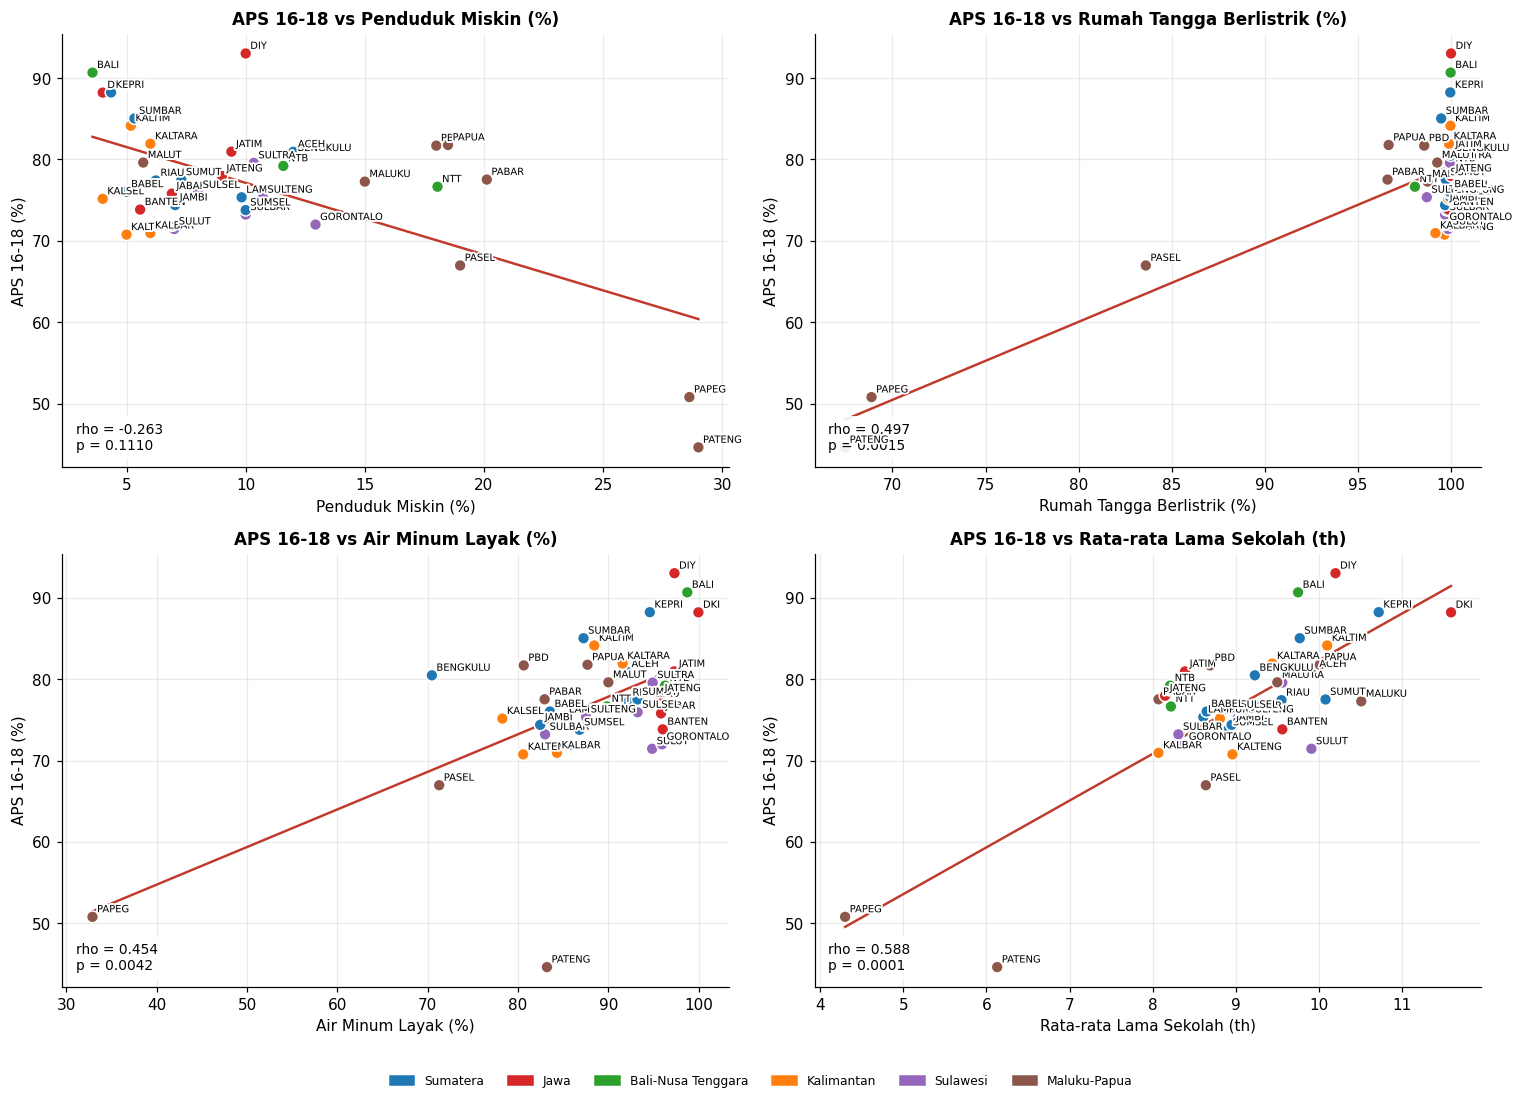

In [21]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
for ax, col in zip(axes.ravel(), ["miskin", "listrik", "air_minum_layak", "rls"]):
    ax.scatter(latest[col], latest[TARGET], c=latest["wilayah"].map(REGION_COLORS), s=60, edgecolors="white", zorder=3)
    slope, intercept = np.polyfit(latest[col], latest[TARGET], 1)
    xs = np.linspace(latest[col].min(), latest[col].max(), 50)
    ax.plot(xs, slope * xs + intercept, color=COLORS["accent"], linewidth=1.6)
    rho, pval = stats.spearmanr(latest[col], latest[TARGET])
    ax.text(0.02, 0.04, f"rho = {rho:.3f}\np = {pval:.4f}", transform=ax.transAxes, fontsize=9,
            bbox=dict(facecolor="white", alpha=0.9, edgecolor="none"))
    for _, row in latest.iterrows():
        outlined(ax.annotate(row["kode"], (row[col], row[TARGET]), xytext=(3, 3), textcoords="offset points", fontsize=6.5))
    ax.set_xlabel(LABELS[col])
    ax.set_ylabel(LABELS[TARGET])
    ax.set_title(f"APS 16-18 vs {LABELS[col]}", fontsize=11)
fig.legend(handles=[Patch(color=c, label=r) for r, c in REGION_COLORS.items()], loc="lower center", ncol=6, fontsize=8)
fig.tight_layout(rect=(0, 0.04, 1, 1))
save_fig(fig, "02_eda_clean", "scatter_kondisi_pendukung_2025")

## 5. Spatial Autocorrelation: Global Moran's I dan LISA

### 5.1 Matriks Bobot Spasial K-Nearest Neighbors

Koordinat ibu kota diproyeksikan ke kilometer (proyeksi equirectangular di lintang tengah Indonesia) agar jarak timur-barat dan utara-selatan sebanding. Setiap provinsi dihubungkan dengan k = 4 tetangga terdekat, lalu bobot distandarkan per baris sehingga spatial lag adalah rata-rata nilai tetangga.

Matriks bobot dibangun terpisah per tahun karena jumlah provinsi berbeda (34 pada 2021-2023, 38 pada 2024-2025).

Rata-rata jarak ke tetangga (2025): 412 km


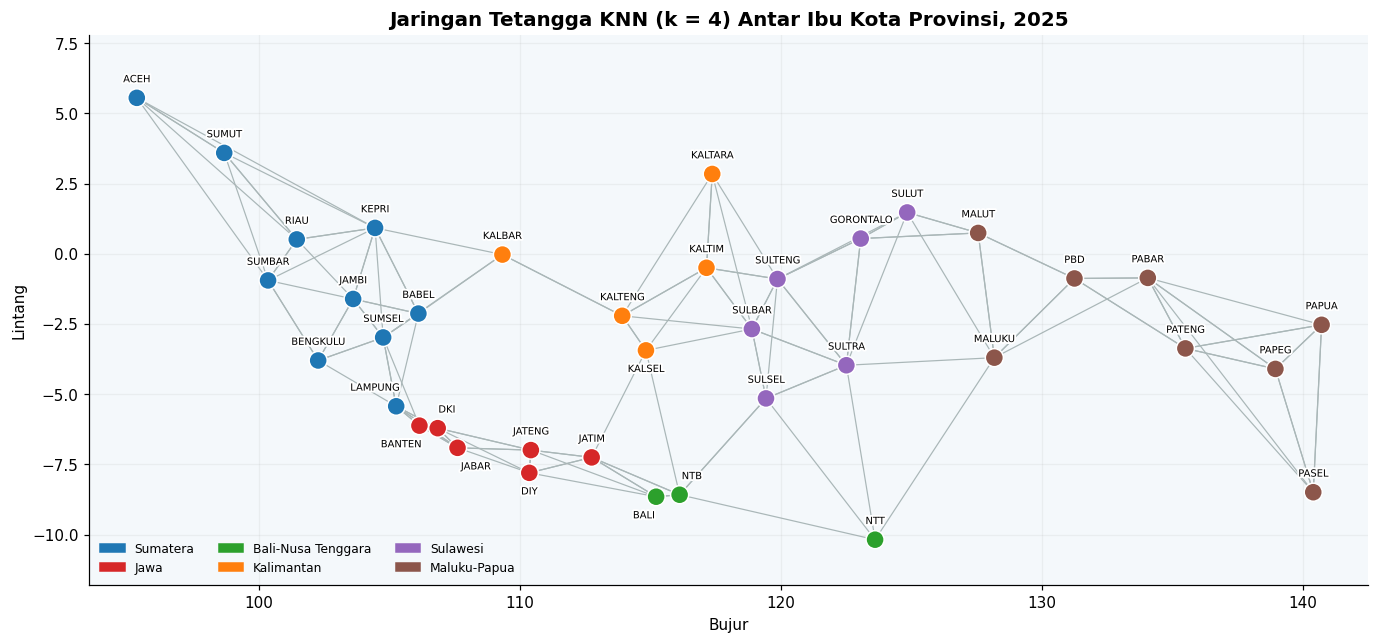

,provinsi,tetangga_knn,jarak_rata2_tetangga_km
0,ACEH,"SUMUT, RIAU, SUMBAR, KEPRI",839.9
1,BALI,"NTB, JATIM, DIY, JATENG",382.2
2,BANTEN,"DKI, LAMPUNG, JABAR, SUMSEL",192.0
3,BENGKULU,"JAMBI, SUMSEL, LAMPUNG, SUMBAR",333.7
4,DI YOGYAKARTA,"JATENG, JATIM, JABAR, DKI",278.0
5,DKI JAKARTA,"BANTEN, JABAR, LAMPUNG, JATENG",199.0
6,GORONTALO,"SULUT, SULTENG, MALUT, SULTRA",403.8
7,JAMBI,"SUMSEL, BABEL, BENGKULU, KEPRI",265.4
8,JAWA BARAT,"DKI, BANTEN, LAMPUNG, JATENG",230.0
9,JAWA TENGAH,"DIY, JATIM, JABAR, DKI",267.4


In [22]:
def project_km(frame):
    lat0 = np.radians(-2.5)
    return np.column_stack([frame["lon"].to_numpy() * 111.32 * np.cos(lat0), frame["lat"].to_numpy() * 110.57])


def build_weights(frame, k=K_NEIGHBORS):
    weights = KNN.from_array(project_km(frame), k=k)
    weights.transform = "r"
    return weights


YEARS = sorted(analysis["tahun"].unique())
year_frames = {year: analysis[analysis["tahun"] == year].reset_index(drop=True) for year in YEARS}
year_weights = {year: build_weights(frame) for year, frame in year_frames.items()}

frame_2025, w_2025 = year_frames[2025], year_weights[2025]
neighbor_table = pd.DataFrame({
    "provinsi": frame_2025["provinsi"],
    "tetangga_knn": [", ".join(frame_2025.loc[w_2025.neighbors[i], "kode"]) for i in range(len(frame_2025))],
})
dist_rows = []
xy = project_km(frame_2025)
for i in range(len(frame_2025)):
    dist_rows.append(np.mean([np.linalg.norm(xy[i] - xy[j]) for j in w_2025.neighbors[i]]))
neighbor_table["jarak_rata2_tetangga_km"] = np.round(dist_rows, 1)
print(f"Rata-rata jarak ke tetangga (2025): {np.mean(dist_rows):,.0f} km")
save_table(neighbor_table, "03_spatial", "daftar_tetangga_knn_2025")

fig, ax = plt.subplots(figsize=(15, 6.5))
for i in range(len(frame_2025)):
    for j in w_2025.neighbors[i]:
        ax.plot([frame_2025.loc[i, "lon"], frame_2025.loc[j, "lon"]], [frame_2025.loc[i, "lat"], frame_2025.loc[j, "lat"]],
                color="#AAB7B8", linewidth=0.8, zorder=1)
province_map(ax, frame_2025, frame_2025["wilayah"].map(REGION_COLORS), size=140,
             title=f"Jaringan Tetangga KNN (k = {K_NEIGHBORS}) Antar Ibu Kota Provinsi, 2025")
ax.legend(handles=[Patch(color=c, label=r) for r, c in REGION_COLORS.items()], loc="lower left", fontsize=8, ncol=3)
save_fig(fig, "03_spatial", "jaringan_tetangga_knn")
neighbor_table.head(10)

### 5.2 Global Moran's I per Tahun

Moran's I mengukur apakah provinsi dengan nilai serupa cenderung bertetangga. Nilai positif berarti pengelompokan (provinsi rendah dikelilingi provinsi rendah), nilai mendekati E[I] = -1/(n-1) berarti acak. Signifikansi diuji dengan **9.999 permutasi acak**, yang tidak mengasumsikan distribusi normal.

Uji dilakukan untuk APS 16-18 (target utama) dan APS 19-23 (pembanding jenjang pendidikan tinggi).

 tahun  variabel  n  moran_I     E_I  z_sim  p_sim  p_normal  signifikan
  2021 aps_16_18 34   0.1156 -0.0303 1.4238 0.0858    0.1557       False
  2021 aps_19_23 34   0.1118 -0.0303 1.5180 0.0722    0.1669       False
  2022 aps_16_18 34   0.1257 -0.0303 1.5251 0.0713    0.1292       False
  2022 aps_19_23 34   0.1221 -0.0303 1.6166 0.0630    0.1381       False
  2023 aps_16_18 34   0.1165 -0.0303 1.4404 0.0818    0.1533       False
  2023 aps_19_23 34   0.1266 -0.0303 1.6466 0.0591    0.1270       False
  2024 aps_16_18 38   0.1117 -0.0270 1.4841 0.0766    0.1626       False
  2024 aps_19_23 38   0.0585 -0.0270 0.8809 0.1820    0.3893       False
  2025 aps_16_18 38   0.1844 -0.0270 2.2884 0.0223    0.0333        True
  2025 aps_19_23 38   0.0111 -0.0270 0.3878 0.3350    0.7015       False


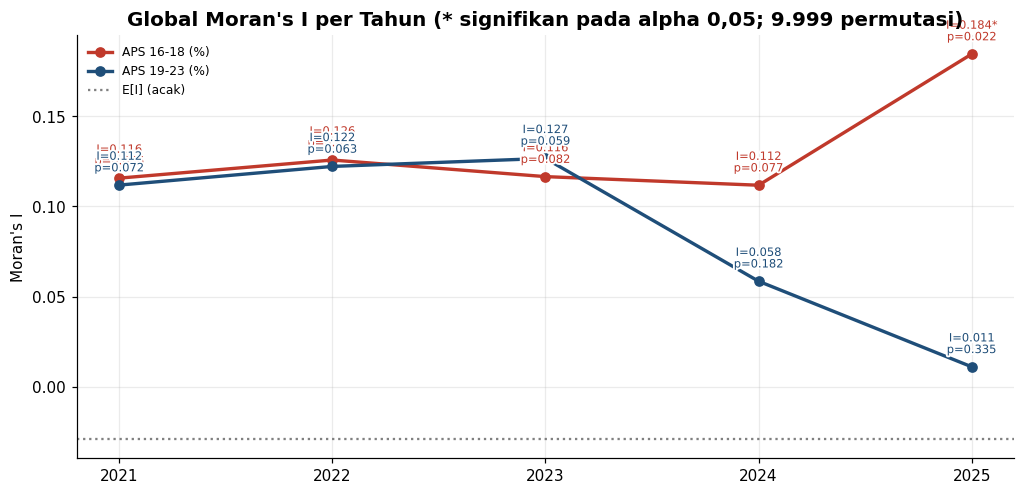

In [23]:
moran_rows = []
for year in YEARS:
    frame, weights = year_frames[year], year_weights[year]
    for col in [TARGET, "aps_19_23"]:
        np.random.seed(SEED)
        result = Moran(frame[col].to_numpy(), weights, permutations=PERMUTATIONS)
        moran_rows.append({"tahun": year, "variabel": col, "n": len(frame), "moran_I": result.I, "E_I": result.EI,
                           "z_sim": result.z_sim, "p_sim": result.p_sim, "p_normal": result.p_norm,
                           "signifikan": result.p_sim < ALPHA})
moran_table = pd.DataFrame(moran_rows)
print(moran_table.round(4).to_string(index=False))
save_table(moran_table.round(5), "03_spatial", "global_moran_per_tahun")

fig, ax = plt.subplots(figsize=(11, 5))
for col, color in [(TARGET, COLORS["accent"]), ("aps_19_23", COLORS["primary"])]:
    part = moran_table[moran_table["variabel"] == col]
    ax.plot(part["tahun"], part["moran_I"], marker="o", linewidth=2.2, color=color, label=LABELS[col])
    for _, row in part.iterrows():
        star = "*" if row["signifikan"] else ""
        outlined(ax.annotate(f"I={row['moran_I']:.3f}{star}\np={row['p_sim']:.3f}", (row["tahun"], row["moran_I"]),
                             xytext=(0, 9), textcoords="offset points", ha="center", fontsize=7.5, color=color))
ax.axhline(moran_table["E_I"].mean(), color="grey", linestyle=":", label="E[I] (acak)")
ax.set_xticks(YEARS)
ax.set_ylabel("Moran's I")
ax.set_title("Global Moran's I per Tahun (* signifikan pada alpha 0,05; 9.999 permutasi)")
ax.legend(fontsize=8)
save_fig(fig, "03_spatial", "global_moran_per_tahun")

### 5.3 Uji Sensitivitas Jumlah Tetangga

Kesimpulan spasial yang baik tidak boleh bergantung pada satu pilihan k. Moran's I APS 16-18 dihitung ulang untuk k = 3, 4, 5, dan 6. Angka di dalam sel adalah nilai I, dan tanda bintang menandai p < 0,05.

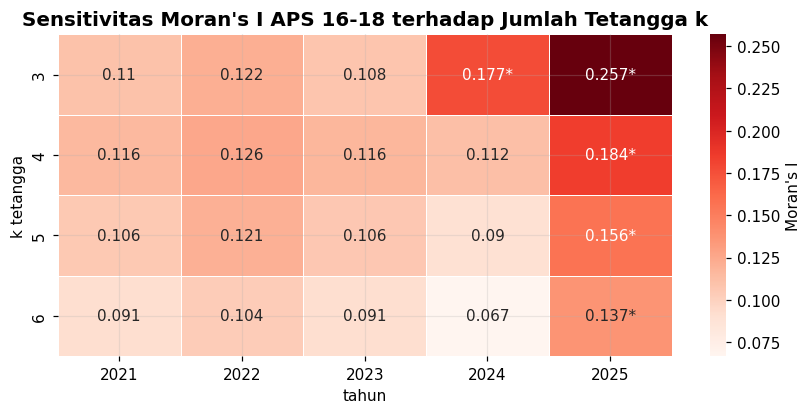

Rentang Moran's I per tahun lintas k:
tahun   2021   2022   2023   2024   2025
min    0.091  0.104  0.091  0.067  0.137
max    0.116  0.126  0.116  0.177  0.257


In [24]:
sens_rows = []
for k in K_SENSITIVITY:
    for year in YEARS:
        np.random.seed(SEED)
        result = Moran(year_frames[year][TARGET].to_numpy(), build_weights(year_frames[year], k), permutations=999)
        sens_rows.append({"k": k, "tahun": year, "moran_I": result.I, "p_sim": result.p_sim})
sens_table = pd.DataFrame(sens_rows)
save_table(sens_table.round(5), "03_spatial", "sensitivitas_k_moran")
sens_I = sens_table.pivot(index="k", columns="tahun", values="moran_I")
sens_p = sens_table.pivot(index="k", columns="tahun", values="p_sim")
annot = sens_I.round(3).astype(str) + np.where(sens_p < ALPHA, "*", "")
fig, ax = plt.subplots(figsize=(9, 3.8))
sns.heatmap(sens_I, annot=annot, fmt="", cmap="Reds", linewidths=0.5, cbar_kws={"label": "Moran's I"}, ax=ax)
ax.set_title("Sensitivitas Moran's I APS 16-18 terhadap Jumlah Tetangga k")
ax.set_ylabel("k tetangga")
save_fig(fig, "03_spatial", "sensitivitas_k_moran")
print("Rentang Moran's I per tahun lintas k:\n" + sens_I.agg(["min", "max"]).round(3).to_string())

### 5.4 Moran's I untuk Perubahan APS 16-18

Selain level, perubahan tahunan (delta) juga diuji. Pertanyaannya: apakah kenaikan atau penurunan partisipasi sekolah cenderung terjadi bersamaan pada provinsi yang bertetangga? Jika ya, dinamika pendidikan bersifat regional, sehingga intervensi lintas provinsi lebih masuk akal daripada intervensi terisolasi.

Hanya transisi dengan batas wilayah konsisten yang dipakai.

  periode  n  rata2_delta  moran_I_delta  z_sim  p_sim  signifikan
2021-2022 34      -0.0788        -0.0120 0.1999 0.3846       False
2022-2023 34       0.3559        -0.0221 0.0879 0.4485       False
2023-2024 32       0.5722         0.1652 1.9638 0.0346        True
2024-2025 38       1.6747         0.4260 4.6185 0.0002        True


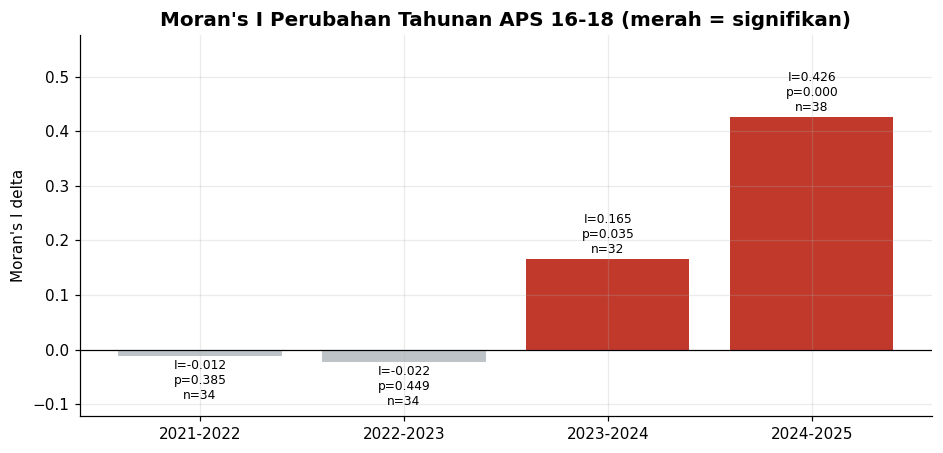

In [25]:
def valid_transition(prov, year):
    return not (prov in SPLIT_GROUP and year + 1 == SPLIT_YEAR)


change_rows = []
for year in YEARS[:-1]:
    current = year_frames[year][["provinsi", "lon", "lat", TARGET]]
    nxt = year_frames[year + 1][["provinsi", TARGET]].rename(columns={TARGET: "next"})
    pair = current.merge(nxt, on="provinsi")
    pair = pair[[valid_transition(p, year) for p in pair["provinsi"]]].reset_index(drop=True)
    pair["delta"] = pair["next"] - pair[TARGET]
    np.random.seed(SEED)
    result = Moran(pair["delta"].to_numpy(), build_weights(pair), permutations=PERMUTATIONS)
    change_rows.append({"periode": f"{year}-{year + 1}", "n": len(pair), "rata2_delta": pair["delta"].mean(),
                        "moran_I_delta": result.I, "z_sim": result.z_sim, "p_sim": result.p_sim, "signifikan": result.p_sim < ALPHA})
change_moran = pd.DataFrame(change_rows)
print(change_moran.round(4).to_string(index=False))
save_table(change_moran.round(5), "03_spatial", "moran_perubahan_aps")

fig, ax = plt.subplots(figsize=(10, 4.5))
bars = ax.bar(change_moran["periode"], change_moran["moran_I_delta"],
              color=np.where(change_moran["signifikan"], COLORS["accent"], "#BDC3C7"))
ax.bar_label(bars, labels=[f"I={i:.3f}\np={p:.3f}\nn={n}" for i, p, n in
                           zip(change_moran["moran_I_delta"], change_moran["p_sim"], change_moran["n"])], fontsize=8, padding=2)
ax.axhline(0, color="black", linewidth=0.8)
ax.set_ylim(min(0, change_moran["moran_I_delta"].min()) - 0.1, change_moran["moran_I_delta"].max() + 0.15)
ax.set_title("Moran's I Perubahan Tahunan APS 16-18 (merah = signifikan)")
ax.set_ylabel("Moran's I delta")
save_fig(fig, "03_spatial", "moran_perubahan_aps")

### 5.5 Moran Scatterplot 2025

Sumbu x adalah APS 16-18 terstandardisasi, sumbu y adalah spatial lag-nya (rata-rata tetangga, juga terstandardisasi). Kemiringan garis regresi sama dengan Moran's I. Empat kuadran menentukan regime spasial setiap provinsi: HH, LL, LH (rendah dikelilingi tinggi), dan HL (tinggi dikelilingi rendah).

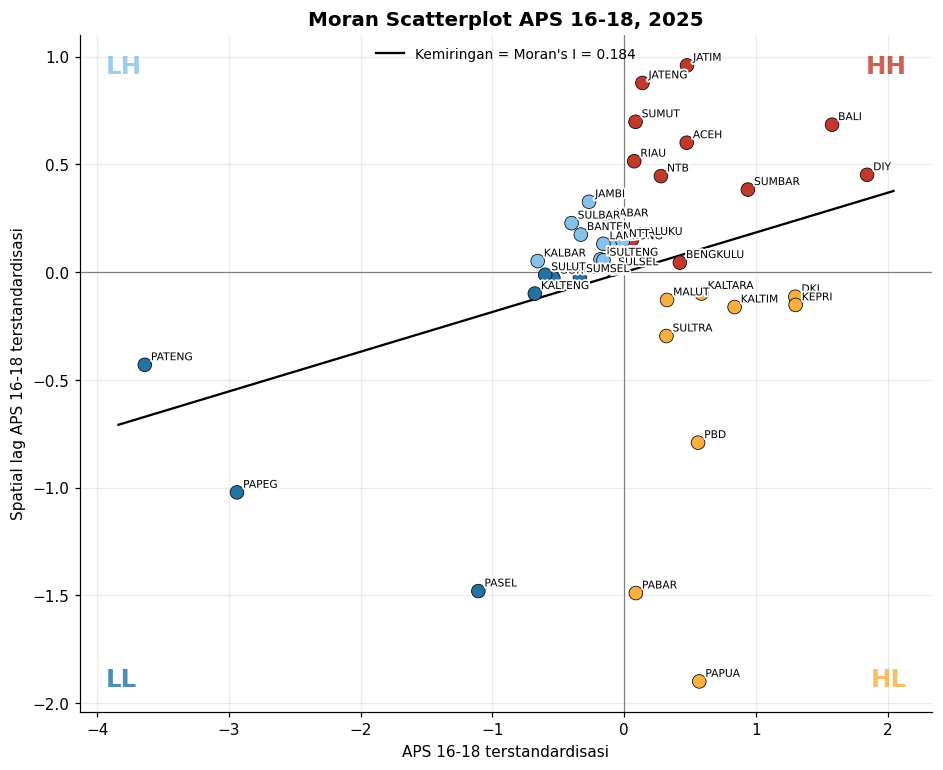

Jumlah provinsi per kuadran 2025:
HH    11
LH    11
HL     9
LL     7


In [26]:
z = (frame_2025[TARGET] - frame_2025[TARGET].mean()) / frame_2025[TARGET].std(ddof=0)
z_lag = w_2025.sparse @ z.to_numpy()
quadrant = np.select([(z >= 0) & (z_lag >= 0), (z < 0) & (z_lag >= 0), (z < 0) & (z_lag < 0)], ["HH", "LH", "LL"], default="HL")
I_2025 = moran_table.query("tahun == 2025 and variabel == @TARGET")["moran_I"].iloc[0]
fig, ax = plt.subplots(figsize=(10, 8))
ax.scatter(z, z_lag, c=[LISA_COLORS[q] for q in quadrant], s=80, edgecolors="black", linewidths=0.5, zorder=3)
xs = np.linspace(z.min() - 0.2, z.max() + 0.2, 50)
ax.plot(xs, I_2025 * xs, color="black", linewidth=1.5, label=f"Kemiringan = Moran's I = {I_2025:.3f}")
ax.axhline(0, color="grey", linewidth=0.8)
ax.axvline(0, color="grey", linewidth=0.8)
for label, (x, y) in {"HH": (0.97, 0.97), "LH": (0.03, 0.97), "LL": (0.03, 0.03), "HL": (0.97, 0.03)}.items():
    ax.text(x, y, label, transform=ax.transAxes, ha="right" if x > 0.5 else "left", va="top" if y > 0.5 else "bottom",
            fontsize=16, fontweight="bold", color=LISA_COLORS[label], alpha=0.8)
for xi, yi, name in zip(z, z_lag, frame_2025["kode"]):
    outlined(ax.annotate(name, (xi, yi), xytext=(4, 3), textcoords="offset points", fontsize=7))
ax.set_xlabel("APS 16-18 terstandardisasi")
ax.set_ylabel("Spatial lag APS 16-18 terstandardisasi")
ax.set_title("Moran Scatterplot APS 16-18, 2025")
ax.legend(loc="upper center", fontsize=9)
save_fig(fig, "03_spatial", "moran_scatterplot_2025")
print("Jumlah provinsi per kuadran 2025:\n" + pd.Series(quadrant).value_counts().to_string())

### 5.6 Local Indicators of Spatial Association (LISA)

LISA (Local Moran's I) menghitung kontribusi setiap provinsi terhadap pengelompokan global, lalu menguji signifikansinya dengan **9.999 permutasi bersyarat**. Karena ada 34-38 uji lokal sekaligus, p-value juga dikoreksi dengan **Benjamini-Hochberg (FDR)** untuk mengendalikan positif palsu. Dua tingkat bukti dilaporkan:

- signifikan pada p < 0,05 (konvensional), dan
- signifikan setelah koreksi FDR (bukti paling kuat).

Spatial lag dan regime spasial (kuadran) setiap provinsi-tahun juga disimpan karena dipakai sebagai item association rule mining dan sebagai fitur forecasting.

In [27]:
QUAD = {1: "HH", 2: "LH", 3: "LL", 4: "HL"}
lisa_frames = []
for year in YEARS:
    frame, weights = year_frames[year].copy(), year_weights[year]
    np.random.seed(SEED)
    local = Moran_Local(frame[TARGET].to_numpy(), weights, permutations=PERMUTATIONS)
    frame["local_I"] = local.Is
    frame["regime"] = [QUAD[q] for q in local.q]
    frame["p_sim"] = local.p_sim
    frame["q_fdr"] = bh_fdr(local.p_sim)
    frame["sig_005"] = frame["p_sim"] < ALPHA
    frame["sig_fdr"] = frame["q_fdr"] < ALPHA
    frame["cluster"] = np.where(frame["sig_005"], frame["regime"], "Tidak signifikan")
    frame["w_aps_16_18"] = weights.sparse @ frame[TARGET].to_numpy()
    frame["w_miskin"] = weights.sparse @ frame["miskin"].to_numpy()
    lisa_frames.append(frame)
lisa_all = pd.concat(lisa_frames, ignore_index=True)
lisa_cols = ["provinsi", "kode", "tahun", TARGET, "w_aps_16_18", "local_I", "regime", "p_sim", "q_fdr", "sig_005", "sig_fdr", "cluster"]
save_table(lisa_all[lisa_cols].round(5), "03_spatial", "lisa_semua_tahun")

lisa_summary = lisa_all.groupby(["tahun", "cluster"]).size().unstack(fill_value=0)
print("Jumlah provinsi per cluster LISA (p < 0,05):\n" + lisa_summary.to_string())
print("\nJumlah provinsi signifikan setelah FDR per tahun:\n" + lisa_all.groupby("tahun")["sig_fdr"].sum().to_string())
lisa_2025 = lisa_all[lisa_all["tahun"] == 2025].sort_values("p_sim")
print("\nProvinsi signifikan LISA 2025:")
print(lisa_2025.loc[lisa_2025["sig_005"], lisa_cols].round(4).to_string(index=False))
save_table(lisa_summary.reset_index(), "03_spatial", "ringkasan_cluster_lisa")

Jumlah provinsi per cluster LISA (p < 0,05):
cluster  HH  HL  LH  LL  Tidak signifikan
tahun                                    
2021      3   0   1   3                27
2022      3   0   1   4                26
2023      2   0   1   3                28
2024      3   2   0   2                31
2025      4   2   0   2                30

Jumlah provinsi signifikan setelah FDR per tahun:
tahun
2021    0
2022    0
2023    0
2024    0
2025    1

Provinsi signifikan LISA 2025:
        provinsi   kode  tahun  aps_16_18  w_aps_16_18  local_I regime  p_sim  q_fdr  sig_005  sig_fdr cluster
           PAPUA  PAPUA   2025      81.78      59.9750  -1.0539     HL 0.0004 0.0152     True     True      HL
   PAPUA SELATAN  PASEL   2025      66.97      63.6775   1.5945     LL 0.0054 0.0697     True    False      LL
     PAPUA BARAT  PABAR   2025      77.53      63.5950  -0.1288     HL 0.0055 0.0697     True    False      HL
      JAWA TIMUR  JATIM   2025      80.96      85.2225   0.4460     HH 0.0084 

cluster,tahun,HH,HL,LH,LL,Tidak signifikan
0,2021,3,0,1,3,27
1,2022,3,0,1,4,26
2,2023,2,0,1,3,28
3,2024,3,2,0,2,31
4,2025,4,2,0,2,30


### 5.7 LISA Cluster Map 2025

Peta ini menempatkan setiap provinsi di koordinat ibu kotanya. Warna menunjukkan cluster LISA yang signifikan (p < 0,05), dan **lingkaran bertepi hitam tebal** menandai provinsi yang tetap signifikan setelah koreksi FDR. Angka di bawah kode provinsi adalah APS 16-18 tahun 2025.

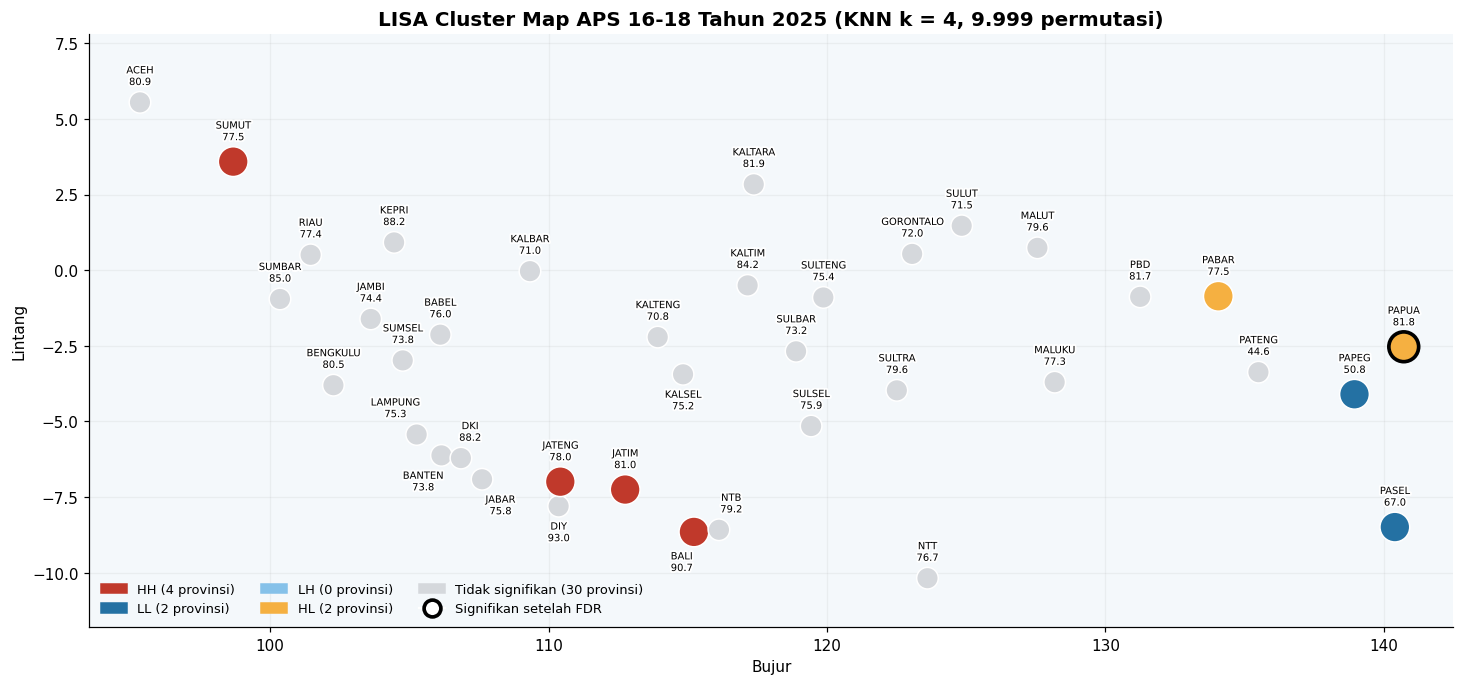

In [28]:
map_2025 = lisa_all[lisa_all["tahun"] == 2025].reset_index(drop=True)
fig, ax = plt.subplots(figsize=(16, 7))
province_map(ax, map_2025, map_2025["cluster"].map(LISA_COLORS), size=np.where(map_2025["sig_005"], 380, 200),
             value_col=TARGET, edge=np.where(map_2025["sig_fdr"], "black", "white"),
             linewidth=np.where(map_2025["sig_fdr"], 2.4, 1.0),
             title="LISA Cluster Map APS 16-18 Tahun 2025 (KNN k = 4, 9.999 permutasi)")
handles = [Patch(color=c, label=f"{k} ({int((map_2025['cluster'] == k).sum())} provinsi)") for k, c in LISA_COLORS.items()]
handles.append(Line2D([0], [0], marker="o", color="w", markerfacecolor="white", markeredgecolor="black", markeredgewidth=2.4,
                      markersize=11, label="Signifikan setelah FDR"))
ax.legend(handles=handles, loc="lower left", fontsize=8.5, ncol=3)
save_fig(fig, "03_spatial", "lisa_cluster_map_2025")

### 5.8 Evolusi LISA Cluster 2021-2025

Peta kecil per tahun memperlihatkan apakah cluster LL (kantong partisipasi rendah) bertahan, meluas, atau berpindah. Periode 2021-2023 memakai 34 provinsi dengan batas wilayah lama.

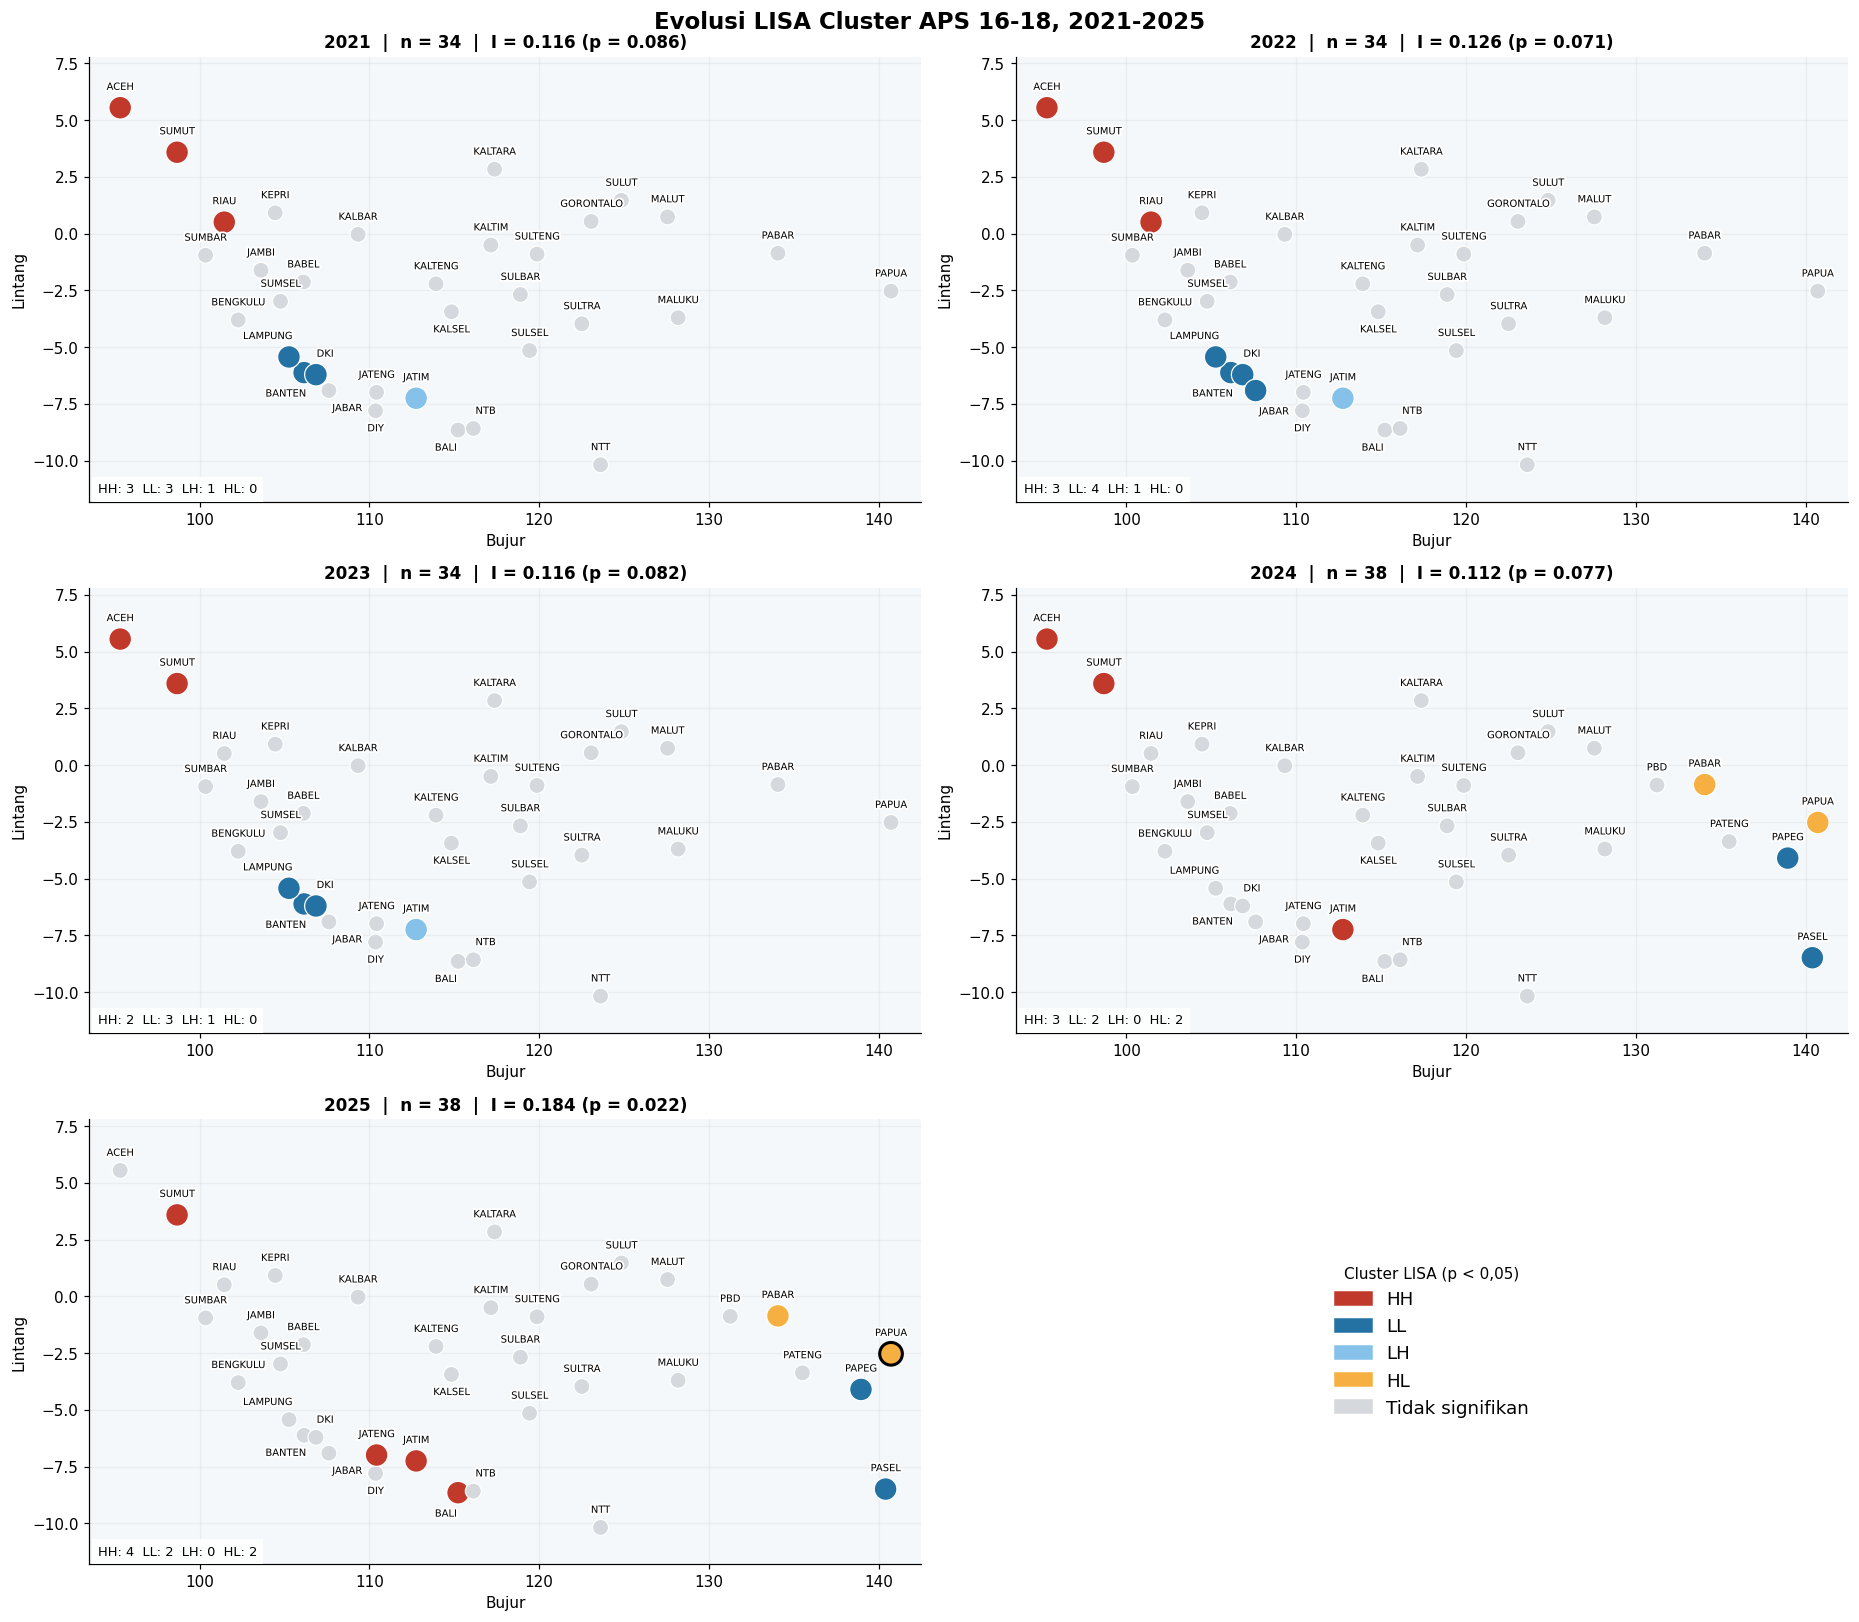

In [29]:
fig, axes = plt.subplots(3, 2, figsize=(17, 15))
for ax, year in zip(axes.ravel(), YEARS):
    part = lisa_all[lisa_all["tahun"] == year].reset_index(drop=True)
    province_map(ax, part, part["cluster"].map(LISA_COLORS), size=np.where(part["sig_005"], 220, 110),
                 edge=np.where(part["sig_fdr"], "black", "white"), linewidth=np.where(part["sig_fdr"], 2.0, 0.8))
    moran_row = moran_table.query("tahun == @year and variabel == @TARGET").iloc[0]
    counts = part["cluster"].value_counts()
    ax.set_title(f"{year}  |  n = {len(part)}  |  I = {moran_row['moran_I']:.3f} (p = {moran_row['p_sim']:.3f})", fontsize=11)
    ax.text(0.01, 0.02, "  ".join(f"{k}: {counts.get(k, 0)}" for k in ["HH", "LL", "LH", "HL"]), transform=ax.transAxes,
            fontsize=8.5, bbox=dict(facecolor="white", alpha=0.9, edgecolor="none"))
axes.ravel()[-1].axis("off")
axes.ravel()[-1].legend(handles=[Patch(color=c, label=k) for k, c in LISA_COLORS.items()], loc="center", fontsize=12,
                        title="Cluster LISA (p < 0,05)")
fig.suptitle("Evolusi LISA Cluster APS 16-18, 2021-2025", fontsize=15, fontweight="bold")
fig.tight_layout()
save_fig(fig, "03_spatial", "lisa_cluster_evolusi")

### 5.9 Bivariate Moran's I: APS 16-18 dan Kondisi Tetangga

Bivariate Moran's I mengukur hubungan antara APS 16-18 sebuah provinsi dengan **kondisi pendukung di provinsi tetangganya**. Nilai negatif untuk kemiskinan berarti provinsi dengan APS rendah cenderung dikelilingi tetangga yang miskin. Hasil 2025 dilaporkan, lalu variabel dengan hubungan terkuat dipetakan secara lokal.

variabel_tetangga                       label  moran_I_bv   z_sim  p_sim  signifikan
           miskin         Penduduk Miskin (%)     -0.3737 -3.7292 0.0004        True
              pou  Prevalensi Kurang Gizi (%)     -0.3696 -3.6670 0.0003        True
  air_minum_layak         Air Minum Layak (%)      0.2815  2.7911 0.0117        True
          listrik Rumah Tangga Berlistrik (%)      0.2734  2.7098 0.0116        True
              rls Rata-rata Lama Sekolah (th)      0.1647  1.6362 0.0626       False
  log_pdrb_kapita         log PDRB per Kapita      0.0022  0.0178 0.4987       False


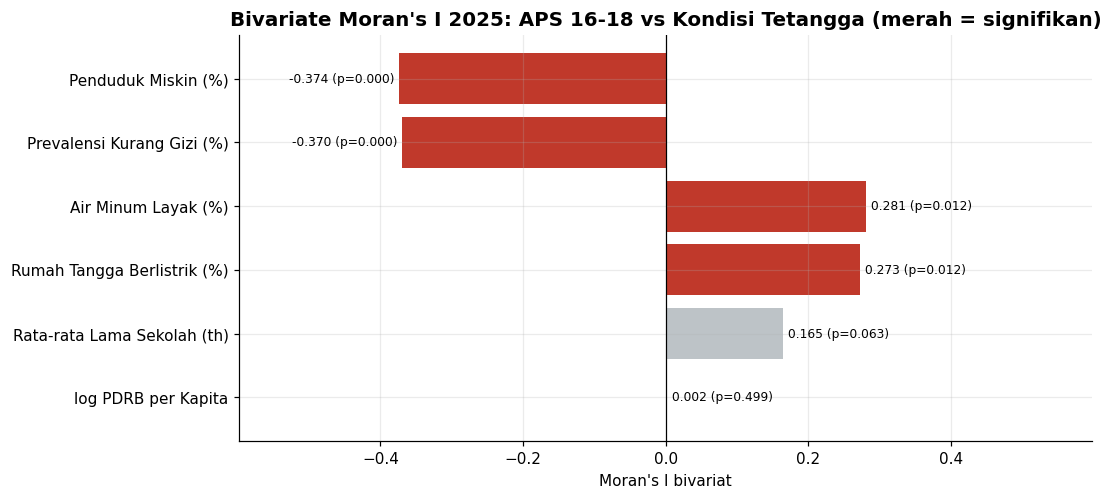

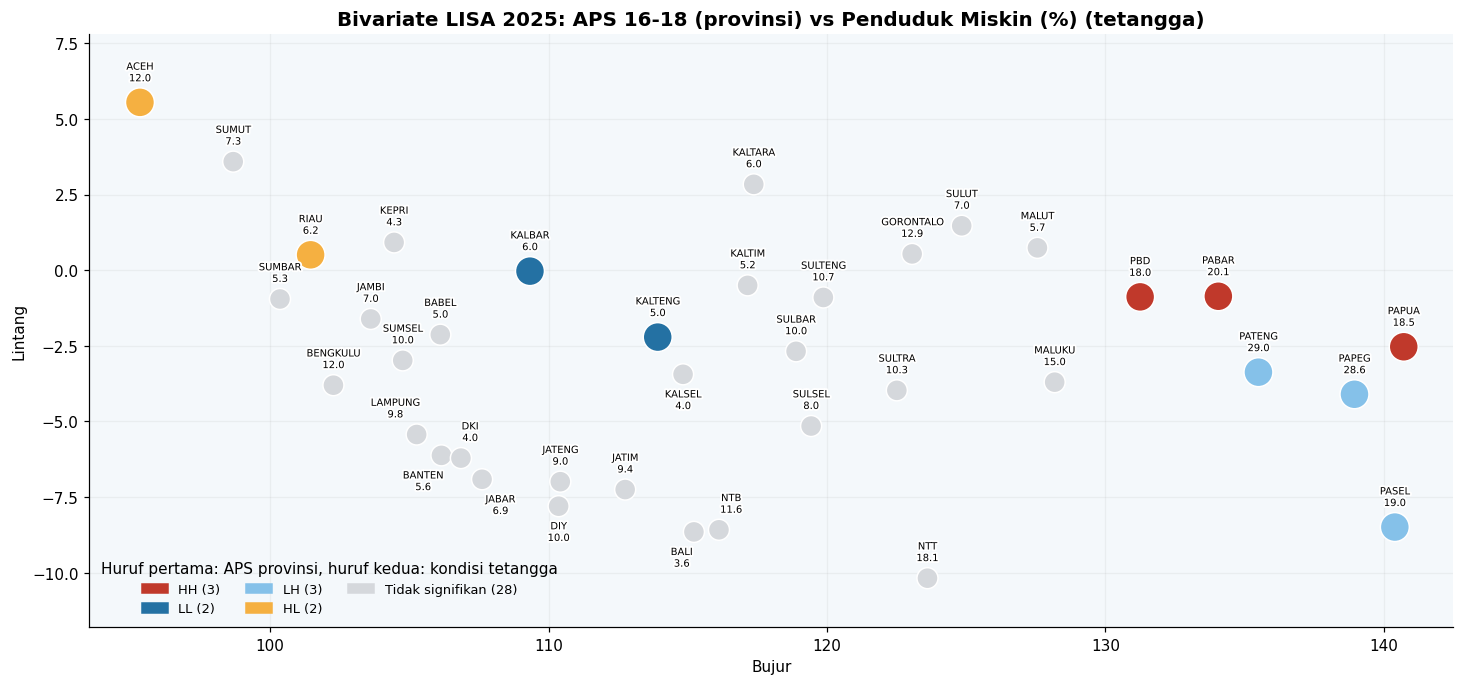

,provinsi,kode,aps_16_18,miskin,regime_bv,p_sim_bv,cluster_bv
0,ACEH,ACEH,80.94,12.00,HL,0.0292,HL
1,BALI,BALI,90.68,3.57,HL,0.4671,Tidak signifikan
2,BANTEN,BANTEN,73.84,5.57,LL,0.1751,Tidak signifikan
3,BENGKULU,BENGKULU,80.48,11.98,HL,0.2482,Tidak signifikan
4,DI YOGYAKARTA,DIY,93.03,10.00,HL,0.1529,Tidak signifikan
5,DKI JAKARTA,DKI,88.22,4.00,HL,0.1864,Tidak signifikan
6,GORONTALO,GORONTALO,72.00,12.93,LL,0.3061,Tidak signifikan
7,JAMBI,JAMBI,74.39,7.04,LL,0.2048,Tidak signifikan
8,JAWA BARAT,JABAR,75.80,6.90,LL,0.1225,Tidak signifikan
9,JAWA TENGAH,JATENG,77.97,9.00,HL,0.1786,Tidak signifikan


In [30]:
bv_vars = ["miskin", "listrik", "air_minum_layak", "rls", "log_pdrb_kapita", "pou"]
bv_rows = []
for col in bv_vars:
    np.random.seed(SEED)
    result = Moran_BV(frame_2025[TARGET].to_numpy(), frame_2025[col].to_numpy(), w_2025, permutations=PERMUTATIONS)
    bv_rows.append({"variabel_tetangga": col, "label": LABELS[col], "moran_I_bv": result.I, "z_sim": result.z_sim,
                    "p_sim": result.p_sim, "signifikan": result.p_sim < ALPHA})
bv_table = pd.DataFrame(bv_rows).sort_values("moran_I_bv", key=np.abs, ascending=False).reset_index(drop=True)
print(bv_table.round(4).to_string(index=False))
save_table(bv_table.round(5), "03_spatial", "bivariate_moran_2025")

fig, ax = plt.subplots(figsize=(10, 4.8))
bars = ax.barh(bv_table["label"], bv_table["moran_I_bv"], color=np.where(bv_table["signifikan"], COLORS["accent"], "#BDC3C7"))
ax.bar_label(bars, labels=[f"{i:.3f} (p={p:.3f})" for i, p in zip(bv_table["moran_I_bv"], bv_table["p_sim"])], fontsize=8, padding=3)
ax.axvline(0, color="black", linewidth=0.8)
lim = bv_table["moran_I_bv"].abs().max() * 1.6
ax.set_xlim(-lim, lim)
ax.invert_yaxis()
ax.set_title("Bivariate Moran's I 2025: APS 16-18 vs Kondisi Tetangga (merah = signifikan)")
ax.set_xlabel("Moran's I bivariat")
save_fig(fig, "03_spatial", "bivariate_moran_2025")

top_bv = bv_table.iloc[0]["variabel_tetangga"]
np.random.seed(SEED)
local_bv = Moran_Local_BV(frame_2025[TARGET].to_numpy(), frame_2025[top_bv].to_numpy(), w_2025, permutations=PERMUTATIONS)
bv_map = frame_2025.copy()
bv_map["regime_bv"] = [QUAD[q] for q in local_bv.q]
bv_map["p_sim_bv"] = local_bv.p_sim
bv_map["cluster_bv"] = np.where(bv_map["p_sim_bv"] < ALPHA, bv_map["regime_bv"], "Tidak signifikan")
fig, ax = plt.subplots(figsize=(16, 7))
province_map(ax, bv_map, bv_map["cluster_bv"].map(LISA_COLORS), size=np.where(bv_map["p_sim_bv"] < ALPHA, 360, 190),
             value_col=top_bv, title=f"Bivariate LISA 2025: APS 16-18 (provinsi) vs {LABELS[top_bv]} (tetangga)")
ax.legend(handles=[Patch(color=c, label=f"{k} ({int((bv_map['cluster_bv'] == k).sum())})") for k, c in LISA_COLORS.items()],
          loc="lower left", fontsize=8.5, ncol=3, title="Huruf pertama: APS provinsi, huruf kedua: kondisi tetangga")
save_fig(fig, "03_spatial", "bivariate_lisa_map_2025")
save_table(bv_map[["provinsi", "kode", TARGET, top_bv, "regime_bv", "p_sim_bv", "cluster_bv"]].round(5), "03_spatial", "bivariate_lisa_2025")

## 6. Association Rule Mining

### 6.1 Pembentukan Transaksi

Setiap provinsi-tahun menjadi satu transaksi. Indikator kondisi pendukung didiskretisasi menjadi **Rendah, Sedang, Tinggi berdasarkan tertil di dalam tahun yang sama**, sehingga kategori mencerminkan posisi relatif provinsi terhadap provinsi lain pada tahun itu (sesuai fokus kesenjangan) dan tidak terdistorsi oleh tren nasional.

Informasi spasial dimasukkan sebagai item lingkungan: `LingkunganAPS` adalah tertil spatial lag APS 16-18 (rata-rata APS para tetangga KNN) dan `LingkunganMiskin` adalah tertil spatial lag kemiskinan. Inilah titik integrasi pertama: matriks bobot dan spatial lag dari bagian 5 menjadi bahan baku pattern mining.

Kuadran LISA (HH, LL, LH, HL) sengaja **tidak** dipakai sebagai item, karena kuadran LL sudah mensyaratkan APS provinsi itu sendiri di bawah rata-rata. Jika dipakai, aturan "Spasial=LL => APS rendah" akan benar sebagian karena definisinya sendiri (sirkular). Item lingkungan hanya memakai nilai tetangga, sehingga aturan yang muncul benar-benar menguji pengaruh konteks regional.

Item target adalah `APS16-18=Rendah`, yaitu provinsi di tertil bawah APS 16-18 pada tahun tersebut. HLS, IPM, dan APS jenjang lain tidak dimasukkan sebagai item karena merupakan sesama ukuran hasil pendidikan.

In [31]:
RULE_VARS = {"miskin": "Kemiskinan", "listrik": "Listrik", "air_minum_layak": "AirMinum", "log_pdrb_kapita": "PDRBkap",
             "tpt": "Pengangguran", "tpak": "TPAK", "ikp": "KetahananPangan", "rls": "RLS", "pou": "KurangGizi",
             "log_pengeluaran_makanan": "PengeluaranMakanan"}
SPATIAL_RULE_VARS = {"w_aps_16_18": "LingkunganAPS", "w_miskin": "LingkunganMiskin"}
SPATIAL_PREFIXES = tuple(f"{name}=" for name in SPATIAL_RULE_VARS.values())
TARGET_ITEM = "APS16-18=Rendah"


def tertile_label(series):
    return pd.qcut(series.rank(method="first"), 3, labels=["Rendah", "Sedang", "Tinggi"]).astype(str)


trans_base = lisa_all[["provinsi", "kode", "tahun", "wilayah", "lon", "lat", TARGET, "regime"]].copy()
for col, name in {**RULE_VARS, **SPATIAL_RULE_VARS}.items():
    trans_base[name] = lisa_all.groupby("tahun")[col].transform(tertile_label)
trans_base["APS16-18"] = lisa_all.groupby("tahun")[TARGET].transform(tertile_label)
item_frame = pd.DataFrame({f"{name}={level}": trans_base[name] == level
                           for name in list(RULE_VARS.values()) + list(SPATIAL_RULE_VARS.values())
                           for level in ["Rendah", "Sedang", "Tinggi"]})
item_frame[TARGET_ITEM] = trans_base["APS16-18"] == "Rendah"
item_frame = item_frame.astype(bool)
print(f"Jumlah transaksi : {len(item_frame)}")
print(f"Jumlah item      : {item_frame.shape[1]}")
print(f"Support target   : {item_frame[TARGET_ITEM].mean():.4f}")
item_support = item_frame.mean().sort_values(ascending=False)
save_table(item_support.rename("support").reset_index().rename(columns={"index": "item"}).round(4), "04_pattern", "support_item")
trans_base.head()

Jumlah transaksi : 178
Jumlah item      : 37
Support target   : 0.3315


,provinsi,kode,tahun,wilayah,lon,lat,aps_16_18,regime,Kemiskinan,Listrik,AirMinum,PDRBkap,Pengangguran,TPAK,KetahananPangan,RLS,KurangGizi,PengeluaranMakanan,LingkunganAPS,LingkunganMiskin,APS16-18
0,ACEH,ACEH,2021,Sumatera,95.32,5.55,83.28,HH,Tinggi,Tinggi,Sedang,Rendah,Tinggi,Rendah,Rendah,Tinggi,Rendah,Sedang,Tinggi,Rendah,Tinggi
1,BALI,BALI,2021,Bali-Nusa Tenggara,115.22,-8.65,83.96,HH,Rendah,Tinggi,Tinggi,Sedang,Sedang,Tinggi,Tinggi,Sedang,Rendah,Sedang,Tinggi,Tinggi,Tinggi
2,BANTEN,BANTEN,2021,Jawa,106.15,-6.12,68.94,LL,Rendah,Tinggi,Tinggi,Sedang,Tinggi,Rendah,Sedang,Sedang,Rendah,Tinggi,Rendah,Sedang,Rendah
3,BENGKULU,BENGKULU,2021,Sumatera,102.27,-3.80,79.75,HL,Tinggi,Sedang,Rendah,Rendah,Rendah,Tinggi,Rendah,Sedang,Sedang,Sedang,Sedang,Sedang,Tinggi
4,DI YOGYAKARTA,DIY,2021,Jawa,110.36,-7.80,89.63,HL,Tinggi,Tinggi,Tinggi,Rendah,Rendah,Tinggi,Tinggi,Tinggi,Sedang,Sedang,Rendah,Sedang,Tinggi


### 6.2 Penambangan, Uji Statistik, dan Stabilitas Aturan

Prosedur penambangan aturan dibuat ketat karena jumlah transaksi kecil (178), sehingga risiko menemukan pola kebetulan tinggi:

1. **FP-Growth** mencari itemset sering dengan support minimal 0,08 dan panjang maksimal 4.
2. Aturan dibentuk dengan konsekuen `APS16-18=Rendah`, lalu disaring dengan confidence minimal 0,60 dan lift minimal 1,20.
3. **Uji Fisher exact** satu arah menguji apakah antecedent benar-benar meningkatkan peluang APS rendah, lalu dikoreksi **Benjamini-Hochberg**.
4. **Bootstrap klaster provinsi** (500 kali): provinsi diambil ulang beserta seluruh tahunnya, karena baris dari provinsi yang sama tidak independen. Stabilitas adalah proporsi bootstrap di mana aturan tetap memenuhi ambang support, confidence, dan lift.
5. **Pruning redundansi**: aturan dibuang jika ada aturan yang lebih umum (antecedent lebih sedikit) dengan confidence setara atau lebih tinggi.

Hanya aturan yang lolos FDR, stabil minimal 60%, dan tidak redundan yang dipakai. Aturan diurutkan berdasarkan stabilitas, lalu lift, sehingga aturan teratas adalah pola yang paling dapat diandalkan, bukan pola langka yang kebetulan sempurna.

In [32]:
def rule_matrix(items, antecedents):
    return np.column_stack([items[list(ante)].all(axis=1).to_numpy() for ante in antecedents]) if antecedents else np.zeros((len(items), 0), dtype=bool)


def mine_rules(items, n_boot, seed=SEED, groups=None):
    frequent = fpgrowth(items, min_support=RULE_MIN_SUPPORT, use_colnames=True, max_len=RULE_MAX_LEN)
    support = {frozenset(s): v for s, v in zip(frequent["itemsets"], frequent["support"])}
    p_target = items[TARGET_ITEM].mean()
    candidates = []
    for itemset, sup in support.items():
        if TARGET_ITEM in itemset and len(itemset) > 1:
            ante = itemset - {TARGET_ITEM}
            conf = sup / support[ante]
            lift = conf / p_target
            if conf >= RULE_MIN_CONFIDENCE and lift >= RULE_MIN_LIFT:
                candidates.append({"antecedent": tuple(sorted(ante)), "support": sup, "confidence": conf, "lift": lift})
    if not candidates:
        return pd.DataFrame(columns=["antecedent", "support", "confidence", "lift", "p_fisher", "q_fdr", "stabilitas"])
    rules = pd.DataFrame(candidates)
    target = items[TARGET_ITEM].to_numpy()
    matrix = rule_matrix(items, rules["antecedent"].tolist())
    p_values = []
    for j in range(matrix.shape[1]):
        a = int((matrix[:, j] & target).sum())
        b = int((matrix[:, j] & ~target).sum())
        c = int((~matrix[:, j] & target).sum())
        d = int((~matrix[:, j] & ~target).sum())
        p_values.append(stats.fisher_exact([[a, b], [c, d]], alternative="greater")[1])
    rules["p_fisher"] = p_values
    rules["q_fdr"] = bh_fdr(p_values)
    group_values = groups if groups is not None else np.arange(len(items))
    unique_groups = np.unique(group_values)
    group_index = {g: np.where(group_values == g)[0] for g in unique_groups}
    generator = np.random.default_rng(seed)
    passes = np.zeros(matrix.shape[1])
    for _ in range(n_boot):
        weights = np.zeros(len(items))
        for g in generator.choice(unique_groups, size=len(unique_groups), replace=True):
            weights[group_index[g]] += 1
        total = weights.sum()
        sup_target = (weights * target).sum() / total
        sup_ante = weights @ matrix / total
        sup_rule = weights @ (matrix & target[:, None]) / total
        with np.errstate(divide="ignore", invalid="ignore"):
            conf = np.where(sup_ante > 0, sup_rule / sup_ante, 0)
            lift = np.where(sup_target > 0, conf / sup_target, 0)
        passes += (sup_rule >= RULE_MIN_SUPPORT) & (conf >= RULE_MIN_CONFIDENCE) & (lift >= RULE_MIN_LIFT)
    rules["stabilitas"] = passes / n_boot
    return rules


def select_rules(rules, top_k=RULE_TOP_K):
    if rules.empty:
        return rules
    eligible = rules[(rules["q_fdr"] < ALPHA) & (rules["stabilitas"] >= RULE_STABILITY)].copy()
    eligible["panjang"] = eligible["antecedent"].apply(len)
    eligible = eligible.sort_values(["confidence", "panjang", "lift"], ascending=[False, True, False])
    kept = []
    for _, row in eligible.iterrows():
        ante = set(row["antecedent"])
        if not any(set(k["antecedent"]) < ante and k["confidence"] >= row["confidence"] - 1e-9 for k in kept):
            kept.append(row)
    selected = pd.DataFrame(kept)
    if selected.empty:
        return selected
    selected = selected.sort_values(["stabilitas", "lift", "confidence"], ascending=False).head(top_k).reset_index(drop=True)
    selected["rule_id"] = [f"R{i + 1}" for i in range(len(selected))]
    return selected


all_rules = mine_rules(item_frame, BOOTSTRAP_MAIN, groups=trans_base["provinsi"].to_numpy())
selected_rules = select_rules(all_rules)
selected_rules["aturan"] = selected_rules["antecedent"].apply(lambda a: " & ".join(a)) + "  =>  " + TARGET_ITEM
print(f"Kandidat aturan (lolos support, confidence, lift): {len(all_rules)}")
print(f"Lolos FDR q < 0,05                                : {int((all_rules['q_fdr'] < ALPHA).sum())}")
print(f"Lolos FDR dan stabil >= {RULE_STABILITY:.0%}                       : {int(((all_rules['q_fdr'] < ALPHA) & (all_rules['stabilitas'] >= RULE_STABILITY)).sum())}")
print(f"Aturan terpilih setelah pruning                    : {len(selected_rules)}")
show_cols = ["rule_id", "aturan", "support", "confidence", "lift", "p_fisher", "q_fdr", "stabilitas"]
print("\n" + selected_rules[show_cols].round(4).to_string(index=False))
export_all = all_rules.assign(antecedent=all_rules["antecedent"].apply(lambda a: " & ".join(a)))
save_table(export_all.sort_values("lift", ascending=False).round(5), "04_pattern", "semua_kandidat_aturan")
save_table(selected_rules[show_cols + ["panjang"]].round(5), "04_pattern", "aturan_terpilih")

Kandidat aturan (lolos support, confidence, lift): 20
Lolos FDR q < 0,05                                : 20
Lolos FDR dan stabil >= 60%                       : 7
Aturan terpilih setelah pruning                    : 7

rule_id                                                         aturan  support  confidence   lift  p_fisher  q_fdr  stabilitas
     R1              AirMinum=Rendah & RLS=Rendah  =>  APS16-18=Rendah   0.1348      0.7059 2.1296    0.0000 0.0000       0.734
     R2       KetahananPangan=Tinggi & RLS=Sedang  =>  APS16-18=Rendah   0.1011      0.7500 2.2627    0.0000 0.0000       0.664
     R3          AirMinum=Rendah & Listrik=Rendah  =>  APS16-18=Rendah   0.1124      0.7143 2.1550    0.0000 0.0000       0.656
     R4     AirMinum=Rendah & Pengangguran=Sedang  =>  APS16-18=Rendah   0.1067      0.6786 2.0472    0.0000 0.0001       0.636
     R5       AirMinum=Rendah & Kemiskinan=Rendah  =>  APS16-18=Rendah   0.0955      0.7727 2.3313    0.0000 0.0000       0.624
     R6 AirMi

,rule_id,aturan,support,confidence,lift,p_fisher,q_fdr,stabilitas,panjang
0,R1,AirMinum=Rendah & RLS=Rendah => APS16-18=Rendah,0.13483,0.70588,2.12961,0.00000,0.00000,0.734,2
1,R2,KetahananPangan=Tinggi & RLS=Sedang => APS16-18=Rendah,0.10112,0.75000,2.26271,0.00001,0.00003,0.664,2
2,R3,AirMinum=Rendah & Listrik=Rendah => APS16-18=Rendah,0.11236,0.71429,2.15496,0.00001,0.00003,0.656,2
3,R4,AirMinum=Rendah & Pengangguran=Sedang => APS16-18=Rendah,0.10674,0.67857,2.04722,0.00004,0.00010,0.636,2
4,R5,AirMinum=Rendah & Kemiskinan=Rendah => APS16-18=Rendah,0.09551,0.77273,2.33128,0.00001,0.00003,0.624,2
5,R6,AirMinum=Rendah & LingkunganMiskin=Rendah => APS16-18=Rendah,0.09551,0.85000,2.56441,0.00000,0.00000,0.622,2
6,R7,KurangGizi=Tinggi & RLS=Rendah => APS16-18=Rendah,0.11798,0.63636,1.91988,0.00007,0.00011,0.606,2


### 6.3 Kontribusi Item Lingkungan Spasial terhadap Kekuatan Aturan

Untuk membuktikan bahwa integrasi spasial menambah nilai pada pattern mining, penambangan diulang dengan prosedur identik tetapi **tanpa item lingkungan spasial**. Jika aturan dengan item spasial lebih kuat (lift dan confidence lebih tinggi) atau lebih banyak lolos uji, maka konteks regional memang membawa informasi yang tidak tertangkap oleh kondisi internal provinsi saja.

                     skenario  kandidat  lolos_FDR_dan_stabil  terpilih  rata2_confidence  rata2_lift  lift_maks  rata2_stabilitas
Internal + lingkungan spasial        20                     7         7            0.7297      2.2014     2.5644            0.6489
                Internal saja        17                     6         6            0.7096      2.1409     2.3313            0.6533

Aturan terpilih yang memuat item lingkungan spasial: 1 dari 7


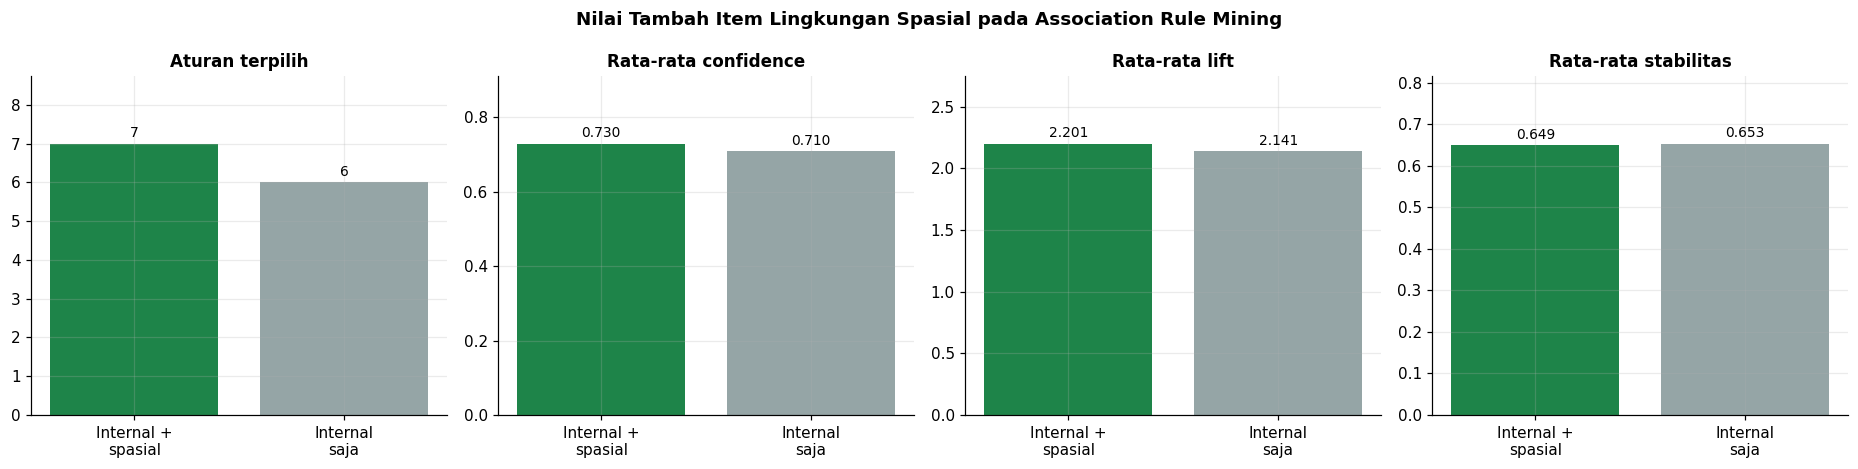

In [33]:
items_internal = item_frame.drop(columns=[c for c in item_frame.columns if c.startswith(SPATIAL_PREFIXES)])
rules_internal_all = mine_rules(items_internal, BOOTSTRAP_MAIN, groups=trans_base["provinsi"].to_numpy())
rules_internal = select_rules(rules_internal_all)
has_spatial = selected_rules["antecedent"].apply(lambda a: any(i.startswith(SPATIAL_PREFIXES) for i in a))


def rule_profile(cands, chosen, name):
    return {"skenario": name, "kandidat": len(cands),
            "lolos_FDR_dan_stabil": int(((cands["q_fdr"] < ALPHA) & (cands["stabilitas"] >= RULE_STABILITY)).sum()) if len(cands) else 0,
            "terpilih": len(chosen),
            "rata2_confidence": chosen["confidence"].mean() if len(chosen) else np.nan,
            "rata2_lift": chosen["lift"].mean() if len(chosen) else np.nan,
            "lift_maks": chosen["lift"].max() if len(chosen) else np.nan,
            "rata2_stabilitas": chosen["stabilitas"].mean() if len(chosen) else np.nan}


rule_compare = pd.DataFrame([rule_profile(all_rules, selected_rules, "Internal + lingkungan spasial"),
                             rule_profile(rules_internal_all, rules_internal, "Internal saja")])
print(rule_compare.round(4).to_string(index=False))
print(f"\nAturan terpilih yang memuat item lingkungan spasial: {int(has_spatial.sum())} dari {len(selected_rules)}")
save_table(rule_compare.round(5), "04_pattern", "perbandingan_aturan_spasial_vs_internal")
if len(rules_internal):
    save_table(rules_internal.assign(antecedent=rules_internal["antecedent"].apply(lambda a: " & ".join(a))).round(5),
               "04_pattern", "aturan_tanpa_item_spasial")

fig, axes = plt.subplots(1, 4, figsize=(17, 4.3))
for ax, col, title, fmt in [(axes[0], "terpilih", "Aturan terpilih", "{:.0f}"), (axes[1], "rata2_confidence", "Rata-rata confidence", "{:.3f}"),
                            (axes[2], "rata2_lift", "Rata-rata lift", "{:.3f}"), (axes[3], "rata2_stabilitas", "Rata-rata stabilitas", "{:.3f}")]:
    bars = ax.bar(["Internal +\nspasial", "Internal\nsaja"], rule_compare[col].fillna(0), color=[COLORS["good"], "#95A5A6"])
    ax.bar_label(bars, fmt=fmt, fontsize=9, padding=2)
    ax.set_ylim(0, max(rule_compare[col].fillna(0).max() * 1.25, 0.1))
    ax.set_title(title, fontsize=11)
fig.suptitle("Nilai Tambah Item Lingkungan Spasial pada Association Rule Mining", fontweight="bold")
fig.tight_layout()
save_fig(fig, "04_pattern", "perbandingan_aturan_spasial_vs_internal")

### 6.4 Visualisasi Aturan Terpilih

Panel kiri menampilkan lift setiap aturan beserta confidence dan stabilitas bootstrap. Panel kanan memetakan seluruh kandidat aturan pada bidang support-confidence, dengan aturan terpilih ditandai.

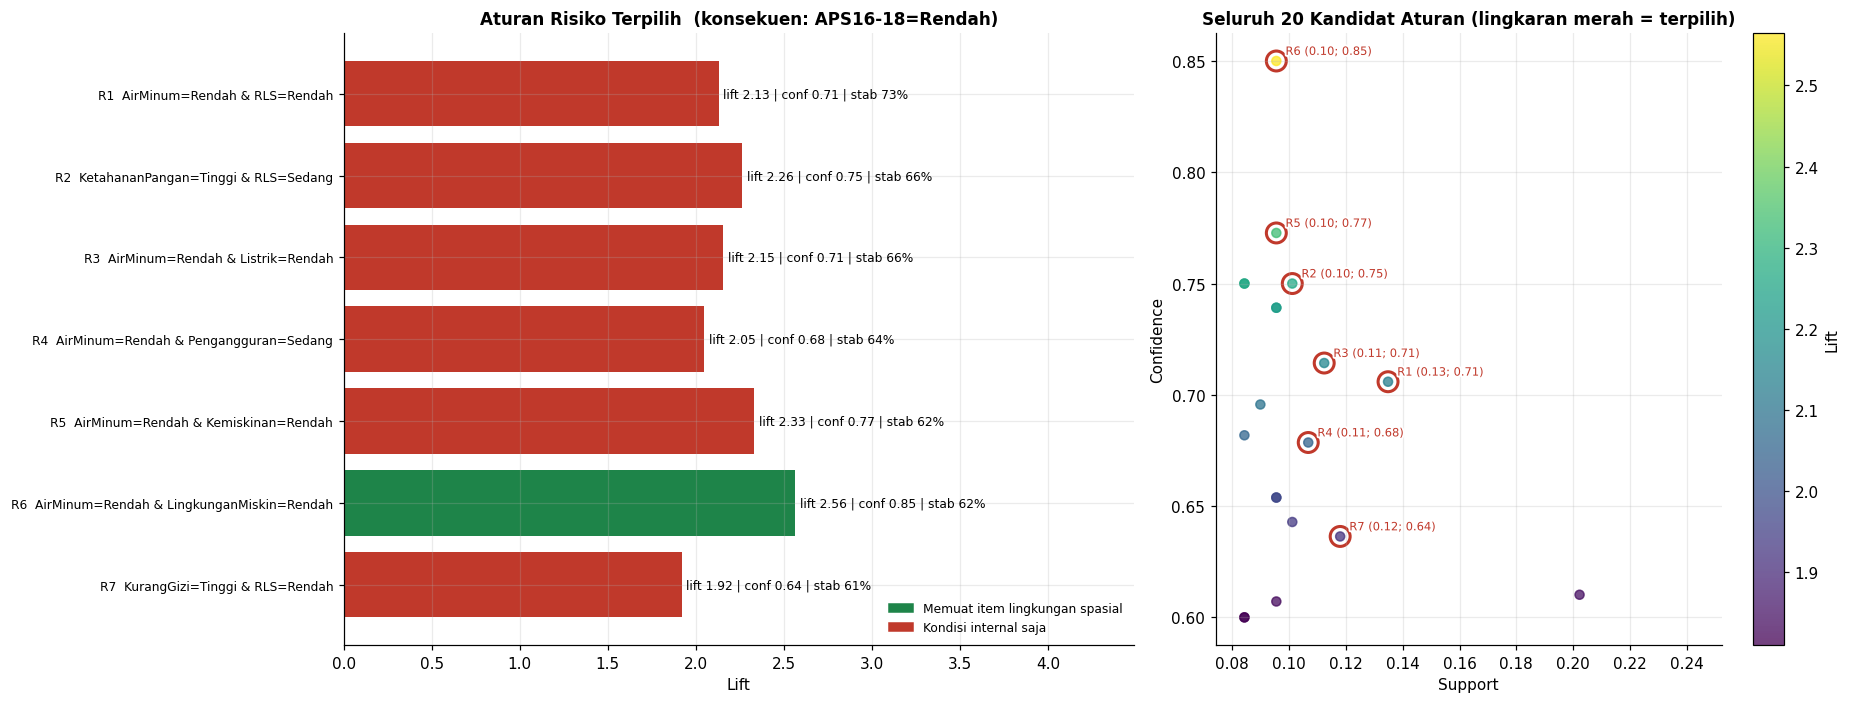

In [34]:
fig, axes = plt.subplots(1, 2, figsize=(17, 6.5), gridspec_kw={"width_ratios": [1.25, 1]})
plot_rules = selected_rules.iloc[::-1]
rule_has_spatial = plot_rules["antecedent"].apply(lambda a: any(i.startswith(SPATIAL_PREFIXES) for i in a))
bars = axes[0].barh(plot_rules["rule_id"] + "  " + plot_rules["antecedent"].apply(lambda a: " & ".join(a)),
                    plot_rules["lift"], color=np.where(rule_has_spatial, COLORS["good"], COLORS["accent"]))
axes[0].legend(handles=[Patch(color=COLORS["good"], label="Memuat item lingkungan spasial"),
                        Patch(color=COLORS["accent"], label="Kondisi internal saja")], loc="lower right", fontsize=8)
axes[0].bar_label(bars, labels=[f"lift {l:.2f} | conf {c:.2f} | stab {s:.0%}" for l, c, s in
                                zip(plot_rules["lift"], plot_rules["confidence"], plot_rules["stabilitas"])], fontsize=8, padding=3)
axes[0].set_xlim(0, plot_rules["lift"].max() * 1.75)
axes[0].set_xlabel("Lift")
axes[0].set_title(f"Aturan Risiko Terpilih  (konsekuen: {TARGET_ITEM})", fontsize=11)
axes[0].tick_params(axis="y", labelsize=8)

scatter = axes[1].scatter(all_rules["support"], all_rules["confidence"], c=all_rules["lift"], cmap="viridis", s=35, alpha=0.75)
axes[1].scatter(selected_rules["support"], selected_rules["confidence"], s=170, facecolors="none", edgecolors=COLORS["accent"], linewidths=2)
for _, row in selected_rules.iterrows():
    outlined(axes[1].annotate(f"{row['rule_id']} ({row['support']:.2f}; {row['confidence']:.2f})", (row["support"], row["confidence"]),
                              xytext=(6, 4), textcoords="offset points", fontsize=7.5, color=COLORS["accent"]))
fig.colorbar(scatter, ax=axes[1], label="Lift")
axes[1].set_xlim(all_rules["support"].min() - 0.01, all_rules["support"].max() + 0.05)
axes[1].set_xlabel("Support")
axes[1].set_ylabel("Confidence")
axes[1].set_title(f"Seluruh {len(all_rules)} Kandidat Aturan (lingkaran merah = terpilih)", fontsize=11)
fig.tight_layout()
save_fig(fig, "04_pattern", "aturan_terpilih")

### 6.5 Provinsi yang Memenuhi Aturan Risiko Tahun 2025

Matriks ini menunjukkan aturan mana yang terpenuhi oleh setiap provinsi pada 2025. Kolom paling kanan adalah status APS 16-18 aktual. Provinsi yang memenuhi banyak aturan tetapi belum berstatus rendah adalah **kandidat peringatan dini**: kondisinya menyerupai provinsi tertinggal walaupun partisipasinya belum jatuh.

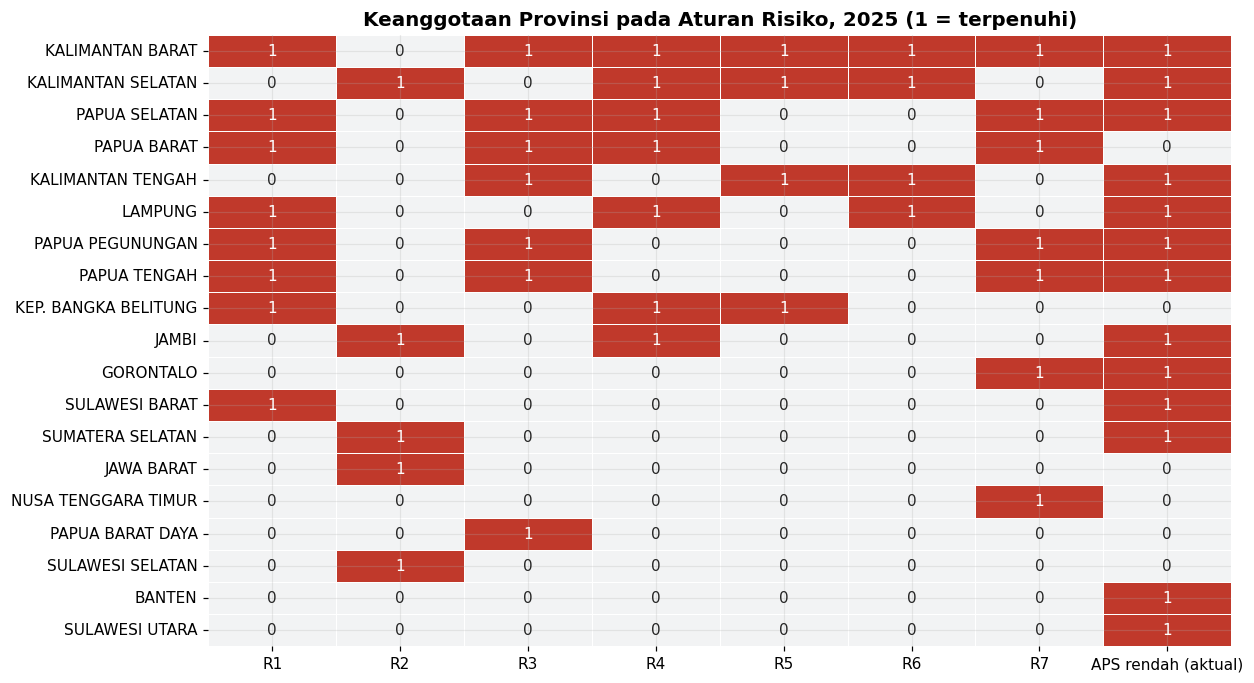

Provinsi memenuhi aturan risiko tetapi APS belum di tertil bawah (kandidat peringatan dini):
            provinsi  jumlah_aturan
         PAPUA BARAT              4
KEP. BANGKA BELITUNG              3
          JAWA BARAT              1
 NUSA TENGGARA TIMUR              1
    PAPUA BARAT DAYA              1
    SULAWESI SELATAN              1


,R1,R2,R3,R4,R5,R6,R7,provinsi,kode,tahun,aps_rendah
0,0,0,0,0,0,0,0,ACEH,ACEH,2021,0
1,0,1,0,0,0,0,0,BALI,BALI,2021,0
2,0,0,0,0,0,0,0,BANTEN,BANTEN,2021,1
3,0,0,0,0,0,0,0,BENGKULU,BENGKULU,2021,0
4,0,0,0,0,0,0,0,DI YOGYAKARTA,DIY,2021,0
...,...,...,...,...,...,...,...,...,...,...,...
173,0,0,0,0,0,0,0,SULAWESI TENGGARA,SULTRA,2025,0
174,0,0,0,0,0,0,0,SULAWESI UTARA,SULUT,2025,1
175,0,0,0,0,0,0,0,SUMATERA BARAT,SUMBAR,2025,0
176,0,1,0,0,0,0,0,SUMATERA SELATAN,SUMSEL,2025,1


In [35]:
rule_names = selected_rules["rule_id"].tolist()
match_all = pd.DataFrame(rule_matrix(item_frame, selected_rules["antecedent"].tolist()).astype(int), columns=rule_names)
for col in ["provinsi", "kode", "tahun"]:
    match_all[col] = trans_base[col].to_numpy()
match_all["aps_rendah"] = item_frame[TARGET_ITEM].astype(int).to_numpy()
match_2025 = match_all[match_all["tahun"] == 2025].copy()
match_2025["jumlah_aturan"] = match_2025[rule_names].sum(axis=1)
match_2025 = match_2025.sort_values(["jumlah_aturan", "aps_rendah"], ascending=False)
heat_rules = match_2025.set_index("provinsi")[rule_names + ["aps_rendah"]].rename(columns={"aps_rendah": "APS rendah (aktual)"})
heat_rules = heat_rules[match_2025.set_index("provinsi")["jumlah_aturan"].gt(0) | heat_rules["APS rendah (aktual)"].eq(1)]
fig, ax = plt.subplots(figsize=(12, max(5, 0.38 * len(heat_rules))))
sns.heatmap(heat_rules.astype(int), annot=True, fmt="d", cmap=sns.color_palette(["#F2F3F4", "#C0392B"], as_cmap=True),
            cbar=False, linewidths=0.5, linecolor="white", ax=ax)
ax.set_title("Keanggotaan Provinsi pada Aturan Risiko, 2025 (1 = terpenuhi)")
ax.set_ylabel("")
save_fig(fig, "04_pattern", "keanggotaan_aturan_2025")
early_warning = match_2025[(match_2025["jumlah_aturan"] > 0) & (match_2025["aps_rendah"] == 0)]
print("Provinsi memenuhi aturan risiko tetapi APS belum di tertil bawah (kandidat peringatan dini):")
print(early_warning[["provinsi", "jumlah_aturan"]].to_string(index=False) if len(early_warning) else "tidak ada")
save_table(match_all, "04_pattern", "keanggotaan_aturan_semua_tahun")

### 6.6 Dinamika Temporal Aturan

Confidence setiap aturan dihitung ulang per tahun. Aturan yang confidence-nya stabil atau meningkat menandakan pola struktural yang menguat, bukan kebetulan satu tahun.

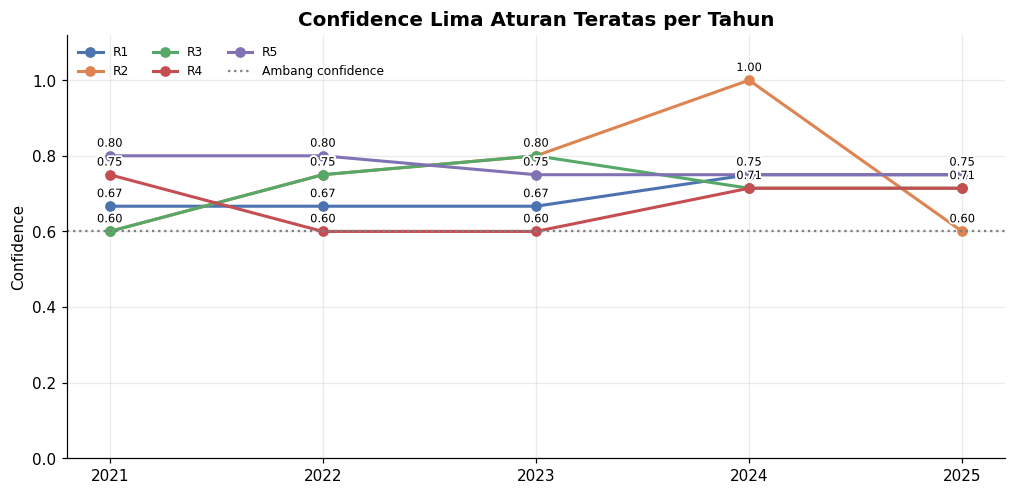

tahun     2021   2022   2023   2024   2025
rule_id                                   
R1       0.667  0.667  0.667  0.750  0.750
R2       0.600  0.750  0.800  1.000  0.600
R3       0.600  0.750  0.800  0.714  0.714
R4       0.750  0.600  0.600  0.714  0.714
R5       0.800  0.800  0.750  0.750  0.750
R6       0.750  0.750  0.750  1.000  1.000
R7       0.714  0.500  0.667  0.571  0.714


In [36]:
dyn_rows = []
for year in YEARS:
    mask = (trans_base["tahun"] == year).to_numpy()
    sub = item_frame[mask]
    matrix = rule_matrix(sub, selected_rules["antecedent"].tolist())
    target = sub[TARGET_ITEM].to_numpy()
    for j, rid in enumerate(rule_names):
        n_ante = int(matrix[:, j].sum())
        dyn_rows.append({"tahun": year, "rule_id": rid, "n_antecedent": n_ante,
                         "confidence": (matrix[:, j] & target).sum() / n_ante if n_ante else np.nan})
rule_dynamics = pd.DataFrame(dyn_rows)
save_table(rule_dynamics.round(4), "04_pattern", "dinamika_confidence_aturan")
top_dynamic = selected_rules["rule_id"].head(5).tolist()
fig, ax = plt.subplots(figsize=(11, 5))
for rid in top_dynamic:
    part = rule_dynamics[rule_dynamics["rule_id"] == rid]
    ax.plot(part["tahun"], part["confidence"], marker="o", linewidth=2, label=rid)
    for _, row in part.dropna().iterrows():
        outlined(ax.annotate(f"{row['confidence']:.2f}", (row["tahun"], row["confidence"]), xytext=(0, 6),
                             textcoords="offset points", ha="center", fontsize=7.5))
ax.axhline(RULE_MIN_CONFIDENCE, color="grey", linestyle=":", label="Ambang confidence")
ax.set_xticks(YEARS)
ax.set_ylim(0, 1.12)
ax.set_ylabel("Confidence")
ax.set_title("Confidence Lima Aturan Teratas per Tahun")
ax.legend(fontsize=8, ncol=3)
save_fig(fig, "04_pattern", "dinamika_confidence_aturan")
print(rule_dynamics.pivot(index="rule_id", columns="tahun", values="confidence").round(3).to_string())

### 6.7 Spatial Markov Chain: Pola Transisi Kelas yang Dipengaruhi Tetangga

Spatial Markov chain (Rey, 2001) adalah pattern mining sekuensial yang menyertakan konteks spasial. Setiap provinsi diberi kelas APS 16-18 (tertil dalam tahun), lalu transisi kelas dari tahun ke tahun dihitung secara terpisah untuk provinsi yang tetangganya **lemah** (spatial lag di bawah median tahun itu) dan **kuat** (di atas median).

Jika peluang bertahan di kelas Rendah jauh lebih besar ketika tetangganya lemah, maka lingkungan regional memengaruhi mobilitas pendidikan sebuah provinsi. Uji likelihood ratio membandingkan matriks bersyarat dengan matriks gabungan. Karena jumlah transisi kecil, hasil uji ini dibaca sebagai indikasi, bukan bukti final.

Jumlah transisi valid: 138
Uji LR homogenitas spatial Markov: LR = 4.686, df = 4, p = 0.3211


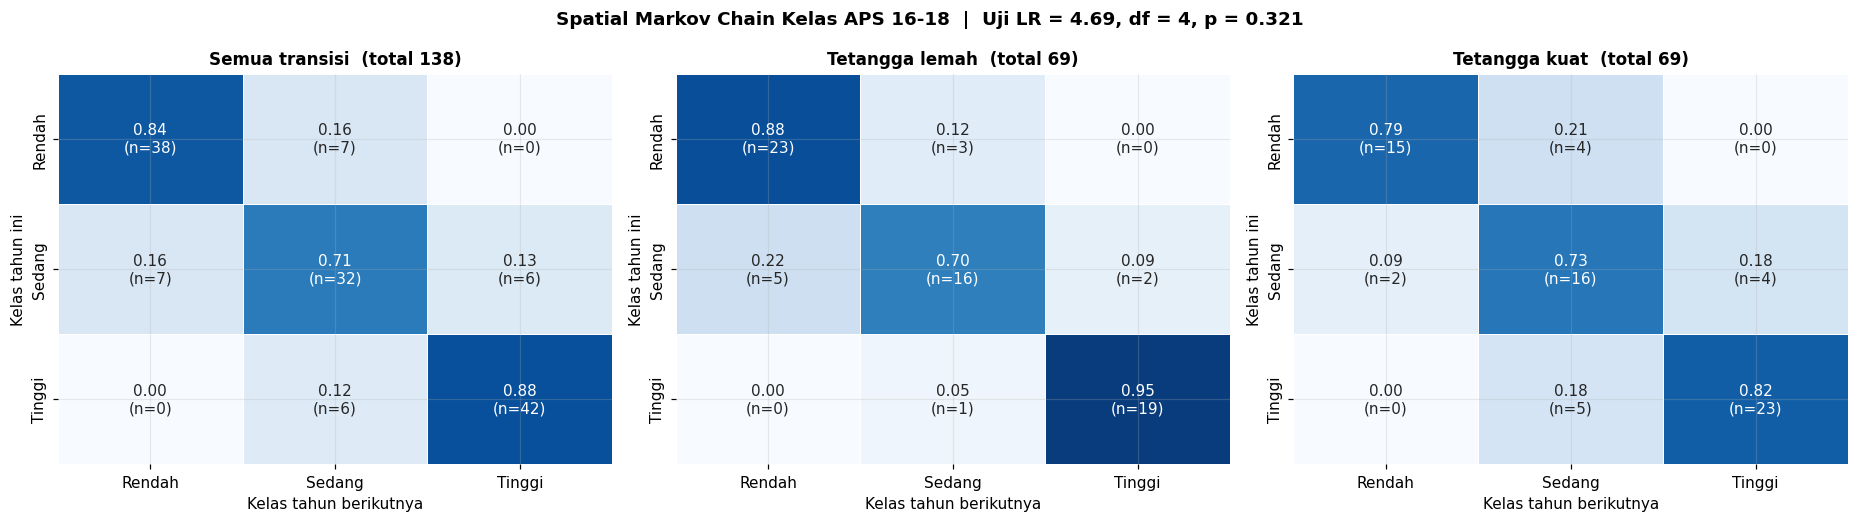


Peluang bertahan di kelas Rendah:
       konteks  jumlah  probabilitas
Tetangga lemah      23         0.885
 Tetangga kuat      15         0.789


In [37]:
CLASSES = ["Rendah", "Sedang", "Tinggi"]
markov_base = trans_base[["provinsi", "tahun", "APS16-18"]].copy()
markov_base["konteks"] = np.where(lisa_all["w_aps_16_18"] < lisa_all.groupby("tahun")["w_aps_16_18"].transform("median"),
                                  "Tetangga lemah", "Tetangga kuat")
nxt = markov_base[["provinsi", "tahun", "APS16-18"]].rename(columns={"APS16-18": "kelas_berikut"})
nxt["tahun"] = nxt["tahun"] - 1
transitions = markov_base.merge(nxt, on=["provinsi", "tahun"])
transitions = transitions[[valid_transition(p, y) for p, y in zip(transitions["provinsi"], transitions["tahun"])]]


def transition_counts(frame):
    return pd.crosstab(frame["APS16-18"], frame["kelas_berikut"]).reindex(index=CLASSES, columns=CLASSES, fill_value=0)


pooled = transition_counts(transitions)
conditional = {ctx: transition_counts(transitions[transitions["konteks"] == ctx]) for ctx in ["Tetangga lemah", "Tetangga kuat"]}
pooled_prob = pooled.div(pooled.sum(axis=1).replace(0, np.nan), axis=0)
lr_stat, df_lr = 0.0, 0
for counts in conditional.values():
    prob = counts.div(counts.sum(axis=1).replace(0, np.nan), axis=0)
    for i in CLASSES:
        if counts.loc[i].sum() > 0:
            df_lr += int((pooled.loc[i] > 0).sum()) - 1
            for j in CLASSES:
                if counts.loc[i, j] > 0:
                    lr_stat += 2 * counts.loc[i, j] * np.log(prob.loc[i, j] / pooled_prob.loc[i, j])
df_lr -= int(sum((pooled.loc[i] > 0).sum() - 1 for i in CLASSES if pooled.loc[i].sum() > 0))
lr_p = stats.chi2.sf(lr_stat, df_lr) if df_lr > 0 else np.nan
print(f"Jumlah transisi valid: {len(transitions)}")
print(f"Uji LR homogenitas spatial Markov: LR = {lr_stat:.3f}, df = {df_lr}, p = {lr_p:.4f}")

fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
for ax, (title, counts) in zip(axes, [("Semua transisi", pooled)] + list(conditional.items())):
    prob = counts.div(counts.sum(axis=1).replace(0, np.nan), axis=0)
    annot = prob.map(lambda v: "-" if pd.isna(v) else f"{v:.2f}") + "\n(n=" + counts.astype(str) + ")"
    sns.heatmap(prob.fillna(0), annot=annot, fmt="", cmap="Blues", vmin=0, vmax=1, cbar=False, linewidths=0.5, ax=ax)
    ax.set_title(f"{title}  (total {int(counts.values.sum())})", fontsize=11)
    ax.set_xlabel("Kelas tahun berikutnya")
    ax.set_ylabel("Kelas tahun ini")
fig.suptitle(f"Spatial Markov Chain Kelas APS 16-18  |  Uji LR = {lr_stat:.2f}, df = {df_lr}, p = {lr_p:.3f}", fontweight="bold")
fig.tight_layout()
save_fig(fig, "04_pattern", "spatial_markov_chain")

markov_rows = []
for ctx, counts in [("Semua", pooled)] + list(conditional.items()):
    prob = counts.div(counts.sum(axis=1).replace(0, np.nan), axis=0)
    for i in CLASSES:
        for j in CLASSES:
            markov_rows.append({"konteks": ctx, "kelas_awal": i, "kelas_berikut": j, "jumlah": int(counts.loc[i, j]),
                                "probabilitas": prob.loc[i, j]})
markov_table = pd.DataFrame(markov_rows)
save_table(markov_table.round(4), "04_pattern", "spatial_markov_chain")
stay_low = markov_table.query("kelas_awal == 'Rendah' and kelas_berikut == 'Rendah' and konteks != 'Semua'")
print("\nPeluang bertahan di kelas Rendah:\n" + stay_low[["konteks", "jumlah", "probabilitas"]].round(3).to_string(index=False))

## 7. Explainable Forecasting

### 7.1 Membangun Panel Sampel Forecasting Dua Horizon

Proyeksi dibuat untuk dua tahun ke depan: **2026 (horizon 1)** dan **2027 (horizon 2)**. Strategi yang dipakai adalah **direct multi-horizon forecasting**: satu model terpisah dilatih untuk setiap horizon, dengan target perubahan APS 16-18 dari tahun t ke t+h dan fitur dari tahun t. Strategi ini dipilih karena strategi rekursif (memakai prediksi 2026 untuk memprediksi 2027) membutuhkan nilai kemiskinan, listrik, dan indikator lain tahun 2026 yang belum tersedia, sehingga galat akan menumpuk.

Proyeksi level dihitung sebagai APS tahun asal ditambah perubahan yang diprediksi. Memprediksi perubahan lebih jujur daripada memprediksi level secara langsung, karena APS tahun ini sudah menjelaskan sebagian besar APS tahun depan.

Fitur dikelompokkan menjadi tiga blok sesuai rantai integrasi:

- **Base**: kondisi sosial-ekonomi dan pendidikan pada tahun t, termasuk APS 16-18 saat ini dan APS 13-15 sebagai "pipa" calon siswa SMA.
- **Spatial**: spatial lag APS 16-18, spatial lag kemiskinan, dan indikator regime LL dari LISA (output bagian 5).
- **Pattern**: jumlah aturan risiko yang terpenuhi dan confidence maksimumnya (output bagian 6).

Sampel yang rentang waktunya melintasi pemekaran 2023 ke 2024 untuk kelompok Papua dikeluarkan.

In [38]:
HORIZONS = [1, 2]
FORECAST_YEAR = {1: 2026, 2: 2027}
FEAT_BASE = ["aps_16_18", "aps_13_15", "miskin", "listrik", "air_minum_layak", "log_pdrb_kapita", "tpt", "tpak",
             "ikp", "rls", "pou", "log_pengeluaran_makanan"]
FEAT_SPATIAL = ["w_aps_16_18", "w_miskin", "regime_ll"]
FEAT_PATTERN = ["rule_count", "rule_max_conf"]
FEATURE_SETS = {"Base": FEAT_BASE, "Base+Spatial": FEAT_BASE + FEAT_SPATIAL,
                "Base+Pattern": FEAT_BASE + FEAT_PATTERN, "Full": FEAT_BASE + FEAT_SPATIAL + FEAT_PATTERN}
FEATURE_GROUP = {**{f: "Sosial-ekonomi & pendidikan" for f in FEAT_BASE}, **{f: "Spasial (Moran/LISA)" for f in FEAT_SPATIAL},
                 **{f: "Pola (aturan asosiasi)" for f in FEAT_PATTERN}}

panel = lisa_all.copy()
panel["regime_ll"] = (panel["regime"] == "LL").astype(int)
panel = panel.reset_index(drop=True)
panel["panel_index"] = np.arange(len(panel))
assert (panel[["provinsi", "tahun"]].to_numpy() == trans_base[["provinsi", "tahun"]].to_numpy()).all()


def valid_span(prov, year, h):
    return not (prov in SPLIT_GROUP and year < SPLIT_YEAR <= year + h)


def build_samples(h):
    future = panel[["provinsi", "tahun", TARGET]].rename(columns={TARGET: "aps_future"})
    future["tahun"] = future["tahun"] - h
    frame = panel.merge(future, on=["provinsi", "tahun"], how="inner")
    frame = frame[[valid_span(p, y, h) for p, y in zip(frame["provinsi"], frame["tahun"])]].reset_index(drop=True)
    frame["delta"] = frame["aps_future"] - frame[TARGET]
    frame["horizon"] = h
    return frame


samples = {h: build_samples(h) for h in HORIZONS}
for h in HORIZONS:
    print(f"Horizon {h} ({FORECAST_YEAR[h]}): {len(samples[h])} sampel")
    print(samples[h].groupby("tahun")["delta"].agg(n="count", rata2="mean", sd="std", minimum="min", maksimum="max")
          .round(3).rename_axis("tahun_asal").to_string() + "\n")

Horizon 1 (2026): 138 sampel
             n  rata2     sd  minimum  maksimum
tahun_asal                                     
2021        34 -0.079  0.557    -0.74      1.95
2022        34  0.356  0.512    -1.78      1.22
2023        32  0.572  1.965    -2.36      7.45
2024        38  1.675  2.717    -5.30      8.27

Horizon 2 (2027): 98 sampel
             n  rata2     sd  minimum  maksimum
tahun_asal                                     
2021        34  0.277  0.517    -0.63      1.54
2022        32  1.005  1.941    -1.85      7.85
2023        32  2.838  3.750    -3.10     15.72



### 7.2 Model, Skema Validasi, dan Ablation Study

**Dua model machine learning** dibandingkan:

- **ElasticNet**: regresi linear dengan regularisasi gabungan L1 (memilih fitur) dan L2 (menstabilkan fitur yang saling berkorelasi). Kekuatan regularisasi dan rasio L1 dipilih dengan validasi silang internal 5-fold. Model ini transparan karena kontribusi tiap fitur langsung terbaca dari koefisiennya.
- **LightGBM**: gradient boosting berbasis pohon yang mampu menangkap hubungan non-linear dan interaksi antarfitur. Pohon dibuat dangkal (7 daun, minimal 8 sampel per daun) dan diberi subsampling agar tidak overfit pada data kecil.

Keduanya dibandingkan dengan dua baseline: **Persistence** (APS tidak berubah) dan **Drift** (APS tahun asal ditambah rata-rata perubahan di data latih). Model yang tidak mengalahkan persistence tidak berguna.

**Validasi rolling-origin (expanding window).** Sampel latih hanya boleh memakai pasangan yang tahun targetnya sudah diketahui pada saat peramalan dibuat, yaitu tahun asal latih paling lambat t - h.

| Horizon | Fold | Tahun asal latih | Tahun asal uji | Tahun diprediksi |
|---|---|---|---|---|
| 1 | 1 | 2021 | 2022 | 2023 |
| 1 | 2 | 2021-2022 | 2023 | 2024 |
| 1 | 3 | 2021-2023 | 2024 | 2025 |
| 2 | 1 | 2021 | 2023 | 2025 |

Horizon 2 hanya punya satu fold karena panel hanya lima tahun. Hasilnya tetap dilaporkan, tetapi dibaca dengan kehati-hatian lebih besar.

**Pencegahan kebocoran data.** Di setiap fold, aturan asosiasi ditambang ulang hanya dari transaksi sampai tahun asal uji. Fitur spasial dihitung dari data tahun yang sama sehingga tidak memuat informasi masa depan.

**Ablation study.** Setiap model dilatih dengan empat set fitur (Base, Base+Spatial, Base+Pattern, Full) untuk mengukur kontribusi nyata hasil spatial autocorrelation dan pattern mining terhadap akurasi.

In [39]:
ML_MODELS = ["ElasticNet", "LightGBM"]


def make_models():
    return {
        "ElasticNet": make_pipeline(StandardScaler(), ElasticNetCV(l1_ratio=[0.1, 0.3, 0.5, 0.7, 0.9, 0.95, 1.0],
                                                                   alphas=np.logspace(-3, 1, 60), max_iter=50000,
                                                                   cv=KFold(5, shuffle=True, random_state=SEED))),
        "LightGBM": lgb.LGBMRegressor(n_estimators=400, learning_rate=0.03, num_leaves=7, min_child_samples=8, subsample=0.8,
                                      subsample_freq=1, colsample_bytree=0.8, reg_lambda=1.0, random_state=SEED, verbose=-1),
    }


def pattern_features(rules, row_index):
    if rules.empty:
        return np.zeros(len(row_index)), np.zeros(len(row_index))
    matrix = rule_matrix(item_frame.iloc[row_index].reset_index(drop=True), rules["antecedent"].tolist())
    conf = rules["confidence"].to_numpy()
    return matrix.sum(axis=1).astype(float), np.where(matrix.any(axis=1), (matrix * conf).max(axis=1), 0.0)


def add_pattern(frame, rules):
    frame = frame.copy()
    frame["rule_count"], frame["rule_max_conf"] = pattern_features(rules, frame["panel_index"].to_numpy())
    return frame


def metrics(y_true, y_pred, base_now, persistence_mae=None):
    level_true, level_pred = base_now + y_true, base_now + y_pred
    mae = mean_absolute_error(level_true, level_pred)
    nonzero = np.abs(y_true) > 1e-9
    result = {
        "MAE": mae,
        "RMSE": float(np.sqrt(mean_squared_error(level_true, level_pred))),
        "MAPE_persen": float(np.mean(np.abs((level_true - level_pred) / level_true)) * 100),
        "R2_level": r2_score(level_true, level_pred),
        "R2_perubahan": r2_score(y_true, y_pred),
        "akurasi_arah": float(np.mean(np.sign(y_pred[nonzero]) == np.sign(y_true[nonzero]))) if nonzero.any() else np.nan,
    }
    if persistence_mae is not None:
        result["skill_vs_persistence"] = 1 - mae / persistence_mae
    return result


def make_folds(h):
    origins = sorted(samples[h]["tahun"].unique())
    return [(t, [o for o in origins if o <= t - h]) for t in origins if any(o <= t - h for o in origins)]


FOLDS = {h: make_folds(h) for h in HORIZONS}
rules_cache, records, oof, fitted_models = {}, [], [], {}
for h in HORIZONS:
    for test_year, train_years in FOLDS[h]:
        if test_year not in rules_cache:
            mining_mask = (trans_base["tahun"] <= test_year).to_numpy()
            rules_cache[test_year] = select_rules(mine_rules(item_frame[mining_mask].reset_index(drop=True), BOOTSTRAP_FOLD,
                                                             groups=trans_base.loc[mining_mask, "provinsi"].to_numpy()))
        rules_fold = rules_cache[test_year]
        train = add_pattern(samples[h][samples[h]["tahun"].isin(train_years)], rules_fold)
        test = add_pattern(samples[h][samples[h]["tahun"] == test_year], rules_fold)
        y_train, y_test, now_test = train["delta"].to_numpy(), test["delta"].to_numpy(), test[TARGET].to_numpy()
        persistence_mae = mean_absolute_error(now_test + y_test, now_test)
        preds = {(name, fs): pred for name, pred in [("Persistence", np.zeros(len(test))), ("Drift", np.full(len(test), y_train.mean()))]
                 for fs in FEATURE_SETS}
        for fs, cols in FEATURE_SETS.items():
            for name, model in make_models().items():
                model.fit(train[cols], y_train)
                preds[(name, fs)] = model.predict(test[cols])
                fitted_models[(h, test_year, fs, name)] = (model, train[cols].copy(), test[cols].copy())
        for (name, fs), pred in preds.items():
            records.append({"horizon": h, "fold": test_year, "model": name, "fitur": fs, "n_test": len(test),
                            **metrics(y_test, pred, now_test, persistence_mae)})
            oof.append(pd.DataFrame({"horizon": h, "fold": test_year, "model": name, "fitur": fs, "provinsi": test["provinsi"].to_numpy(),
                                     "aktual_delta": y_test, "pred_delta": pred, "aps_now": now_test}))
        print(f"Horizon {h} | asal uji {test_year} -> {test_year + h} | latih {len(train)} sampel (asal {train_years}) | "
              f"uji {len(test)} | aturan aktif {len(rules_fold)} | MAE persistence {persistence_mae:.4f}")

fold_metrics = pd.DataFrame(records)
oof = pd.concat(oof, ignore_index=True)
save_table(fold_metrics.round(5), "05_forecast", "metrik_per_fold")

Horizon 1 | asal uji 2022 -> 2023 | latih 34 sampel (asal [np.int64(2021)]) | uji 34 | aturan aktif 6 | MAE persistence 0.4694
Horizon 1 | asal uji 2023 -> 2024 | latih 68 sampel (asal [np.int64(2021), np.int64(2022)]) | uji 32 | aturan aktif 5 | MAE persistence 1.4578
Horizon 1 | asal uji 2024 -> 2025 | latih 100 sampel (asal [np.int64(2021), np.int64(2022), np.int64(2023)]) | uji 38 | aturan aktif 5 | MAE persistence 2.6200
Horizon 2 | asal uji 2023 -> 2025 | latih 34 sampel (asal [np.int64(2021)]) | uji 32 | aturan aktif 5 | MAE persistence 3.5628


,horizon,fold,model,fitur,n_test,MAE,RMSE,MAPE_persen,R2_level,R2_perubahan,akurasi_arah,skill_vs_persistence
0,1,2022,Persistence,Base,34,0.46941,0.61753,0.62392,0.98935,-0.49727,0.00000,0.00000
1,1,2022,Persistence,Base+Spatial,34,0.46941,0.61753,0.62392,0.98935,-0.49727,0.00000,0.00000
2,1,2022,Persistence,Base+Pattern,34,0.46941,0.61753,0.62392,0.98935,-0.49727,0.00000,0.00000
3,1,2022,Persistence,Full,34,0.46941,0.61753,0.62392,0.98935,-0.49727,0.00000,0.00000
4,1,2022,Drift,Base,34,0.53484,0.66608,0.70930,0.98761,-0.74194,0.09091,-0.13939
...,...,...,...,...,...,...,...,...,...,...,...,...
59,2,2023,LightGBM,Base+Spatial,32,3.36902,4.47900,4.25225,0.36436,-0.47223,0.75000,0.05439
60,2,2023,ElasticNet,Base+Pattern,32,3.38713,4.48917,4.26859,0.36147,-0.47893,0.81250,0.04931
61,2,2023,LightGBM,Base+Pattern,32,3.38969,4.50718,4.27811,0.35633,-0.49082,0.68750,0.04859
62,2,2023,ElasticNet,Full,32,3.38713,4.48917,4.26859,0.36147,-0.47893,0.81250,0.04931


### 7.3 Hasil Evaluasi dan Ablation Study

Tabel merangkum rata-rata metrik di seluruh fold untuk setiap horizon. Metrik yang dilaporkan:

- **MAE, RMSE** dalam poin persentase APS, dan **MAPE**.
- **R2 level** (selalu tinggi karena APS tahun asal sudah sangat informatif) dan **R2 perubahan** (ukuran yang jujur: seberapa baik model menjelaskan perubahan).
- **Akurasi arah**: proporsi provinsi yang arah naik atau turunnya diprediksi benar.
- **Skill agregat**: 1 - (MAE rata-rata model / MAE rata-rata persistence). Nilai positif berarti model lebih baik dari baseline naif.
- **Uji Wilcoxon signed-rank** berpasangan pada galat absolut out-of-fold menguji apakah keunggulan model atas persistence signifikan secara statistik.

Leaderboard horizon 1 (rata-rata fold validasi; proyeksi akhir 2026):
 peringkat       model        fitur    MAE   RMSE  MAPE_persen  R2_level  R2_perubahan  akurasi_arah  skill_agregat  p_wilcoxon_vs_persistence
         1    LightGBM Base+Pattern 1.3498 1.7827       1.8030    0.9180       -0.3811        0.6129         0.1094                     0.0089
         2    LightGBM         Base 1.3526 1.7861       1.8080    0.9175       -0.3832        0.5732         0.1076                     0.0136
         3    LightGBM Base+Spatial 1.3838 1.8200       1.8508    0.9149       -0.4209        0.5964         0.0870                     0.0625
         4    LightGBM         Full 1.3905 1.8332       1.8593    0.9142       -0.4227        0.5772         0.0826                     0.0670
         5  ElasticNet         Full 1.4759 1.8905       1.9730    0.9081       -0.3546        0.5034         0.0263                     0.0038
         6  ElasticNet Base+Pattern 1.4759 1.8905       1.9730    0.9081

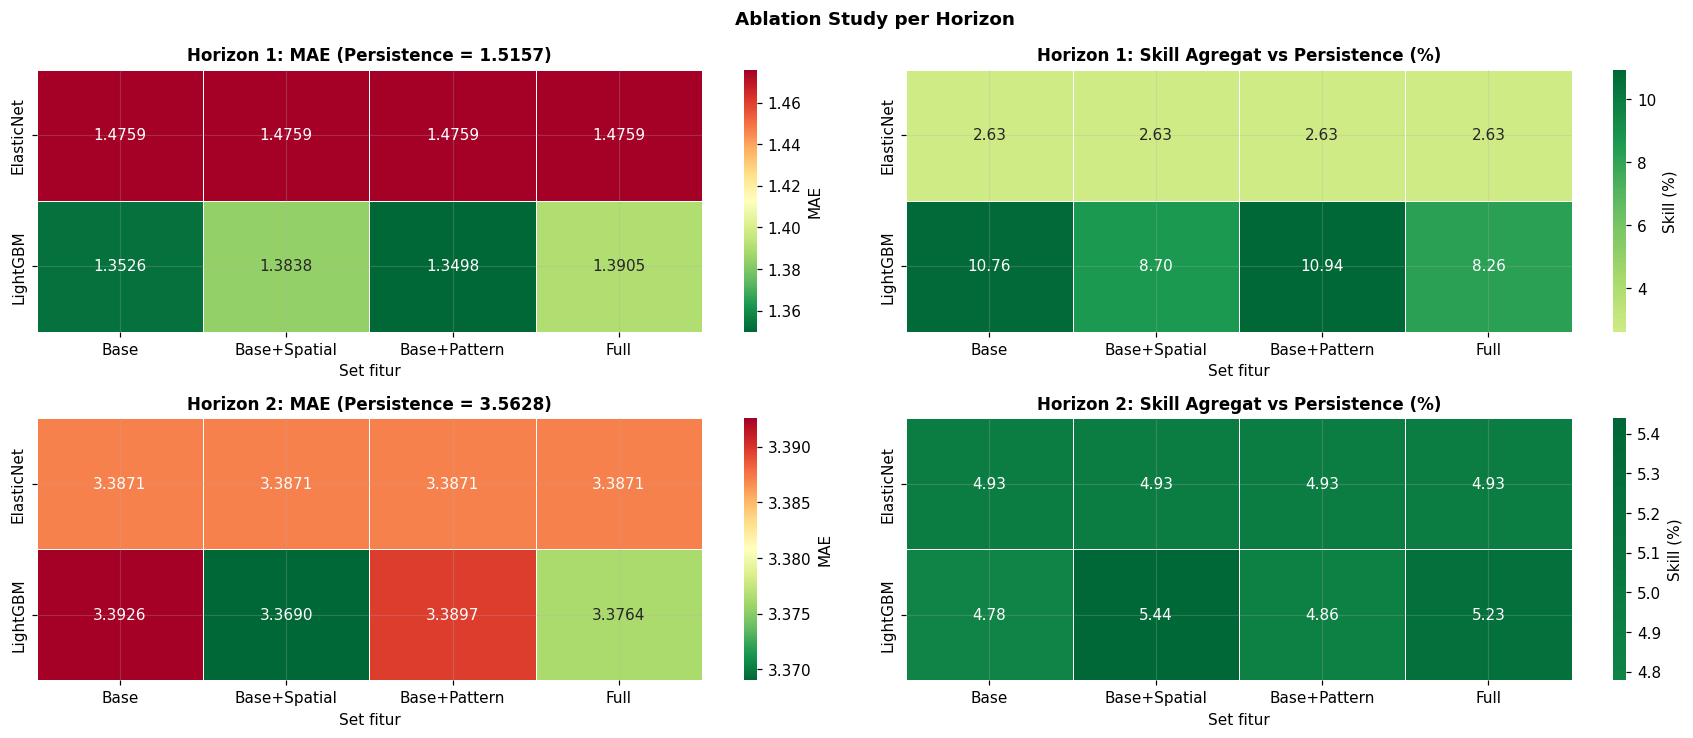

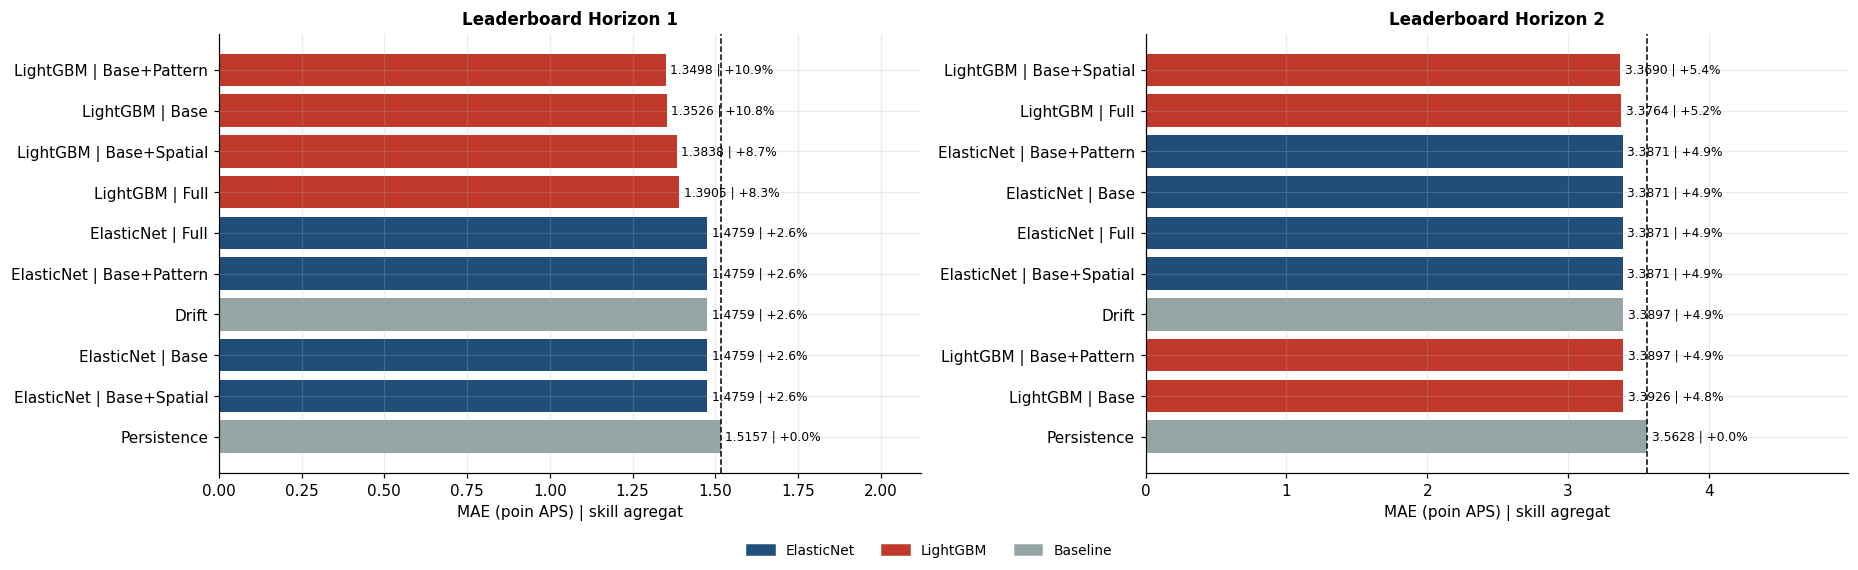

In [40]:
def oof_abs_error(h, model, fs):
    part = oof[(oof["horizon"] == h) & (oof["model"] == model) & (oof["fitur"] == fs)].sort_values(["fold", "provinsi"])
    return (part["aktual_delta"] - part["pred_delta"]).abs().to_numpy()


summaries, leaderboards = [], []
for h in HORIZONS:
    part = fold_metrics[fold_metrics["horizon"] == h]
    summ = (part.groupby(["model", "fitur"])[["MAE", "RMSE", "MAPE_persen", "R2_level", "R2_perubahan", "akurasi_arah"]].mean().reset_index())
    persist_h = summ.query("model == 'Persistence' and fitur == 'Full'")["MAE"].iloc[0]
    summ["skill_agregat"] = 1 - summ["MAE"] / persist_h
    persist_err = oof_abs_error(h, "Persistence", "Full")
    summ["p_wilcoxon_vs_persistence"] = [stats.wilcoxon(oof_abs_error(h, m, f), persist_err, alternative="less").pvalue
                                         if m != "Persistence" else np.nan for m, f in zip(summ["model"], summ["fitur"])]
    summ.insert(0, "horizon", h)
    summaries.append(summ)
    board = pd.concat([summ[summ["model"].isin(["Persistence", "Drift"]) & (summ["fitur"] == "Full")].assign(fitur="-"),
                       summ[summ["model"].isin(ML_MODELS)]]).sort_values("MAE").reset_index(drop=True)
    board.insert(1, "peringkat", np.arange(1, len(board) + 1))
    leaderboards.append(board)
summary = pd.concat(summaries, ignore_index=True)
leaderboard = pd.concat(leaderboards, ignore_index=True)
persist_mae = {h: summary.query("horizon == @h and model == 'Persistence' and fitur == 'Full'")["MAE"].iloc[0] for h in HORIZONS}
for h in HORIZONS:
    print(f"Leaderboard horizon {h} (rata-rata fold validasi; proyeksi akhir {FORECAST_YEAR[h]}):")
    print(leaderboard[leaderboard["horizon"] == h].drop(columns="horizon").round(4).to_string(index=False) + "\n")
save_table(leaderboard.round(5), "05_forecast", "leaderboard_model")

fig, axes = plt.subplots(len(HORIZONS), 2, figsize=(16, 3.4 * len(HORIZONS)))
for row, h in enumerate(HORIZONS):
    part = summary[(summary["horizon"] == h) & summary["model"].isin(ML_MODELS)]
    mae_tab = part.pivot(index="model", columns="fitur", values="MAE")[list(FEATURE_SETS)]
    skill_tab = part.pivot(index="model", columns="fitur", values="skill_agregat")[list(FEATURE_SETS)] * 100
    sns.heatmap(mae_tab, annot=True, fmt=".4f", cmap="RdYlGn_r", linewidths=0.5, ax=axes[row, 0], cbar_kws={"label": "MAE"})
    axes[row, 0].set_title(f"Horizon {h}: MAE (Persistence = {persist_mae[h]:.4f})", fontsize=11)
    sns.heatmap(skill_tab, annot=True, fmt=".2f", cmap="RdYlGn", center=0, linewidths=0.5, ax=axes[row, 1], cbar_kws={"label": "Skill (%)"})
    axes[row, 1].set_title(f"Horizon {h}: Skill Agregat vs Persistence (%)", fontsize=11)
    for ax in axes[row]:
        ax.set_xlabel("Set fitur")
        ax.set_ylabel("")
fig.suptitle("Ablation Study per Horizon", fontweight="bold")
fig.tight_layout()
save_fig(fig, "05_forecast", "ablation_heatmap")

fig, axes = plt.subplots(1, len(HORIZONS), figsize=(17, 5.2))
for ax, h in zip(axes, HORIZONS):
    board = leaderboard[leaderboard["horizon"] == h].iloc[::-1]
    labels = board["model"] + np.where(board["fitur"] == "-", "", " | " + board["fitur"])
    colors = np.where(board["model"].isin(["Persistence", "Drift"]), "#95A5A6",
                      np.where(board["model"] == "LightGBM", COLORS["accent"], COLORS["primary"]))
    bars = ax.barh(labels, board["MAE"], color=colors)
    ax.bar_label(bars, labels=[f"{m:.4f} | {s:+.1%}" for m, s in zip(board["MAE"], board["skill_agregat"])], fontsize=8, padding=3)
    ax.axvline(persist_mae[h], color="black", linestyle="--", linewidth=1)
    ax.set_xlim(0, board["MAE"].max() * 1.4)
    ax.set_xlabel("MAE (poin APS) | skill agregat")
    ax.set_title(f"Leaderboard Horizon {h}", fontsize=11)
fig.legend(handles=[Patch(color=COLORS["primary"], label="ElasticNet"), Patch(color=COLORS["accent"], label="LightGBM"),
                    Patch(color="#95A5A6", label="Baseline")], loc="lower center", ncol=3, fontsize=9)
fig.tight_layout(rect=(0, 0.05, 1, 1))
save_fig(fig, "05_forecast", "leaderboard_model")

### 7.4 Pemilihan Model Final dan Conformal Prediction

**Model terpilih untuk forecasting adalah kombinasi model dan set fitur dengan evaluasi terbaik**, yaitu MAE rata-rata validasi rolling-origin terendah di antara ElasticNet dan LightGBM pada keempat set fitur. Pemilihan dilakukan terpisah untuk setiap horizon, sehingga model 2026 dan 2027 boleh memakai set fitur berbeda.

Sebagai informasi pendukung ablation, konfigurasi terbaik dengan set fitur Full juga dibandingkan dengan model terpilih memakai uji Wilcoxon signed-rank satu arah pada galat absolut out-of-fold. Uji ini hanya menjelaskan apakah selisihnya bermakna, dan tidak mengubah model terpilih.

**Split conformal prediction** memberi interval prediksi dengan target cakupan 90% tanpa asumsi distribusi. Kuantil residual absolut out-of-fold dipakai sebagai lebar interval, terpisah untuk setiap horizon. Untuk horizon 1, cakupan empiris diuji secara jujur: residual fold 1-2 dipakai untuk membangun interval fold 3, lalu dihitung berapa persen nilai aktual 2025 yang jatuh di dalam interval. Horizon 2 hanya punya satu fold sehingga uji cakupan terpisah tidak dapat dilakukan.

Conformal prediction mengasumsikan galat masa depan sebanding dengan galat masa lalu. Jika rata-rata kenaikan APS nasional melonjak di tahun yang diprediksi, cakupan empiris bisa di bawah target, dan itu adalah sinyal pergeseran distribusi. Karena itu interval final dibangun dari seluruh residual out-of-fold, termasuk tahun lonjakan, sehingga lebih konservatif.

Diagnostik regularisasi ElasticNet juga dicetak: jumlah koefisien yang tidak nol menunjukkan seberapa banyak hubungan linear stabil yang ditemukan. Jika validasi silang memilih penalti besar sehingga hampir semua koefisien menjadi nol, ElasticNet pada dasarnya hanya memprediksi rata-rata perubahan (setara Drift). Itu bukan kegagalan teknis, melainkan bukti bahwa hubungan antara kondisi provinsi dan perubahan APS tidak linear, sehingga model non-linear seperti LightGBM diperlukan.

Model final setiap horizon kemudian dilatih ulang dengan seluruh sampelnya dan aturan yang ditambang dari seluruh transaksi, lalu memproyeksikan APS 16-18 tahun 2026 dan 2027 dari kondisi 2025.

In [41]:
def conformal_quantile(residuals, alpha):
    residuals = np.abs(np.asarray(residuals))
    n = len(residuals)
    level = min(1.0, np.ceil((n + 1) * (1 - alpha)) / n)
    return float(np.quantile(residuals, level, method="higher"))


final_rules = selected_rules.copy()
origin_2025 = add_pattern(panel[panel["tahun"] == 2025].reset_index(drop=True), final_rules)
FINAL, final_rows, conformal, coverage_rows, final_fit, train_sets = {}, {}, {}, [], {}, {}
for h in HORIZONS:
    summ_h = summary[(summary["horizon"] == h) & summary["model"].isin(ML_MODELS)]
    best_full = summ_h[summ_h["fitur"] == "Full"].sort_values("MAE").iloc[0]
    best_all = summ_h.sort_values("MAE").iloc[0]
    choice = (best_all["model"], best_all["fitur"])
    if (best_full["model"], best_full["fitur"]) == choice:
        p_select = np.nan
    else:
        p_select = stats.wilcoxon(oof_abs_error(h, best_full["model"], "Full"), oof_abs_error(h, *choice), alternative="greater").pvalue
    FINAL[h] = choice
    final_rows[h] = summ_h[(summ_h["model"] == choice[0]) & (summ_h["fitur"] == choice[1])].iloc[0]
    residual = oof[(oof["horizon"] == h) & (oof["model"] == choice[0]) & (oof["fitur"] == choice[1])]
    residual = residual.assign(residual=residual["aktual_delta"] - residual["pred_delta"])
    conformal[h] = conformal_quantile(residual["residual"], CONFORMAL_ALPHA)
    if residual["fold"].nunique() > 1:
        last = residual["fold"].max()
        for alpha in [0.10, 0.20]:
            q_cal = conformal_quantile(residual.loc[residual["fold"] < last, "residual"], alpha)
            covered = np.mean(np.abs(residual.loc[residual["fold"] == last, "residual"]) <= q_cal)
            coverage_rows.append({"horizon": h, "target_cakupan": 1 - alpha, "lebar_setengah_interval": q_cal,
                                  "cakupan_empiris": covered, "tahun_evaluasi": last + h})
    train_sets[h] = add_pattern(samples[h], final_rules)
    model = make_models()[choice[0]]
    model.fit(train_sets[h][FEATURE_SETS[choice[1]]], train_sets[h]["delta"])
    final_fit[h] = model
    print(f"Horizon {h} ({FORECAST_YEAR[h]})")
    print(f"  MODEL TERPILIH (evaluasi terbaik): {choice[0]} | {choice[1]} | MAE {final_rows[h]['MAE']:.4f} vs persistence {persist_mae[h]:.4f} | "
          f"skill {final_rows[h]['skill_agregat']:+.2%} | Wilcoxon vs persistence p = {final_rows[h]['p_wilcoxon_vs_persistence']:.4f}")
    print(f"  Interval conformal 90%: +/- {conformal[h]:.3f} poin (dari {len(residual)} residual out-of-fold)")
    print(f"  Pembanding ablation, terbaik dengan fitur Full: {best_full['model']} | MAE {best_full['MAE']:.4f}"
          + (f" | Wilcoxon Full lebih buruk p = {p_select:.4f}\n" if pd.notna(p_select) else " | sama dengan model terpilih\n"))
enet_rows = []
for h in HORIZONS:
    enet = make_models()["ElasticNet"].fit(train_sets[h][FEATURE_SETS["Full"]], train_sets[h]["delta"])
    est = enet.named_steps["elasticnetcv"]
    enet_rows.append({"horizon": h, "alpha_terpilih": est.alpha_, "l1_ratio_terpilih": est.l1_ratio_,
                      "koefisien_tidak_nol": int(np.sum(np.abs(est.coef_) > 1e-10)), "jumlah_fitur": len(est.coef_)})
enet_diag = pd.DataFrame(enet_rows)
print("Diagnostik regularisasi ElasticNet (fitur Full, seluruh data latih):\n" + enet_diag.round(5).to_string(index=False) + "\n")
save_table(enet_diag.round(6), "05_forecast", "diagnostik_elasticnet")
coverage = pd.DataFrame(coverage_rows)
print("Uji cakupan conformal horizon 1 (kalibrasi fold awal, evaluasi fold terakhir):\n" + coverage.round(4).to_string(index=False))
save_table(coverage.round(5), "05_forecast", "uji_cakupan_conformal")
save_table(pd.DataFrame([{"horizon": h, "tahun_proyeksi": FORECAST_YEAR[h], "model": FINAL[h][0], "set_fitur": FINAL[h][1],
                          "MAE": final_rows[h]["MAE"], "MAE_persistence": persist_mae[h], "skill_agregat": final_rows[h]["skill_agregat"],
                          "p_wilcoxon_vs_persistence": final_rows[h]["p_wilcoxon_vs_persistence"], "conformal_halfwidth_90": conformal[h]}
                         for h in HORIZONS]).round(5), "05_forecast", "model_final_per_horizon")


def predict_h(h, X):
    return final_fit[h].predict(pd.DataFrame(X, columns=FEATURE_SETS[FINAL[h][1]]))


forecast = origin_2025[["provinsi", "kode", "wilayah", "lon", "lat", TARGET]].rename(columns={TARGET: "aps_2025"})
for h in HORIZONS:
    year = FORECAST_YEAR[h]
    delta = predict_h(h, origin_2025[FEATURE_SETS[FINAL[h][1]]])
    forecast[f"delta_{year}"] = delta
    forecast[f"aps_{year}_pred"] = (forecast["aps_2025"] + delta).clip(upper=100)
    forecast[f"bawah_{year}"] = forecast[f"aps_{year}_pred"] - conformal[h]
    forecast[f"atas_{year}"] = (forecast[f"aps_{year}_pred"] + conformal[h]).clip(upper=100)
forecast["pred_delta"] = forecast["delta_2026"]
forecast = forecast.sort_values("aps_2026_pred").reset_index(drop=True)
print("\nProyeksi APS 16-18, sepuluh provinsi terendah 2026:")
print(forecast.head(10)[["provinsi", "aps_2025", "aps_2026_pred", "bawah_2026", "atas_2026", "aps_2027_pred", "bawah_2027", "atas_2027"]]
      .round(2).to_string(index=False))
save_table(forecast.round(4), "05_forecast", "forecast_aps_2026_2027")

Horizon 1 (2026)
  MODEL TERPILIH (evaluasi terbaik): LightGBM | Base+Pattern | MAE 1.3498 vs persistence 1.5157 | skill +10.94% | Wilcoxon vs persistence p = 0.0089
  Interval conformal 90%: +/- 3.204 poin (dari 104 residual out-of-fold)
  Pembanding ablation, terbaik dengan fitur Full: LightGBM | MAE 1.3905 | Wilcoxon Full lebih buruk p = 0.0115

Horizon 2 (2027)
  MODEL TERPILIH (evaluasi terbaik): LightGBM | Base+Spatial | MAE 3.3690 vs persistence 3.5628 | skill +5.44% | Wilcoxon vs persistence p = 0.0019
  Interval conformal 90%: +/- 6.621 poin (dari 32 residual out-of-fold)
  Pembanding ablation, terbaik dengan fitur Full: LightGBM | MAE 3.3764 | Wilcoxon Full lebih buruk p = 0.0888

Diagnostik regularisasi ElasticNet (fitur Full, seluruh data latih):
 horizon  alpha_terpilih  l1_ratio_terpilih  koefisien_tidak_nol  jumlah_fitur
       1         0.03625                0.1                   16            17
       2         0.14774                0.1                   13         

,provinsi,kode,wilayah,lon,lat,aps_2025,delta_2026,aps_2026_pred,bawah_2026,atas_2026,delta_2027,aps_2027_pred,bawah_2027,atas_2027,pred_delta
0,PAPUA TENGAH,PATENG,Maluku-Papua,135.50,-3.37,44.61,-1.2172,43.3928,40.1890,46.5966,3.0824,47.6924,41.0714,54.3134,-1.2172
1,PAPUA PEGUNUNGAN,PAPEG,Maluku-Papua,138.95,-4.10,50.79,-3.7286,47.0614,43.8576,50.2652,3.0971,53.8871,47.2661,60.5081,-3.7286
2,PAPUA SELATAN,PASEL,Maluku-Papua,140.40,-8.49,66.97,-2.5197,64.4503,61.2465,67.6541,1.9297,68.8997,62.2787,75.5207,-2.5197
3,SULAWESI UTARA,SULUT,Sulawesi,124.84,1.47,71.45,0.0282,71.4782,68.2744,74.6820,0.3834,71.8334,65.2124,78.4544,0.0282
4,GORONTALO,GORONTALO,Sulawesi,123.06,0.54,72.00,0.5342,72.5342,69.3304,75.7380,1.2765,73.2765,66.6555,79.8975,0.5342
5,KALIMANTAN BARAT,KALBAR,Kalimantan,109.33,-0.03,70.95,1.6301,72.5801,69.3763,75.7839,1.7435,72.6935,66.0725,79.3145,1.6301
6,KALIMANTAN TENGAH,KALTENG,Kalimantan,113.92,-2.21,70.76,2.5279,73.2879,70.0841,76.4917,5.1655,75.9255,69.3044,82.5465,2.5279
7,SUMATERA SELATAN,SUMSEL,Sumatera,104.76,-2.98,73.78,1.9243,75.7043,72.5005,78.9081,2.9192,76.6992,70.0782,83.3202,1.9243
8,SULAWESI BARAT,SULBAR,Sulawesi,118.89,-2.68,73.22,2.5286,75.7486,72.5447,78.9524,1.9168,75.1368,68.5158,81.7578,2.5286
9,BANTEN,BANTEN,Jawa,106.15,-6.12,73.84,2.7672,76.6072,73.4034,79.8110,4.9981,78.8381,72.2171,85.4592,2.7672


### 7.5 Diagnostik Prediksi

Panel kiri membandingkan prediksi model final horizon 1 pada fold terakhir (memprediksi 2025) dengan nilai aktual. Titik di garis diagonal berarti prediksi tepat, dan lima provinsi dengan kesalahan terbesar diberi label untuk dibahas di makalah. Panel kanan menampilkan MAE setiap fold untuk model final, baseline persistence, dan drift di kedua horizon.

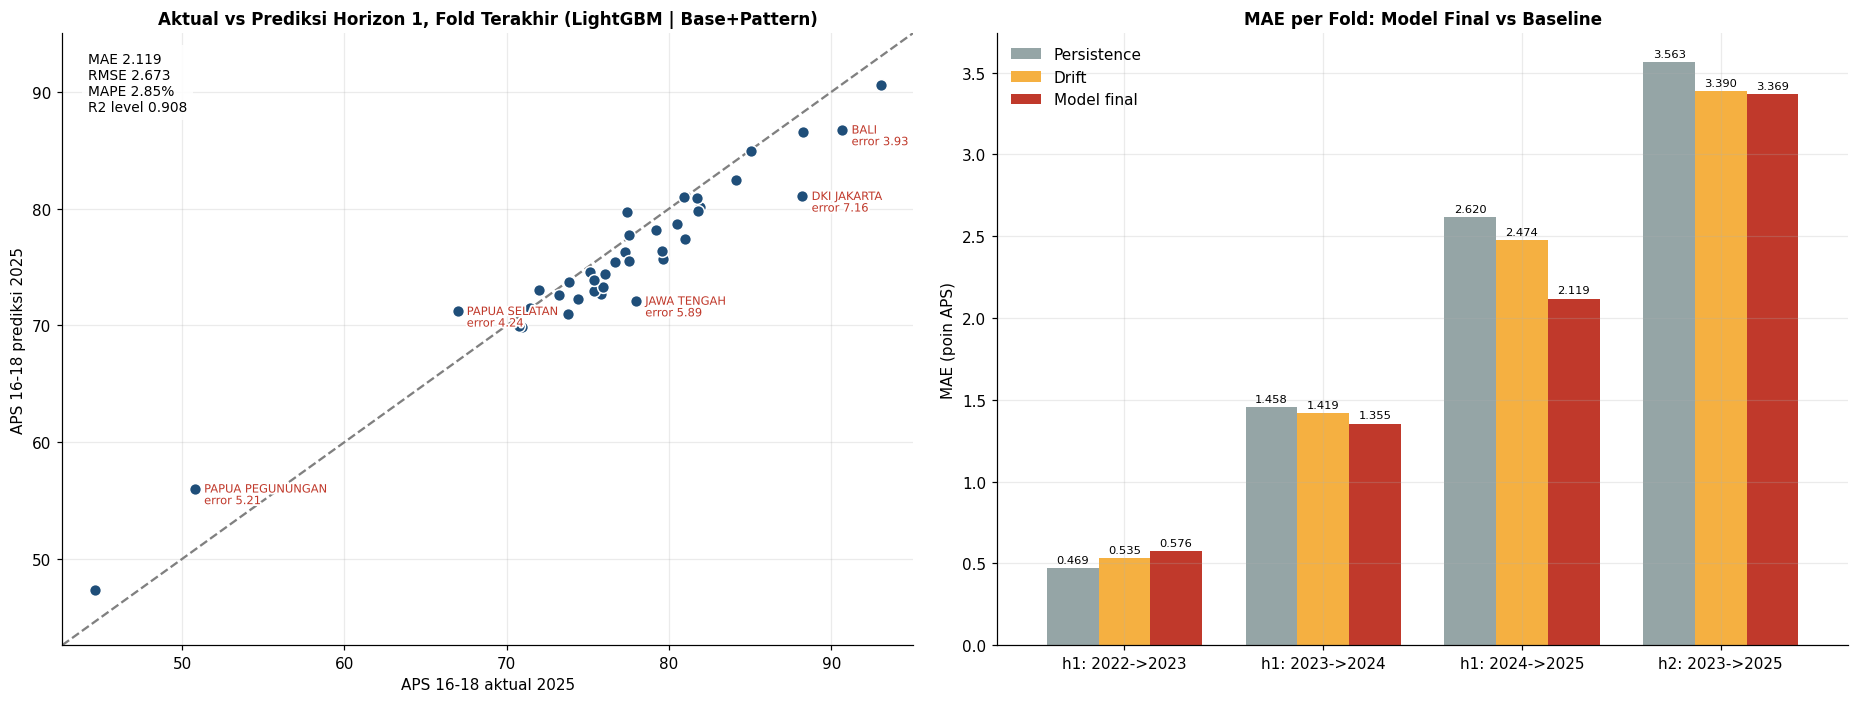

                Persistence   Drift  Model final
fold                                            
h1: 2022->2023       0.4694  0.5348       0.5758
h1: 2023->2024       1.4578  1.4188       1.3549
h1: 2024->2025       2.6200  2.4741       2.1189
h2: 2023->2025       3.5628  3.3897       3.3690


,fold,Persistence,Drift,Model final
0,h1: 2022->2023,0.46941,0.53484,0.57578
1,h1: 2023->2024,1.45781,1.41881,1.35486
2,h1: 2024->2025,2.62000,2.47405,2.11890
3,h2: 2023->2025,3.56281,3.38965,3.36902


In [42]:
h1_model, h1_fs = FINAL[1]
diag = oof[(oof["horizon"] == 1) & (oof["model"] == h1_model) & (oof["fitur"] == h1_fs) & (oof["fold"] == oof["fold"].max())].copy()
diag["aktual"] = diag["aps_now"] + diag["aktual_delta"]
diag["prediksi"] = diag["aps_now"] + diag["pred_delta"]
diag["abs_error"] = (diag["aktual"] - diag["prediksi"]).abs()
fig, axes = plt.subplots(1, 2, figsize=(17, 6.5))
axes[0].scatter(diag["aktual"], diag["prediksi"], s=60, color=COLORS["primary"], edgecolors="white", zorder=3)
lims = [diag[["aktual", "prediksi"]].min().min() - 2, diag[["aktual", "prediksi"]].max().max() + 2]
axes[0].plot(lims, lims, "--", color="grey")
for _, row in diag.nlargest(5, "abs_error").iterrows():
    outlined(axes[0].annotate(f"{row['provinsi']}\nerror {row['abs_error']:.2f}", (row["aktual"], row["prediksi"]),
                              xytext=(6, -10), textcoords="offset points", fontsize=7.5, color=COLORS["accent"]))
m = metrics(diag["aktual_delta"].to_numpy(), diag["pred_delta"].to_numpy(), diag["aps_now"].to_numpy())
axes[0].text(0.03, 0.97, f"MAE {m['MAE']:.3f}\nRMSE {m['RMSE']:.3f}\nMAPE {m['MAPE_persen']:.2f}%\nR2 level {m['R2_level']:.3f}",
             transform=axes[0].transAxes, va="top", fontsize=9, bbox=dict(facecolor="white", alpha=0.9, edgecolor="none"))
axes[0].set_xlim(lims)
axes[0].set_ylim(lims)
axes[0].set_xlabel("APS 16-18 aktual 2025")
axes[0].set_ylabel("APS 16-18 prediksi 2025")
axes[0].set_title(f"Aktual vs Prediksi Horizon 1, Fold Terakhir ({h1_model} | {h1_fs})", fontsize=11)

fold_rows = []
for h in HORIZONS:
    for test_year, _ in FOLDS[h]:
        part = fold_metrics[(fold_metrics["horizon"] == h) & (fold_metrics["fold"] == test_year)]
        fold_rows.append({"fold": f"h{h}: {test_year}->{test_year + h}",
                          "Persistence": part.query("model == 'Persistence' and fitur == 'Full'")["MAE"].iloc[0],
                          "Drift": part.query("model == 'Drift' and fitur == 'Full'")["MAE"].iloc[0],
                          "Model final": part[(part["model"] == FINAL[h][0]) & (part["fitur"] == FINAL[h][1])]["MAE"].iloc[0]})
per_fold = pd.DataFrame(fold_rows).set_index("fold")
per_fold.plot.bar(ax=axes[1], color=["#95A5A6", "#F5B041", COLORS["accent"]], rot=0, width=0.78)
label_bars(axes[1], fmt="{:.3f}", fontsize=7.5)
axes[1].set_ylabel("MAE (poin APS)")
axes[1].set_xlabel("")
axes[1].set_title("MAE per Fold: Model Final vs Baseline", fontsize=11)
fig.tight_layout()
save_fig(fig, "05_forecast", "diagnostik_prediksi")
print(per_fold.round(4).to_string())
save_table(per_fold.round(5).reset_index(), "05_forecast", "mae_per_fold_model_final")

### 7.6 Proyeksi APS 16-18 Tahun 2026 dan 2027

Grafik pertama menampilkan proyeksi 2026 dan 2027 untuk setiap provinsi lengkap dengan interval conformal 90%, serta titik hitam untuk nilai aktual 2025. Grafik kedua memperlihatkan lintasan provinsi dengan proyeksi terendah: garis penuh adalah data aktual 2021-2025, garis putus-putus adalah proyeksi, dan area berwarna adalah interval 90%. Peta di bagian akhir menunjukkan arah dan besar perubahan dua tahun (2025 ke 2027).

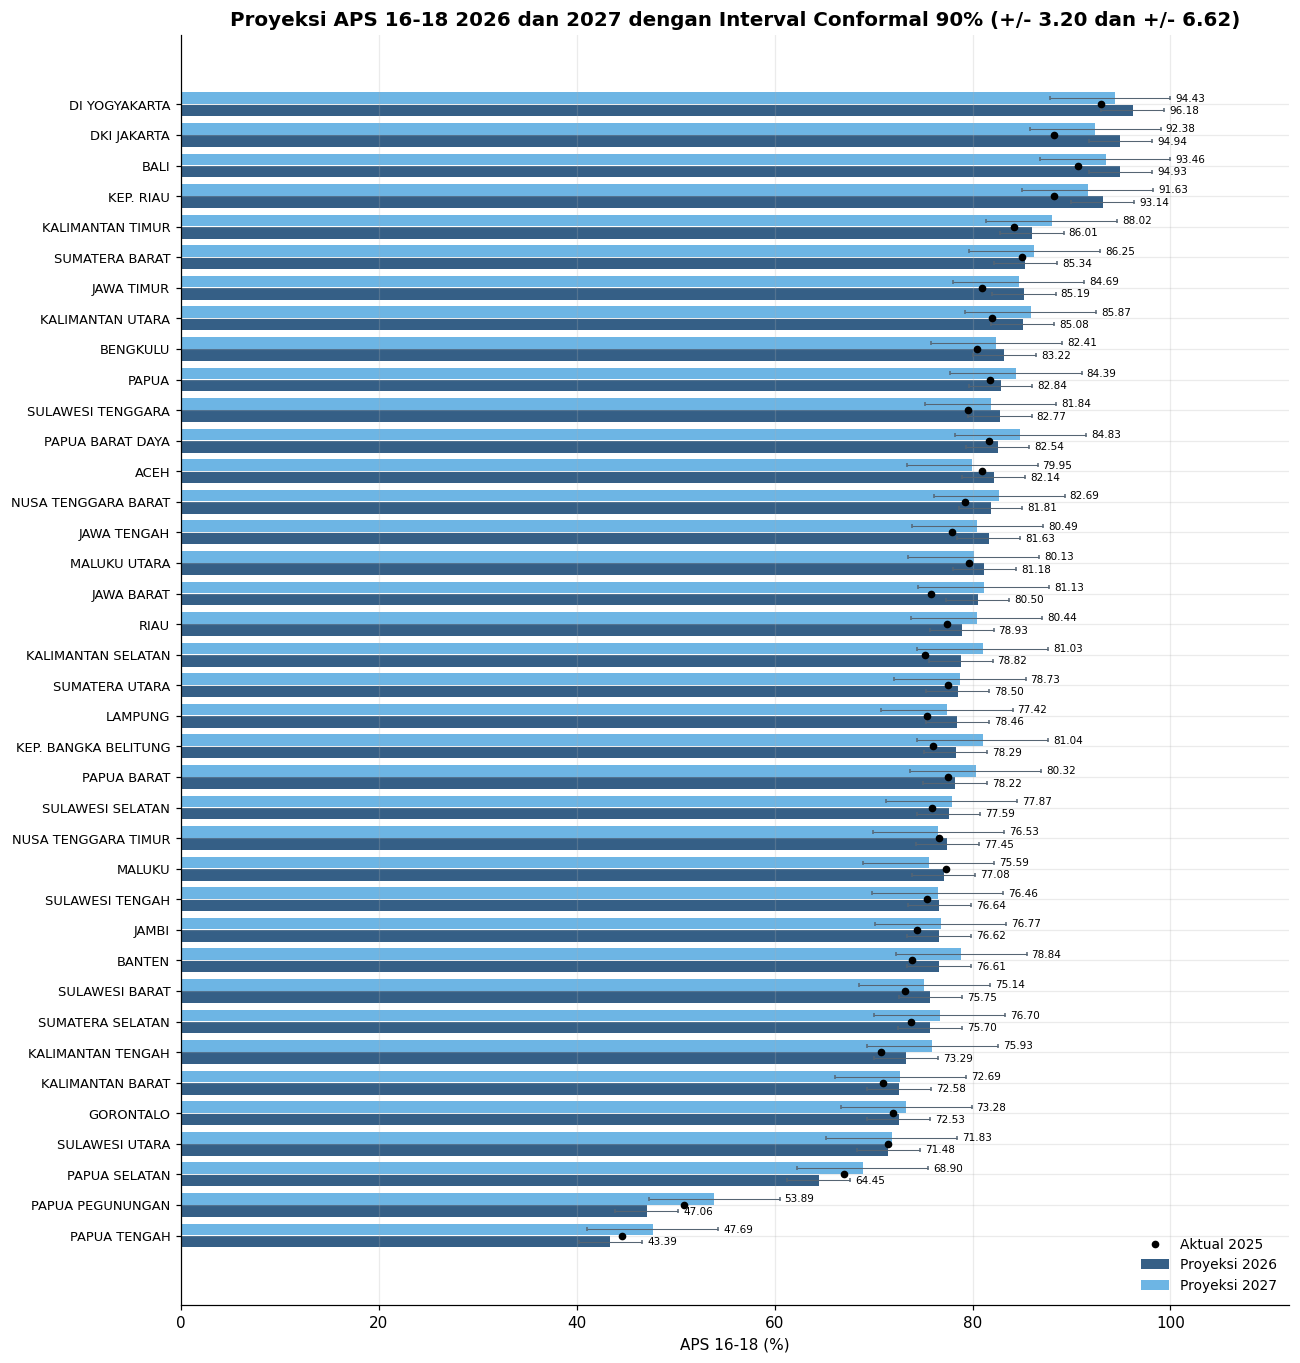

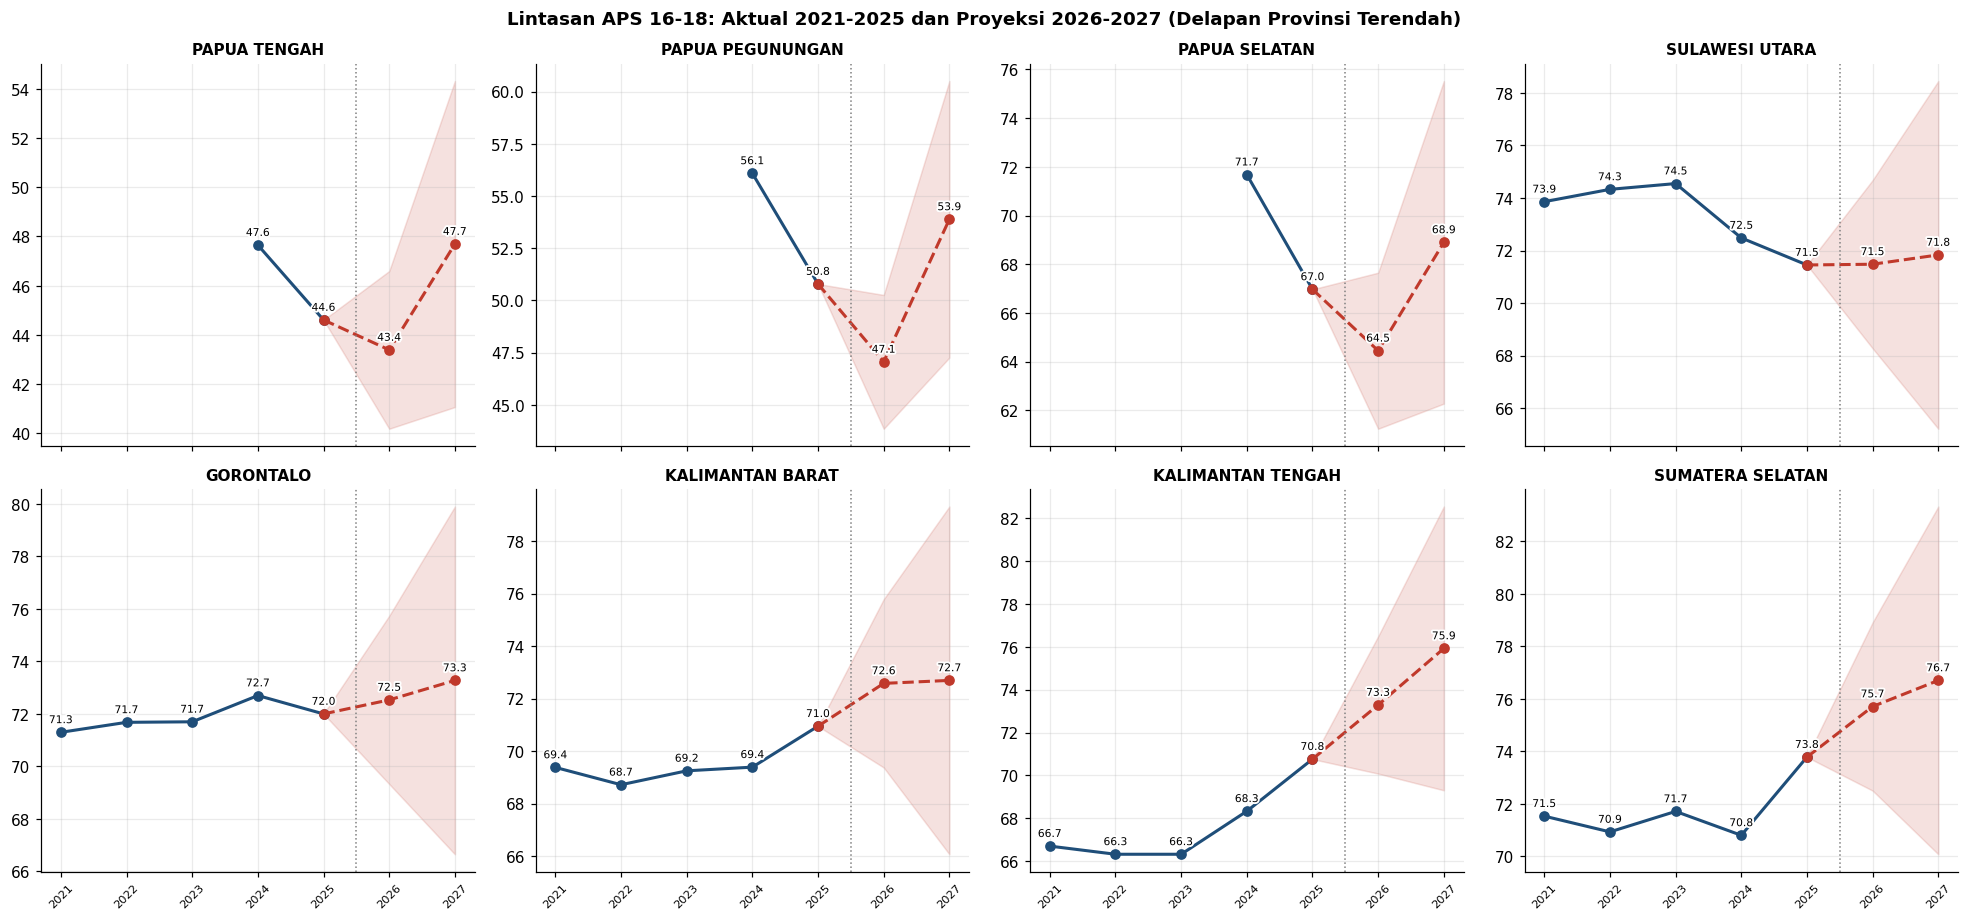

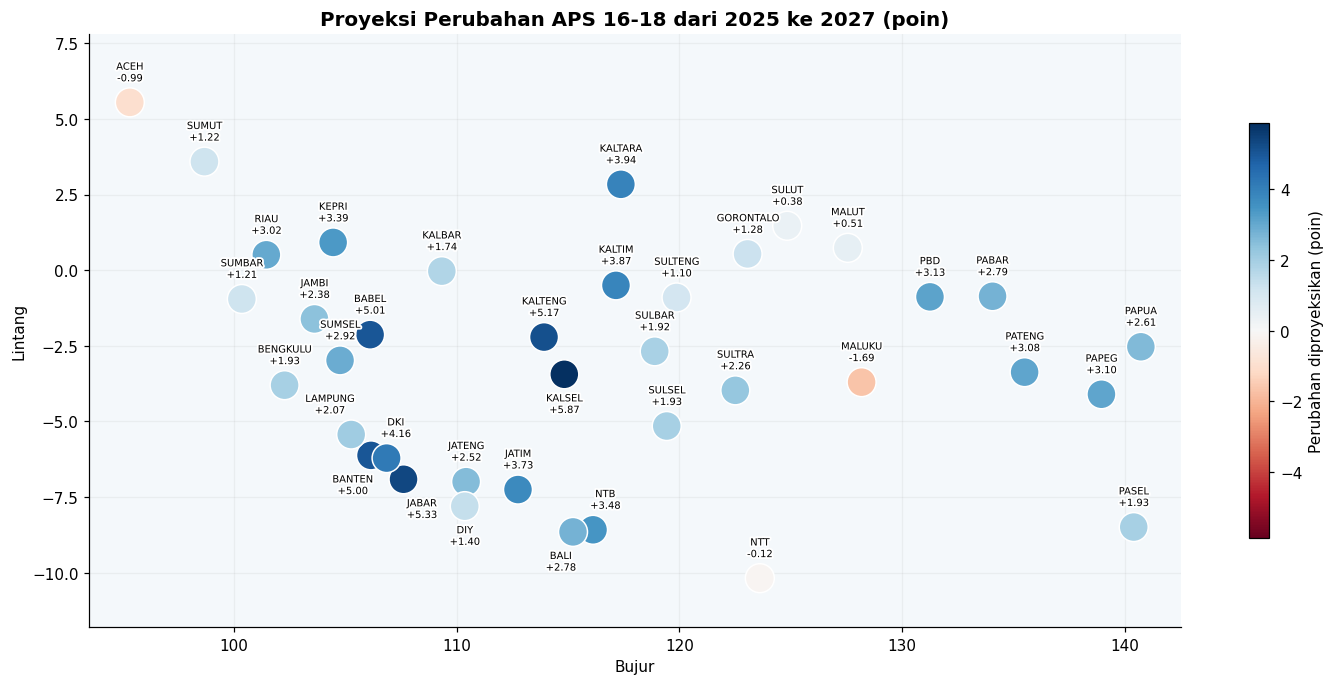

In [43]:
fig, ax = plt.subplots(figsize=(13, 15))
ypos = np.arange(len(forecast))
for offset, year, color in [(-0.2, 2026, COLORS["primary"]), (0.2, 2027, "#5DADE2")]:
    ax.barh(ypos + offset, forecast[f"aps_{year}_pred"], height=0.38, color=color, alpha=0.9, label=f"Proyeksi {year}",
            xerr=[forecast[f"aps_{year}_pred"] - forecast[f"bawah_{year}"], forecast[f"atas_{year}"] - forecast[f"aps_{year}_pred"]],
            error_kw={"ecolor": "#566573", "capsize": 1.5, "elinewidth": 0.7})
    for y, (value, upper) in enumerate(zip(forecast[f"aps_{year}_pred"], forecast[f"atas_{year}"])):
        ax.text(upper + 0.5, y + offset, f"{value:.2f}", va="center", fontsize=6.8)
ax.scatter(forecast["aps_2025"], ypos, color="black", s=16, zorder=4, label="Aktual 2025")
ax.set_yticks(ypos)
ax.set_yticklabels(forecast["provinsi"], fontsize=8.5)
ax.set_xlim(0, 112)
ax.set_xlabel("APS 16-18 (%)")
ax.set_title(f"Proyeksi APS 16-18 2026 dan 2027 dengan Interval Conformal 90% "
             f"(+/- {conformal[1]:.2f} dan +/- {conformal[2]:.2f})")
ax.legend(loc="lower right", fontsize=9)
save_fig(fig, "05_forecast", "proyeksi_2026_2027")

watch = forecast.head(8)["provinsi"].tolist()
history = analysis.pivot(index="provinsi", columns="tahun", values=TARGET)
fig, axes = plt.subplots(2, 4, figsize=(18, 8.5), sharex=True)
for ax, prov in zip(axes.ravel(), watch):
    hist = history.loc[prov].dropna()
    fc = forecast.set_index("provinsi").loc[prov]
    ax.plot(hist.index, hist.to_numpy(), marker="o", color=COLORS["primary"], linewidth=2)
    years = [2025, 2026, 2027]
    values = [fc["aps_2025"], fc["aps_2026_pred"], fc["aps_2027_pred"]]
    ax.plot(years, values, "--", marker="o", color=COLORS["accent"], linewidth=2)
    ax.fill_between(years, [fc["aps_2025"], fc["bawah_2026"], fc["bawah_2027"]], [fc["aps_2025"], fc["atas_2026"], fc["atas_2027"]],
                    color=COLORS["accent"], alpha=0.15)
    for x, y in list(zip(hist.index, hist.to_numpy())) + list(zip(years[1:], values[1:])):
        outlined(ax.annotate(f"{y:.1f}", (x, y), xytext=(0, 6), textcoords="offset points", ha="center", fontsize=7))
    ax.axvline(2025.5, color="grey", linestyle=":", linewidth=1)
    ax.set_title(prov, fontsize=10)
    ax.set_xticks(range(2021, 2028))
    ax.tick_params(axis="x", labelsize=7.5, rotation=45)
fig.suptitle("Lintasan APS 16-18: Aktual 2021-2025 dan Proyeksi 2026-2027 (Delapan Provinsi Terendah)", fontweight="bold")
fig.tight_layout()
save_fig(fig, "05_forecast", "lintasan_provinsi_prioritas")

fig, ax = plt.subplots(figsize=(16, 7))
change = forecast["aps_2027_pred"] - forecast["aps_2025"]
limit = max(change.abs().max(), 0.5)
norm = plt.Normalize(-limit, limit)
province_map(ax, forecast.assign(perubahan_2th=change), plt.cm.RdBu(norm(change)), size=360, value_col="perubahan_2th",
             value_fmt="{:+.2f}", title="Proyeksi Perubahan APS 16-18 dari 2025 ke 2027 (poin)")
fig.colorbar(plt.cm.ScalarMappable(norm=norm, cmap="RdBu"), ax=ax, shrink=0.7, label="Perubahan diproyeksikan (poin)")
save_fig(fig, "05_forecast", "peta_proyeksi_perubahan_2027")

## 8. Explainable AI dengan SHAP

### 8.1 Kepentingan Fitur Global

SHAP (SHapley Additive exPlanations) membagi setiap prediksi menjadi kontribusi masing-masing fitur secara adil berdasarkan teori permainan kooperatif. Bagian ini menjelaskan model final horizon 1 (proyeksi 2026), sedangkan perbandingan pendorong 2026 dan 2027 ada di bagian 8.7. Nilai SHAP dihitung secara eksak: untuk ElasticNet melalui koefisien linear terhadap rata-rata data latar, dan untuk LightGBM melalui TreeSHAP bawaan LightGBM (`pred_contrib`). Aditivitas diperiksa: jumlah SHAP ditambah base value harus sama dengan prediksi model.

Panel kanan menjumlahkan kepentingan per blok fitur pada varian model yang memakai set fitur Full (jika model final bukan Full, varian Full dilatih khusus untuk analisis ini). Ini menjawab langsung pertanyaan integrasi: seberapa besar porsi penjelasan yang berasal dari hasil analisis spasial dan pattern mining ketika informasi itu tersedia bagi model.

Model yang dijelaskan: horizon 1 (2026), LightGBM | Base+Pattern
Base value (nilai harapan model): +0.6626
Pemeriksaan aditivitas SHAP (selisih maksimum): 7.55e-15
                  fitur                          label                        blok  mean_abs_shap  porsi_persen
                listrik    Rumah Tangga Berlistrik (%) Sosial-ekonomi & pendidikan         0.5467       19.2727
                 miskin            Penduduk Miskin (%) Sosial-ekonomi & pendidikan         0.3533       12.4533
                    ikp        Indeks Ketahanan Pangan Sosial-ekonomi & pendidikan         0.3095       10.9086
log_pengeluaran_makanan        log Pengeluaran Makanan Sosial-ekonomi & pendidikan         0.2914       10.2714
                    tpt       Pengangguran Terbuka (%) Sosial-ekonomi & pendidikan         0.2601        9.1680
        log_pdrb_kapita            log PDRB per Kapita Sosial-ekonomi & pendidikan         0.2241        7.8994
        air_minum_layak            Air Minum Layak (

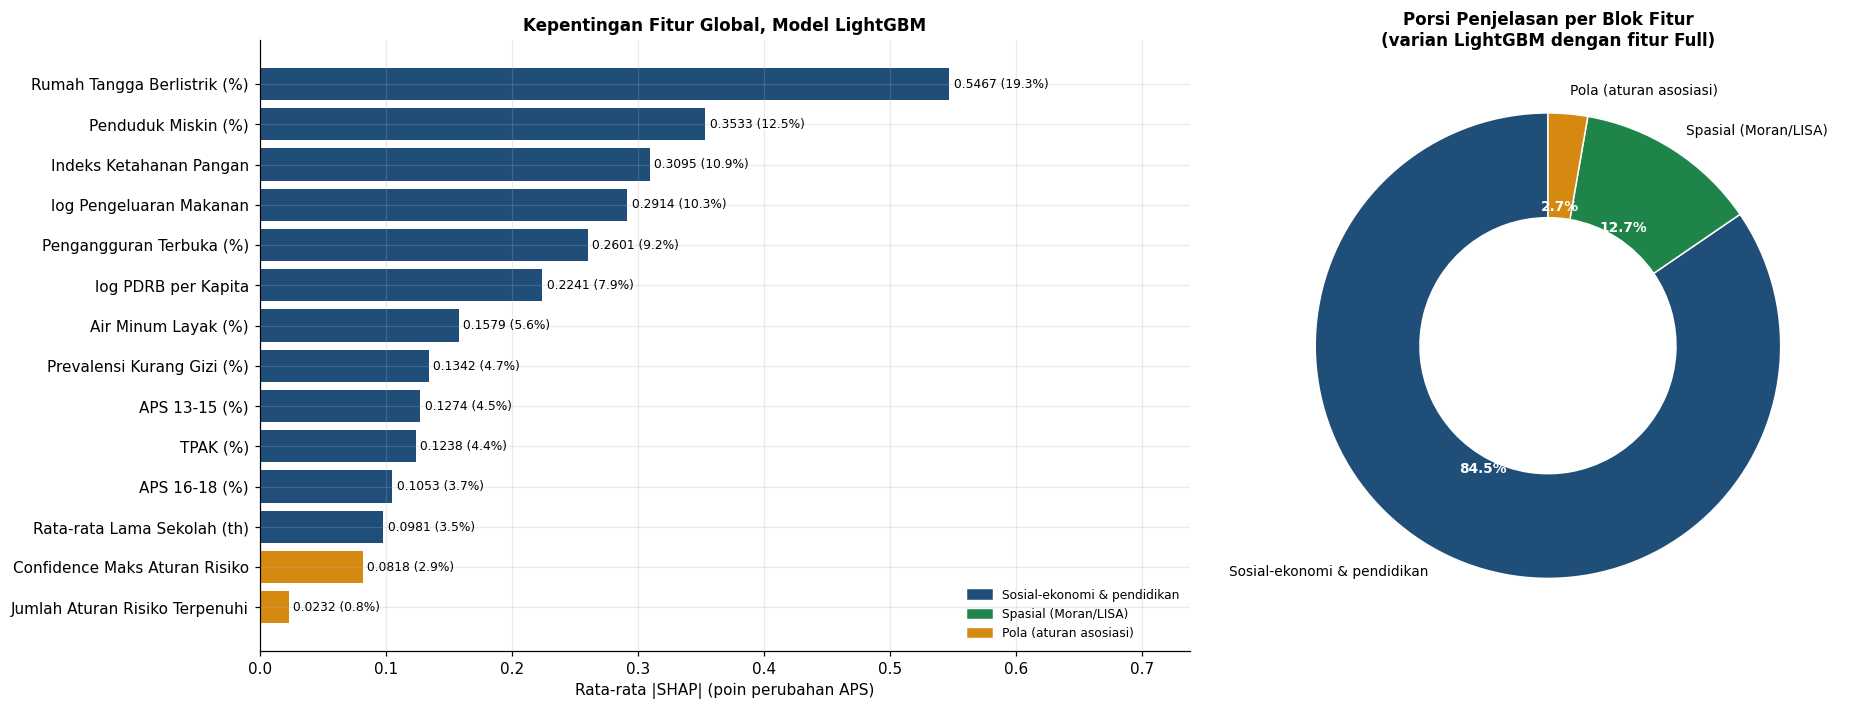

In [44]:
FINAL_MODEL, FINAL_FS = FINAL[1]
features_final = FEATURE_SETS[FINAL_FS]
train_all = train_sets[1]
background = train_all[features_final].sample(n=min(100, len(train_all)), random_state=SEED)


def predict_final(X):
    return predict_h(1, X)


def shap_for(name, model, X, bg):
    if name == "ElasticNet":
        scaler, enet = model.named_steps["standardscaler"], model.named_steps["elasticnetcv"]
        coef = enet.coef_ / scaler.scale_
        return (X.to_numpy() - bg.mean().to_numpy()) * coef, float(model.predict(bg).mean())
    contrib = model.booster_.predict(X, pred_contrib=True)
    return contrib[:, :-1], float(contrib[0, -1])


X_explain = pd.concat([train_all[features_final], origin_2025[features_final]], ignore_index=True)
shap_values, base_value = shap_for(FINAL_MODEL, final_fit[1], X_explain, background)
print(f"Model yang dijelaskan: horizon 1 (2026), {FINAL_MODEL} | {FINAL_FS}")
check = np.abs(shap_values.sum(axis=1) + base_value - predict_final(X_explain)).max()
print(f"Base value (nilai harapan model): {base_value:+.4f}")
print(f"Pemeriksaan aditivitas SHAP (selisih maksimum): {check:.2e}")

importance = pd.DataFrame({"fitur": features_final, "label": [LABELS[f] for f in features_final],
                           "blok": [FEATURE_GROUP[f] for f in features_final],
                           "mean_abs_shap": np.abs(shap_values).mean(axis=0)}).sort_values("mean_abs_shap", ascending=False)
importance["porsi_persen"] = importance["mean_abs_shap"] / importance["mean_abs_shap"].sum() * 100
features_all = FEATURE_SETS["Full"]
if FINAL_FS == "Full":
    full_shap = shap_values[:len(train_all)]
else:
    full_variant = make_models()[FINAL_MODEL].fit(train_all[features_all], train_all["delta"])
    bg_all = train_all[features_all].sample(n=min(100, len(train_all)), random_state=SEED)
    full_shap = shap_for(FINAL_MODEL, full_variant, train_all[features_all], bg_all)[0]
block_abs = pd.Series(np.abs(full_shap).mean(axis=0), index=features_all)
group_importance = (block_abs.groupby(lambda f: FEATURE_GROUP[f]).sum() / block_abs.sum() * 100).sort_values(ascending=False)
full_importance = pd.DataFrame({"fitur": features_all, "label": [LABELS[f] for f in features_all],
                                "blok": [FEATURE_GROUP[f] for f in features_all], "mean_abs_shap": block_abs.to_numpy()}
                               ).sort_values("mean_abs_shap", ascending=False)
print(importance.round(4).to_string(index=False))
print(f"\nPorsi kepentingan per blok fitur pada varian {FINAL_MODEL} dengan fitur Full (%):\n" + group_importance.round(2).to_string())
print("\nPeringkat fitur spasial dan pola pada varian Full:")
print(full_importance.reset_index(drop=True).assign(peringkat=lambda d: d.index + 1)
      .query("blok != 'Sosial-ekonomi & pendidikan'")[["peringkat", "label", "blok", "mean_abs_shap"]].round(4).to_string(index=False))
save_table(full_importance.round(5), "06_xai", "shap_kepentingan_varian_full")
save_table(importance.round(5), "06_xai", "shap_kepentingan_global")
save_table(group_importance.round(4).reset_index(), "06_xai", "shap_kepentingan_per_blok")

BLOCK_COLORS = {"Sosial-ekonomi & pendidikan": COLORS["primary"], "Spasial (Moran/LISA)": COLORS["good"], "Pola (aturan asosiasi)": COLORS["warn"]}
fig, axes = plt.subplots(1, 2, figsize=(17, 6.5), gridspec_kw={"width_ratios": [1.6, 1]})
plot_imp = importance.iloc[::-1]
bars = axes[0].barh(plot_imp["label"], plot_imp["mean_abs_shap"], color=plot_imp["blok"].map(BLOCK_COLORS))
axes[0].bar_label(bars, labels=[f"{v:.4f} ({p:.1f}%)" for v, p in zip(plot_imp["mean_abs_shap"], plot_imp["porsi_persen"])], fontsize=8, padding=3)
axes[0].set_xlim(0, plot_imp["mean_abs_shap"].max() * 1.35)
axes[0].set_xlabel("Rata-rata |SHAP| (poin perubahan APS)")
axes[0].set_title(f"Kepentingan Fitur Global, Model {FINAL_MODEL}", fontsize=11)
axes[0].legend(handles=[Patch(color=c, label=b) for b, c in BLOCK_COLORS.items()], loc="lower right", fontsize=8)
wedges, texts, autotexts = axes[1].pie(group_importance, labels=group_importance.index, autopct="%1.1f%%", startangle=90,
                                       colors=[BLOCK_COLORS[b] for b in group_importance.index],
                                       wedgeprops={"width": 0.45, "edgecolor": "white"}, textprops={"fontsize": 9})
for t in autotexts:
    t.set_color("white")
    t.set_fontweight("bold")
axes[1].set_title(f"Porsi Penjelasan per Blok Fitur\n(varian {FINAL_MODEL} dengan fitur Full)", fontsize=11)
fig.tight_layout()
save_fig(fig, "06_xai", "shap_kepentingan_global")

### 8.2 Distribusi Nilai SHAP

Setiap titik adalah satu provinsi-tahun. Posisi horizontal adalah kontribusi fitur terhadap prediksi perubahan APS, warna adalah nilai fitur (merah tinggi, biru rendah). Pola ini menunjukkan arah pengaruh: misalnya, jika titik merah kemiskinan berada di kiri, kemiskinan tinggi menekan proyeksi APS.

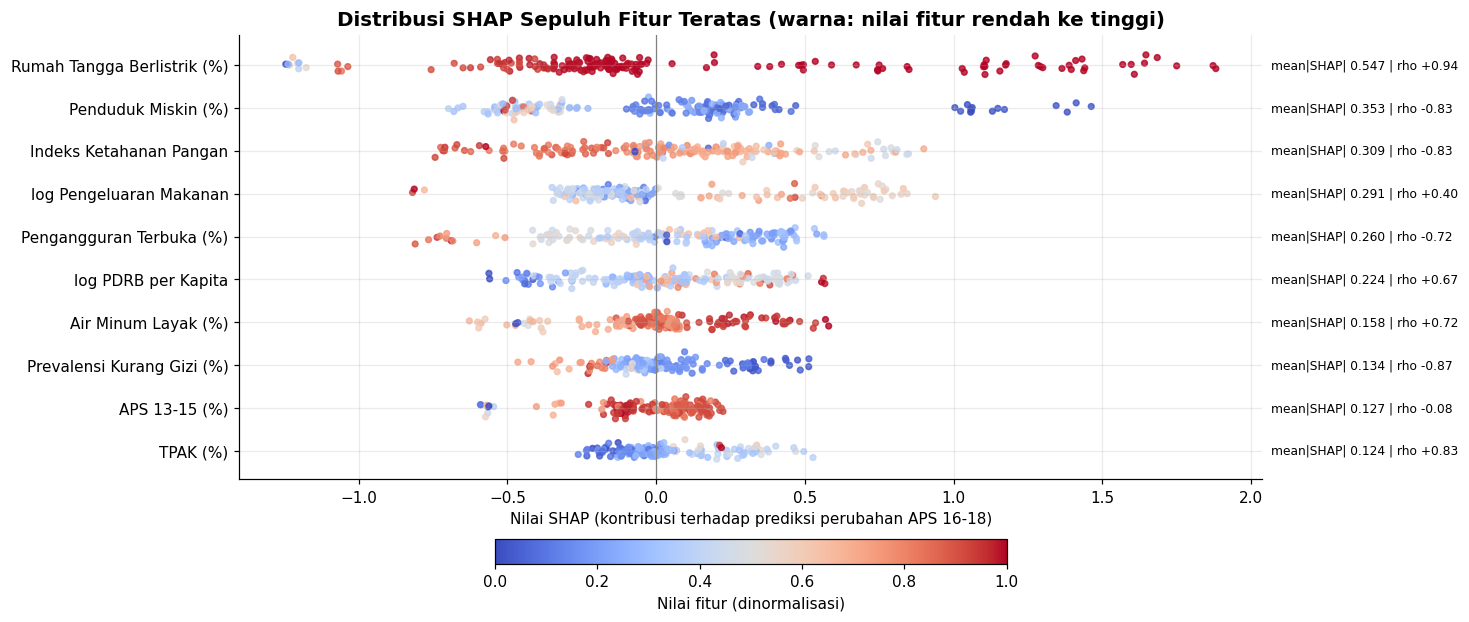

In [45]:
top_features = importance["fitur"].head(10).tolist()
fig, ax = plt.subplots(figsize=(12, 7))
for pos, feat in enumerate(top_features[::-1]):
    idx = features_final.index(feat)
    values = X_explain[feat].to_numpy()
    scaled = (values - values.min()) / (values.max() - values.min() + 1e-12)
    jitter = np.random.default_rng(SEED + pos).normal(0, 0.09, len(values))
    ax.scatter(shap_values[:, idx], pos + jitter, c=scaled, cmap="coolwarm", s=14, alpha=0.8)
    corr_dir = stats.spearmanr(values, shap_values[:, idx])[0] if np.std(values) > 0 else 0
    ax.annotate(f"mean|SHAP| {np.abs(shap_values[:, idx]).mean():.3f} | rho {corr_dir:+.2f}", xy=(1.0, pos),
                xycoords=("axes fraction", "data"), xytext=(6, 0), textcoords="offset points", va="center", fontsize=8)
ax.set_yticks(range(len(top_features)))
ax.set_yticklabels([LABELS[f] for f in top_features[::-1]])
ax.axvline(0, color="grey", linewidth=0.8)
ax.set_xlabel("Nilai SHAP (kontribusi terhadap prediksi perubahan APS 16-18)")
ax.set_title("Distribusi SHAP Sepuluh Fitur Teratas (warna: nilai fitur rendah ke tinggi)")
fig.colorbar(plt.cm.ScalarMappable(cmap="coolwarm"), ax=ax, orientation="horizontal", pad=0.1, shrink=0.5, label="Nilai fitur (dinormalisasi)")
save_fig(fig, "06_xai", "shap_distribusi")

### 8.3 Dependence Plot Fitur Utama

Dependence plot memperlihatkan bentuk hubungan antara nilai fitur dan kontribusinya. Garis tren LOWESS sederhana (rata-rata bergerak) membantu membaca apakah hubungan linear, berambang, atau jenuh. Nilai rho Spearman antara fitur dan SHAP-nya dicantumkan sebagai ringkasan arah.

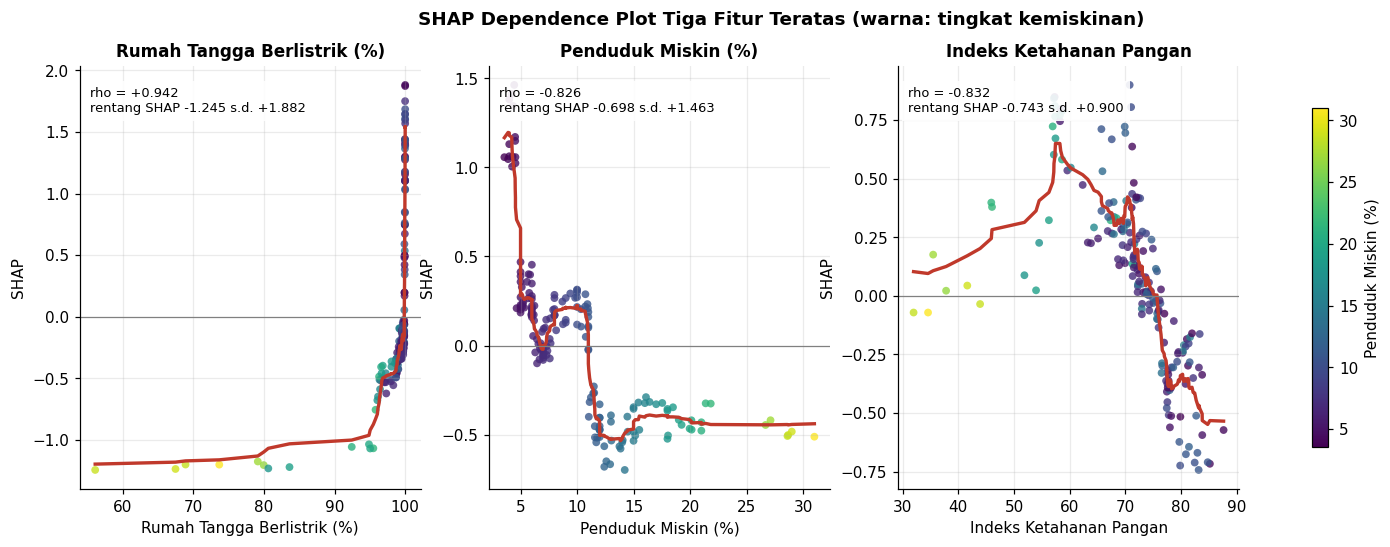

In [46]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
for ax, feat in zip(axes, top_features[:3]):
    idx = features_final.index(feat)
    x, y = X_explain[feat].to_numpy(), shap_values[:, idx]
    ax.scatter(x, y, c=X_explain["miskin"], cmap="viridis", s=26, alpha=0.8, edgecolors="none")
    order = np.argsort(x)
    window = max(5, len(x) // 10)
    smooth = pd.Series(y[order]).rolling(window, center=True, min_periods=3).mean()
    ax.plot(x[order], smooth, color=COLORS["accent"], linewidth=2.2)
    rho = stats.spearmanr(x, y)[0] if np.std(x) > 0 else 0
    ax.text(0.03, 0.95, f"rho = {rho:+.3f}\nrentang SHAP {y.min():+.3f} s.d. {y.max():+.3f}", transform=ax.transAxes, va="top",
            fontsize=8.5, bbox=dict(facecolor="white", alpha=0.9, edgecolor="none"))
    ax.axhline(0, color="grey", linewidth=0.8)
    ax.set_xlabel(LABELS[feat])
    ax.set_ylabel("SHAP")
    ax.set_title(LABELS[feat], fontsize=11)
fig.colorbar(plt.cm.ScalarMappable(norm=plt.Normalize(X_explain["miskin"].min(), X_explain["miskin"].max()), cmap="viridis"),
             ax=axes, shrink=0.8, label=LABELS["miskin"])
fig.suptitle("SHAP Dependence Plot Tiga Fitur Teratas (warna: tingkat kemiskinan)", fontweight="bold")
save_fig(fig, "06_xai", "shap_dependence")

### 8.4 Penjelasan Lokal Provinsi dengan Proyeksi Terendah

Waterfall plot menguraikan prediksi perubahan APS 2026 untuk empat provinsi dengan proyeksi terendah. Batang merah menurunkan proyeksi, batang biru menaikkan. Fitur yang paling menekan proyeksi adalah kandidat **tuas intervensi** untuk provinsi tersebut.

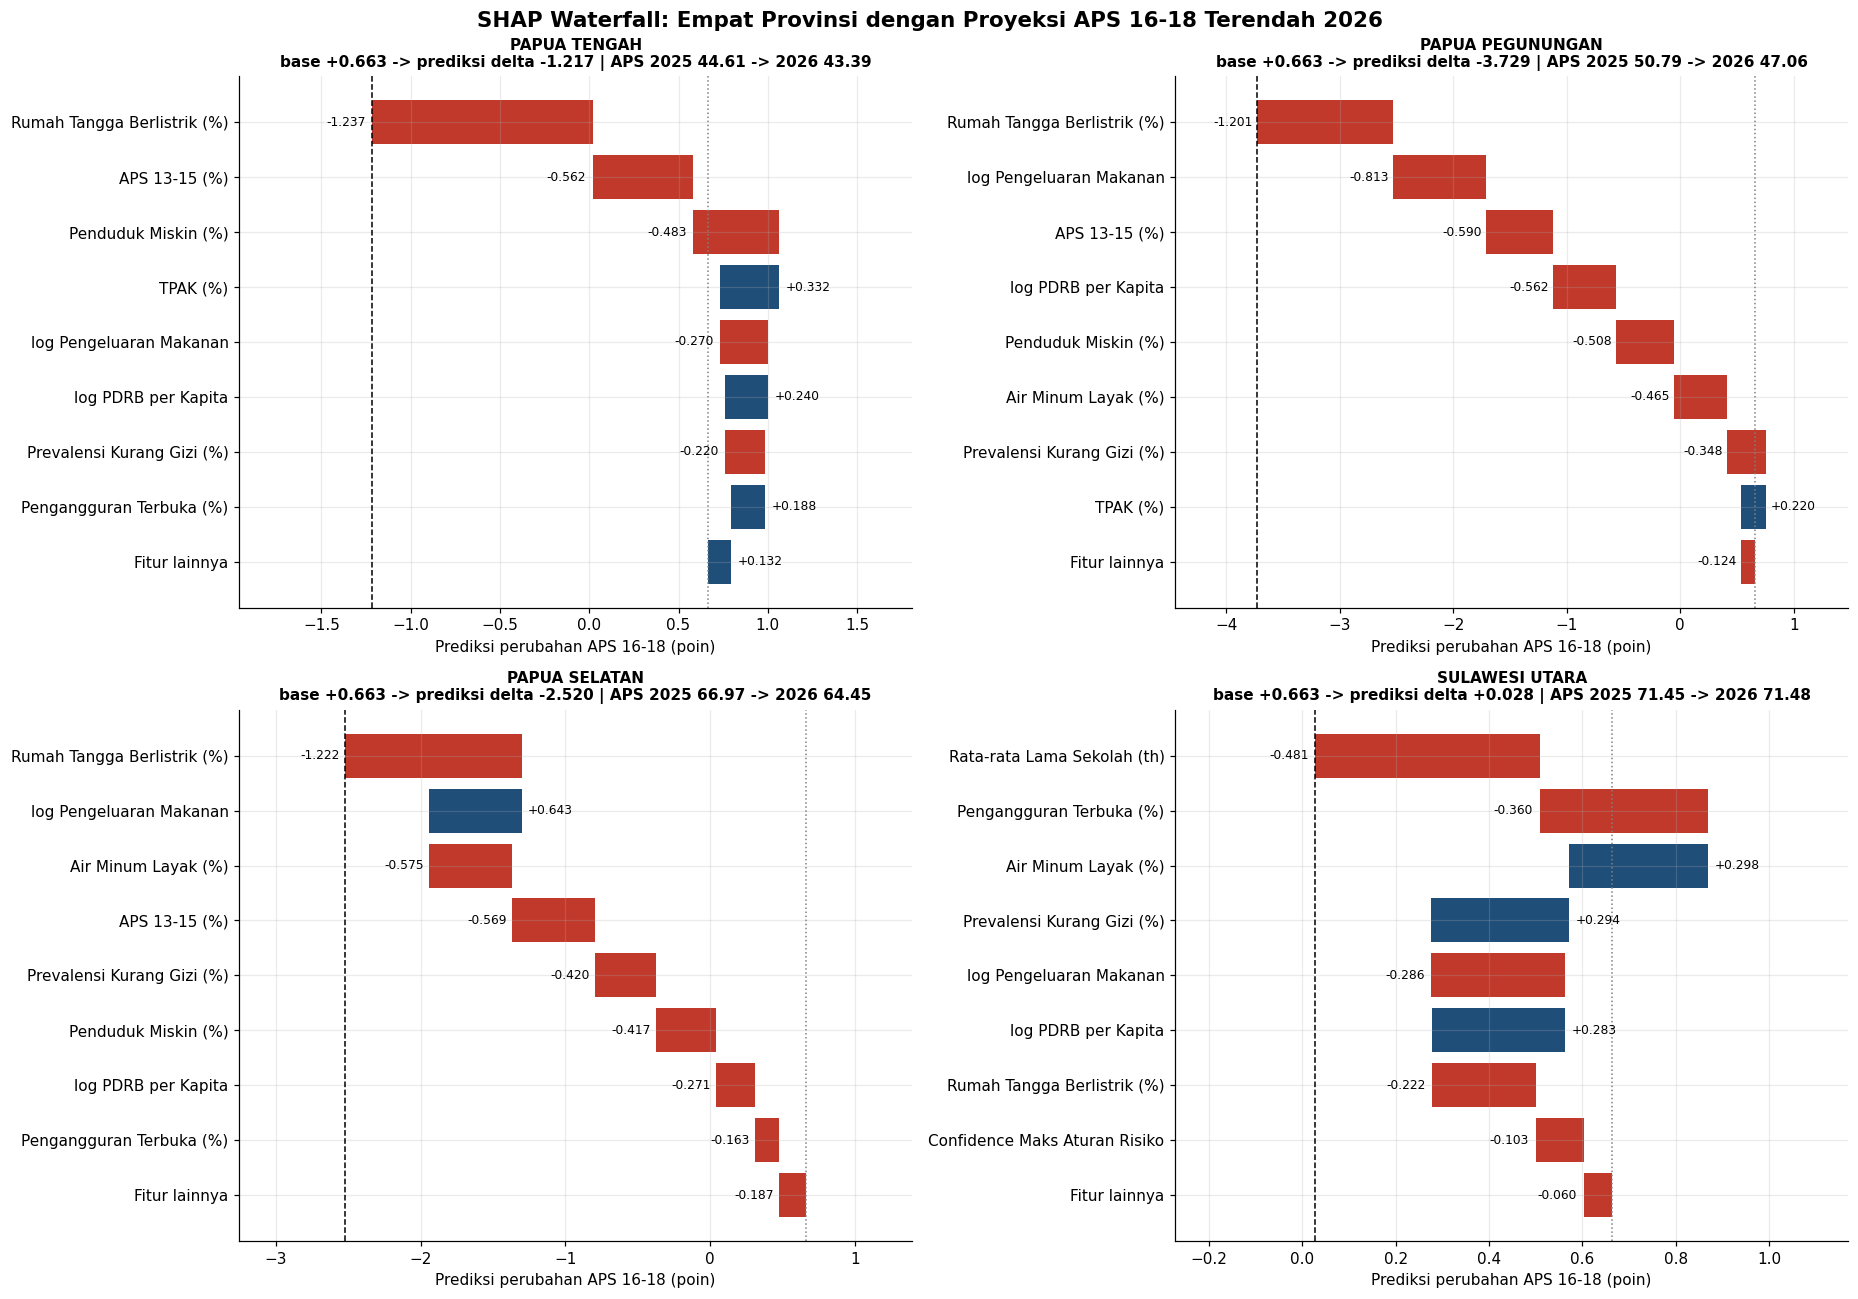

In [47]:
shap_2026 = shap_values[len(train_all):]
local_2026 = pd.DataFrame(shap_2026, columns=features_final)
local_2026.insert(0, "provinsi", origin_2025["provinsi"].to_numpy())
save_table(local_2026.round(5), "06_xai", "shap_lokal_2026")
critical = forecast.head(4)["provinsi"].tolist()
fig, axes = plt.subplots(2, 2, figsize=(17, 12))
for ax, prov in zip(axes.ravel(), critical):
    row_idx = int(np.where(origin_2025["provinsi"] == prov)[0][0])
    contrib = pd.Series(shap_2026[row_idx], index=[LABELS[f] for f in features_final])
    contrib = contrib.reindex(contrib.abs().sort_values(ascending=False).index).head(8)
    rest = shap_2026[row_idx].sum() - contrib.sum()
    contrib["Fitur lainnya"] = rest
    contrib = contrib.iloc[::-1]
    start = base_value + np.concatenate([[0], np.cumsum(contrib.to_numpy())[:-1]])
    bars = ax.barh(contrib.index, contrib.to_numpy(), left=start,
                   color=np.where(contrib.to_numpy() < 0, COLORS["accent"], COLORS["primary"]))
    span = max(np.abs(contrib.to_numpy()).max(), 0.05)
    for bar, value in zip(bars, contrib.to_numpy()):
        x_text = bar.get_x() + bar.get_width()
        ax.text(x_text + (0.03 if value >= 0 else -0.03) * span, bar.get_y() + bar.get_height() / 2, f"{value:+.3f}",
                va="center", ha="left" if value >= 0 else "right", fontsize=8)
    final_pred = base_value + shap_2026[row_idx].sum()
    ax.axvline(base_value, color="grey", linestyle=":", linewidth=1)
    ax.axvline(final_pred, color="black", linestyle="--", linewidth=1)
    fc = forecast.set_index("provinsi").loc[prov]
    ax.set_title(f"{prov}\nbase {base_value:+.3f} -> prediksi delta {final_pred:+.3f} | APS 2025 {fc['aps_2025']:.2f} -> 2026 {fc['aps_2026_pred']:.2f}",
                 fontsize=10)
    ax.set_xlabel("Prediksi perubahan APS 16-18 (poin)")
    pad = max(0.3, contrib.abs().max() * 0.6)
    ax.set_xlim(min(start.min(), (start + contrib.to_numpy()).min()) - pad, max(start.max(), (start + contrib.to_numpy()).max()) + pad)
fig.suptitle("SHAP Waterfall: Empat Provinsi dengan Proyeksi APS 16-18 Terendah 2026", fontweight="bold", fontsize=14)
fig.tight_layout()
save_fig(fig, "06_xai", "shap_waterfall_provinsi_kritis")

### 8.5 Stabilitas Penjelasan SHAP Antar-Fold

Penjelasan yang dapat dipercaya harus konsisten. Peringkat kepentingan fitur dihitung ulang dari model yang dilatih di setiap fold, lalu dibandingkan dengan korelasi peringkat Spearman. Korelasi tinggi berarti fitur yang dianggap penting tidak berubah-ubah hanya karena perbedaan data latih.

Korelasi peringkat kepentingan SHAP antar-fold:
           Fold 2022  Fold 2023  Fold 2024  Final
Fold 2022      1.000      0.563      0.436  0.396
Fold 2023      0.563      1.000      0.565  0.455
Fold 2024      0.436      0.565      1.000  0.758
Final          0.396      0.455      0.758  1.000


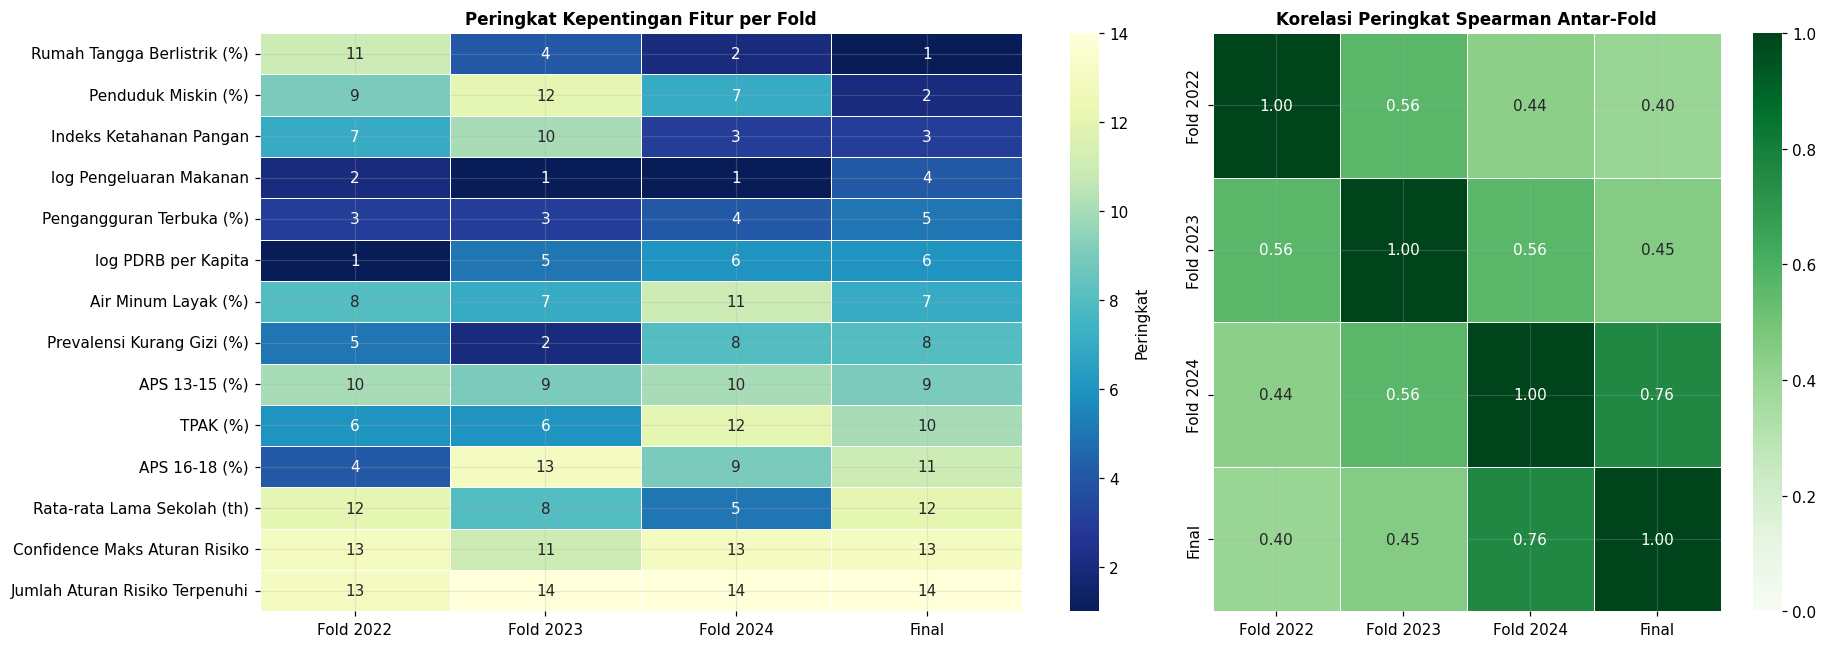

In [48]:
stability_imp = {}
for test_year, _ in FOLDS[1]:
    model_fold, X_tr, X_te = fitted_models[(1, test_year, FINAL_FS, FINAL_MODEL)]
    bg_fold = X_tr.sample(n=min(100, len(X_tr)), random_state=SEED)
    sv = shap_for(FINAL_MODEL, model_fold, X_te, bg_fold)[0]
    stability_imp[f"Fold {test_year}"] = np.abs(sv).mean(axis=0)
stability_imp["Final"] = importance.set_index("fitur").loc[features_final, "mean_abs_shap"].to_numpy()
stability_imp = pd.DataFrame(stability_imp, index=[LABELS[f] for f in features_final])
rank_corr = stability_imp.corr(method="spearman")
print("Korelasi peringkat kepentingan SHAP antar-fold:\n" + rank_corr.round(3).to_string())
save_table(stability_imp.round(5).reset_index().rename(columns={"index": "fitur"}), "06_xai", "shap_kepentingan_per_fold")
fig, axes = plt.subplots(1, 2, figsize=(17, 6), gridspec_kw={"width_ratios": [1.5, 1]})
rank_table = stability_imp.rank(ascending=False).astype(int)
rank_table = rank_table.loc[rank_table["Final"].sort_values().index]
sns.heatmap(rank_table, annot=True, fmt="d", cmap="YlGnBu_r", linewidths=0.5, ax=axes[0], cbar_kws={"label": "Peringkat"})
axes[0].set_title("Peringkat Kepentingan Fitur per Fold", fontsize=11)
sns.heatmap(rank_corr, annot=True, fmt=".2f", cmap="Greens", vmin=0, vmax=1, linewidths=0.5, ax=axes[1])
axes[1].set_title("Korelasi Peringkat Spearman Antar-Fold", fontsize=11)
fig.tight_layout()
save_fig(fig, "06_xai", "shap_stabilitas")

### 8.6 Simulasi Skenario (Sensitivitas Model)

Untuk provinsi dengan proyeksi terendah, beberapa kondisi pendukung yang dapat diintervensi dinaikkan ke median nasional 2025 (hanya jika saat ini lebih buruk dari median), lalu proyeksi dihitung ulang. Fitur spasial dan fitur aturan dibiarkan tetap agar efeknya terisolasi.

Hasil ini adalah **sensitivitas model**, bukan efek kausal. Gunanya untuk menunjukkan kondisi mana yang paling "didengarkan" model, sehingga bisa menjadi bahan diskusi prioritas kebijakan.

skenario          Listrik ke median  Air minum ke median  Kemiskinan ke median  RLS ke median  Gabungan semua
provinsi                                                                                                     
GORONTALO                     0.068                0.000                 1.423          0.041           1.566
KALIMANTAN BARAT              0.113               -0.036                 0.000         -0.020           0.064
PAPUA PEGUNUNGAN              1.037                0.387                 0.798         -0.053           2.386
PAPUA SELATAN                 1.036                0.602                 0.529          0.063           2.466
PAPUA TENGAH                  1.062               -0.058                 0.678         -0.252           1.738
SULAWESI UTARA                0.000                0.000                 0.000          0.000           0.000


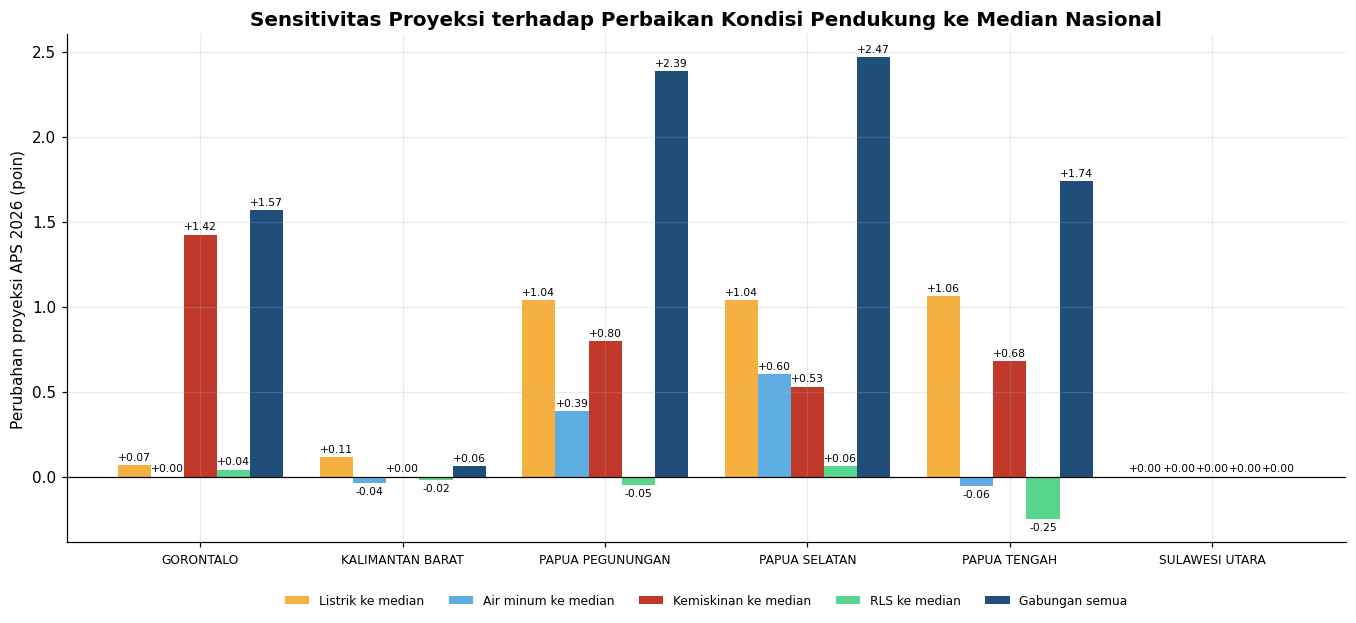

In [49]:
SCENARIOS = {"Listrik ke median": {"listrik": "up"}, "Air minum ke median": {"air_minum_layak": "up"},
             "Kemiskinan ke median": {"miskin": "down"}, "RLS ke median": {"rls": "up"},
             "Gabungan semua": {"listrik": "up", "air_minum_layak": "up", "miskin": "down", "rls": "up"}}
medians = origin_2025[features_final].median()
scenario_rows = []
for prov in forecast.head(6)["provinsi"]:
    base_row = origin_2025.loc[origin_2025["provinsi"] == prov, features_final].copy()
    base_pred = float(predict_final(base_row)[0])
    for name, changes in SCENARIOS.items():
        row = base_row.copy()
        for feat, direction in changes.items():
            row[feat] = np.maximum(row[feat], medians[feat]) if direction == "up" else np.minimum(row[feat], medians[feat])
        scenario_rows.append({"provinsi": prov, "skenario": name, "prediksi_delta_awal": base_pred,
                              "prediksi_delta_skenario": float(predict_final(row)[0])})
scenario = pd.DataFrame(scenario_rows)
scenario["perubahan_proyeksi"] = scenario["prediksi_delta_skenario"] - scenario["prediksi_delta_awal"]
save_table(scenario.round(5), "06_xai", "simulasi_skenario")
scenario_pivot = scenario.pivot(index="provinsi", columns="skenario", values="perubahan_proyeksi")[list(SCENARIOS)]
print(scenario_pivot.round(3).to_string())
fig, ax = plt.subplots(figsize=(15, 6))
scenario_pivot.plot.bar(ax=ax, width=0.82, rot=0, color=["#F5B041", "#5DADE2", "#C0392B", "#58D68D", "#1F4E79"])
label_bars(ax, fmt="{:+.2f}", fontsize=7)
ax.axhline(0, color="black", linewidth=0.8)
ax.set_ylabel("Perubahan proyeksi APS 2026 (poin)")
ax.set_xlabel("")
ax.set_title("Sensitivitas Proyeksi terhadap Perbaikan Kondisi Pendukung ke Median Nasional")
ax.tick_params(axis="x", labelsize=8)
ax.legend(fontsize=8, ncol=5, loc="upper center", bbox_to_anchor=(0.5, -0.08))
save_fig(fig, "06_xai", "simulasi_skenario")

### 8.7 Pendorong Proyeksi Jangka Pendek (2026) vs Jangka Menengah (2027)

Model horizon 2 dijelaskan dengan cara yang sama, lalu porsi kepentingan setiap fitur dibandingkan antarhorizon. Jika urutan pendorong bergeser, misalnya faktor infrastruktur dominan untuk satu tahun ke depan tetapi faktor ekonomi atau pendidikan keluarga lebih dominan untuk dua tahun ke depan, maka kebijakan perlu dibedakan antara intervensi cepat dan intervensi struktural.

Model horizon 2: LightGBM | Base+Spatial | pemeriksaan aditivitas SHAP 1.15e-14

Porsi kepentingan SHAP per horizon (%):
                                2026 (horizon 1)  2027 (horizon 2)
Rumah Tangga Berlistrik (%)                18.39             10.39
Indeks Ketahanan Pangan                    10.98             15.56
log Pengeluaran Makanan                     9.67             15.21
Penduduk Miskin (%)                        12.47              4.99
Pengangguran Terbuka (%)                    9.82              9.48
log PDRB per Kapita                         7.78              7.02
APS 16-18 (%)                               3.96              7.25
Spatial Lag Kemiskinan                      0.00              6.19
APS 13-15 (%)                               4.66              6.15
Air Minum Layak (%)                         5.67              2.89
Prevalensi Kurang Gizi (%)                  4.57              4.70
TPAK (%)                                    4.54              3.29
Rata-rat

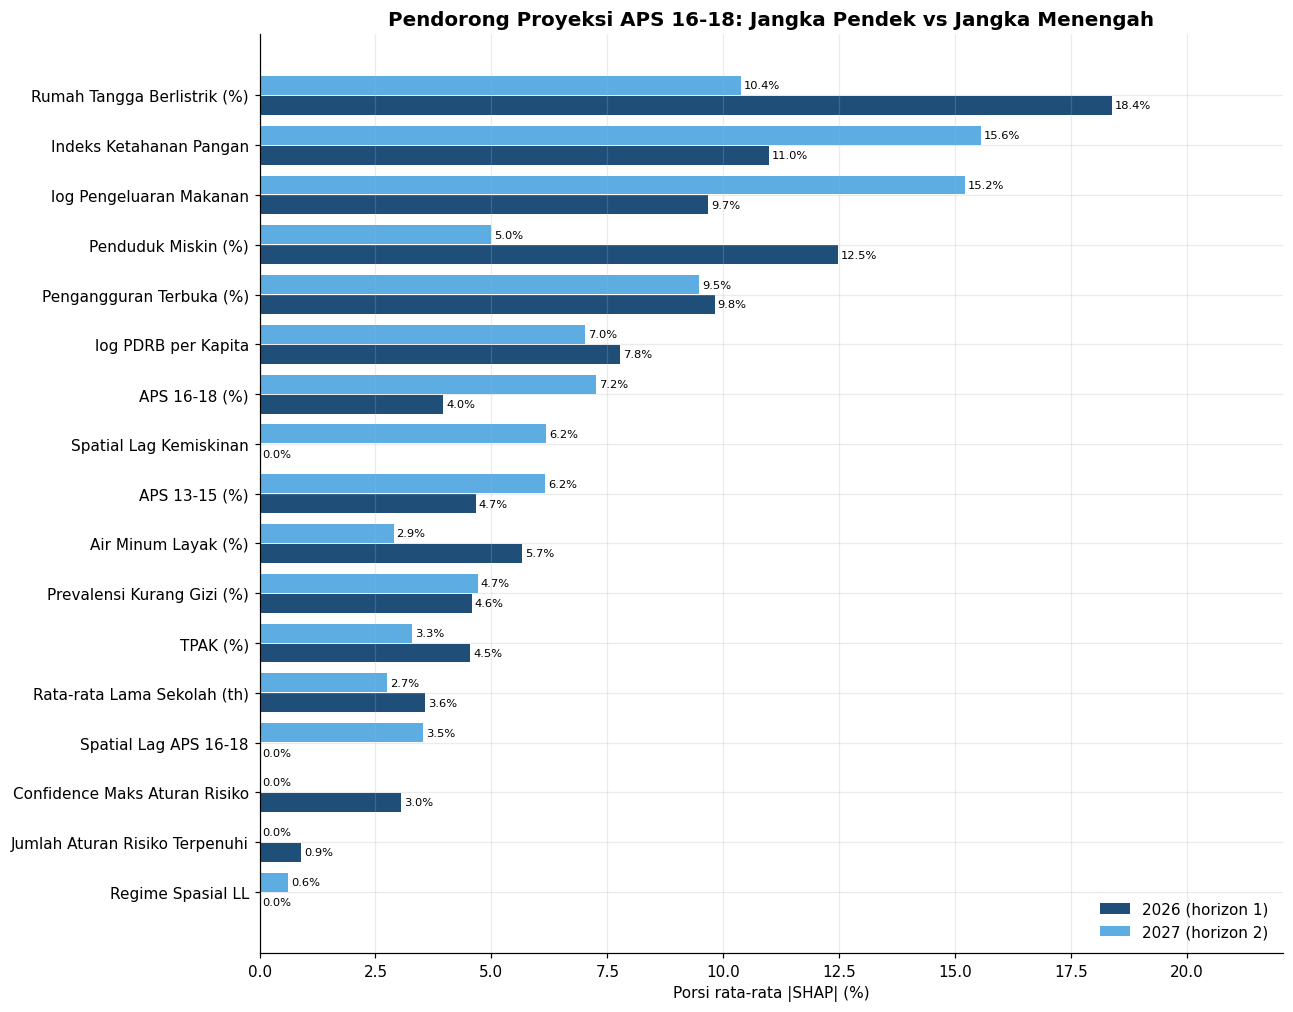

In [50]:
h2_model, h2_fs = FINAL[2]
features_h2 = FEATURE_SETS[h2_fs]
bg_h2 = train_sets[2][features_h2].sample(n=min(100, len(train_sets[2])), random_state=SEED)
shap_h2, base_h2 = shap_for(h2_model, final_fit[2], train_sets[2][features_h2], bg_h2)
check_h2 = np.abs(shap_h2.sum(axis=1) + base_h2 - predict_h(2, train_sets[2][features_h2])).max()
print(f"Model horizon 2: {h2_model} | {h2_fs} | pemeriksaan aditivitas SHAP {check_h2:.2e}")
share = pd.DataFrame({"2026 (horizon 1)": pd.Series(np.abs(shap_values[:len(train_all)]).mean(axis=0), index=features_final),
                      "2027 (horizon 2)": pd.Series(np.abs(shap_h2).mean(axis=0), index=features_h2)}).fillna(0)
share = share / share.sum() * 100
share = share.loc[share.max(axis=1).sort_values().index]
share.index = [LABELS[f] for f in share.index]
rank_shift = share.rank(ascending=False)
print("\nPorsi kepentingan SHAP per horizon (%):\n" + share.iloc[::-1].round(2).to_string())
print(f"\nKorelasi peringkat Spearman antarhorizon: {stats.spearmanr(share.iloc[:, 0], share.iloc[:, 1])[0]:.3f}")
save_table(share.iloc[::-1].round(4).reset_index().rename(columns={"index": "fitur"}), "06_xai", "shap_perbandingan_horizon")

fig, ax = plt.subplots(figsize=(12, 0.55 * len(share) + 1.5))
ypos = np.arange(len(share))
for offset, col, color in [(-0.2, share.columns[0], COLORS["primary"]), (0.2, share.columns[1], "#5DADE2")]:
    bars = ax.barh(ypos + offset, share[col], height=0.38, color=color, label=col)
    ax.bar_label(bars, fmt="{:.1f}%", fontsize=7.5, padding=2)
ax.set_yticks(ypos)
ax.set_yticklabels(share.index)
ax.set_xlim(0, share.max().max() * 1.2)
ax.set_xlabel("Porsi rata-rata |SHAP| (%)")
ax.set_title("Pendorong Proyeksi APS 16-18: Jangka Pendek vs Jangka Menengah")
ax.legend(loc="lower right")
save_fig(fig, "06_xai", "shap_perbandingan_horizon")

## 9. Triangulasi: Indeks Prioritas Intervensi

### 9.1 Tiga Sinyal Independen per Provinsi

Setiap provinsi mendapat tiga skor bernilai 0 sampai 1:

- **Skor spasial**: 1 jika masuk cluster LISA LL signifikan pada 2025, 0,5 jika berada di kuadran LL tetapi tidak signifikan, 0 selain itu.
- **Skor pola**: confidence maksimum dari aturan risiko yang dipenuhi provinsi pada 2025, yaitu perkiraan peluang APS rendah berdasarkan pola historis.
- **Skor prediktif**: 1 dikurangi peringkat persentil proyeksi APS 2026, sehingga provinsi dengan proyeksi terendah mendekati 1. Proyeksi 2026 dipakai sebagai sinyal utama karena horizon 1 divalidasi dengan tiga fold, sedangkan proyeksi 2027 dipakai untuk mendeteksi tren merosot.

Sinyal dianggap "menyala" jika skor spasial minimal 0,5, skor pola minimal ambang confidence aturan, dan proyeksi 2026 berada di tertil terbawah. **Indeks Prioritas Intervensi (IPI)** adalah rata-rata ketiga skor dikali 100.

In [51]:
tri = forecast.merge(map_2025[["provinsi", "regime", "cluster", "p_sim", "sig_fdr"]], on="provinsi")
tri = tri.merge(origin_2025[["provinsi", "rule_count", "rule_max_conf"]], on="provinsi")
tri["skor_spasial"] = np.select([(tri["cluster"] == "LL"), (tri["regime"] == "LL")], [1.0, 0.5], default=0.0)
tri["skor_pola"] = tri["rule_max_conf"]
tri["skor_prediktif"] = 1 - tri["aps_2026_pred"].rank(pct=True)
tri["sinyal_spasial"] = tri["skor_spasial"] >= 0.5
tri["sinyal_pola"] = tri["skor_pola"] >= RULE_MIN_CONFIDENCE
tri["sinyal_prediktif"] = tri["aps_2026_pred"] <= tri["aps_2026_pred"].quantile(1 / 3)
tri["jumlah_sinyal"] = tri[["sinyal_spasial", "sinyal_pola", "sinyal_prediktif"]].sum(axis=1)
tri["IPI"] = tri[["skor_spasial", "skor_pola", "skor_prediktif"]].mean(axis=1) * 100


def typology(row):
    if row["jumlah_sinyal"] == 3:
        return "Terjebak Struktural"
    if row["sinyal_prediktif"] and (row["sinyal_spasial"] or row["sinyal_pola"]):
        return "Risiko Tinggi Terkonfirmasi"
    if row["sinyal_prediktif"]:
        return "Waspada Prediktif"
    if row["sinyal_spasial"]:
        return "Terseret Lingkungan"
    if row["sinyal_pola"]:
        return "Kerentanan Internal"
    if row["pred_delta"] < 0 or row["aps_2027_pred"] < row["aps_2025"]:
        return "Rawan Merosot"
    return "Relatif Aman"


tri["tipologi"] = tri.apply(typology, axis=1)
ACTIONABLE = ["miskin", "listrik", "air_minum_layak", "rls", "log_pdrb_kapita", "tpt", "pou", "log_pengeluaran_makanan", "ikp", "aps_13_15"]
LEVER_TEXT = {"miskin": "pengentasan kemiskinan dan bantuan biaya sekolah", "listrik": "elektrifikasi rumah tangga dan sekolah",
              "air_minum_layak": "infrastruktur dasar air minum dan sanitasi", "rls": "pendidikan keluarga dan literasi orang tua",
              "log_pdrb_kapita": "penguatan ekonomi daerah", "tpt": "keterhubungan sekolah dengan lapangan kerja",
              "pou": "intervensi gizi anak usia sekolah", "log_pengeluaran_makanan": "daya beli rumah tangga",
              "ikp": "ketahanan pangan daerah", "aps_13_15": "retensi siswa SMP ke jenjang SMA"}
lever_idx = local_2026.set_index("provinsi")[ACTIONABLE]
tri["tuas_utama"] = tri["provinsi"].map(lever_idx.idxmin(axis=1))
tri["kontribusi_tuas"] = tri["provinsi"].map(lever_idx.min(axis=1))
tri["rekomendasi"] = np.where(tri["kontribusi_tuas"] < 0, tri["tuas_utama"].map(LEVER_TEXT), "pertahankan capaian dan pantau")
tri["tuas_utama"] = tri["tuas_utama"].map(LABELS)
tri = tri.sort_values("IPI", ascending=False).reset_index(drop=True)
tri.insert(0, "peringkat_prioritas", np.arange(1, len(tri) + 1))
tri_cols = ["peringkat_prioritas", "provinsi", "IPI", "tipologi", "jumlah_sinyal", "skor_spasial", "skor_pola", "skor_prediktif",
            "aps_2025", "aps_2026_pred", "aps_2027_pred", "tuas_utama", "rekomendasi"]
print(tri[tri_cols].head(15).round(3).to_string(index=False))
print("\nDistribusi tipologi:\n" + tri["tipologi"].value_counts().to_string())
save_table(tri.round(5), "07_triangulation", "indeks_prioritas_intervensi")

 peringkat_prioritas             provinsi    IPI                    tipologi  jumlah_sinyal  skor_spasial  skor_pola  skor_prediktif  aps_2025  aps_2026_pred  aps_2027_pred                  tuas_utama                                      rekomendasi
                   1     PAPUA PEGUNUNGAN 88.722         Terjebak Struktural              3           1.0      0.714           0.947     50.79         47.061         53.887 Rumah Tangga Berlistrik (%)           elektrifikasi rumah tangga dan sekolah
                   2        PAPUA SELATAN 87.845         Terjebak Struktural              3           1.0      0.714           0.921     66.97         64.450         68.900 Rumah Tangga Berlistrik (%)           elektrifikasi rumah tangga dan sekolah
                   3         PAPUA TENGAH 72.932         Terjebak Struktural              3           0.5      0.714           0.974     44.61         43.393         47.692 Rumah Tangga Berlistrik (%)           elektrifikasi rumah tangga dan sekolah


,peringkat_prioritas,provinsi,kode,wilayah,lon,lat,aps_2025,delta_2026,aps_2026_pred,bawah_2026,atas_2026,delta_2027,aps_2027_pred,bawah_2027,atas_2027,pred_delta,regime,cluster,p_sim,sig_fdr,rule_count,rule_max_conf,skor_spasial,skor_pola,skor_prediktif,sinyal_spasial,sinyal_pola,sinyal_prediktif,jumlah_sinyal,IPI,tipologi,tuas_utama,kontribusi_tuas,rekomendasi
0,1,PAPUA PEGUNUNGAN,PAPEG,Maluku-Papua,138.95,-4.10,50.79,-3.72861,47.06139,43.85757,50.26520,3.09709,53.88709,47.26608,60.50810,-3.72861,LL,LL,0.0194,False,3.0,0.71429,1.0,0.71429,0.94737,True,True,True,3,88.72180,Terjebak Struktural,Rumah Tangga Berlistrik (%),-1.20107,elektrifikasi rumah tangga dan sekolah
1,2,PAPUA SELATAN,PASEL,Maluku-Papua,140.40,-8.49,66.97,-2.51969,64.45031,61.24649,67.65412,1.92972,68.89972,62.27871,75.52074,-2.51969,LL,LL,0.0054,False,4.0,0.71429,1.0,0.71429,0.92105,True,True,True,3,87.84461,Terjebak Struktural,Rumah Tangga Berlistrik (%),-1.22167,elektrifikasi rumah tangga dan sekolah
2,3,PAPUA TENGAH,PATENG,Maluku-Papua,135.50,-3.37,44.61,-1.21722,43.39278,40.18897,46.59660,3.08243,47.69243,41.07142,54.31344,-1.21722,LL,Tidak signifikan,0.0943,False,3.0,0.71429,0.5,0.71429,0.97368,True,True,True,3,72.93233,Terjebak Struktural,Rumah Tangga Berlistrik (%),-1.23718,elektrifikasi rumah tangga dan sekolah
3,4,KALIMANTAN TENGAH,KALTENG,Kalimantan,113.92,-2.21,70.76,2.52792,73.28792,70.08411,76.49174,5.16546,75.92546,69.30444,82.54647,2.52792,LL,Tidak signifikan,0.3243,False,3.0,0.85000,0.5,0.85000,0.81579,True,True,True,3,72.19298,Terjebak Struktural,Rumah Tangga Berlistrik (%),-0.15514,elektrifikasi rumah tangga dan sekolah
4,5,SUMATERA SELATAN,SUMSEL,Sumatera,104.76,-2.98,73.78,1.92429,75.70429,72.50047,78.90810,2.91919,76.69919,70.07818,83.32020,1.92429,LL,Tidak signifikan,0.3999,False,1.0,0.75000,0.5,0.75000,0.78947,True,True,True,3,67.98246,Terjebak Struktural,log Pengeluaran Makanan,-0.29804,daya beli rumah tangga
5,6,GORONTALO,GORONTALO,Sulawesi,123.06,0.54,72.00,0.53417,72.53417,69.33036,75.73799,1.27650,73.27650,66.65548,79.89751,0.53417,LL,Tidak signifikan,0.3922,False,1.0,0.63636,0.5,0.63636,0.86842,True,True,True,3,66.82616,Terjebak Struktural,Penduduk Miskin (%),-0.66612,pengentasan kemiskinan dan bantuan biaya sekolah
6,7,KALIMANTAN BARAT,KALBAR,Kalimantan,109.33,-0.03,70.95,1.63009,72.58009,69.37627,75.78390,1.74351,72.69351,66.07250,79.31452,1.63009,LH,Tidak signifikan,0.4661,False,6.0,0.85000,0.0,0.85000,0.84211,False,True,True,2,56.40351,Risiko Tinggi Terkonfirmasi,Rumah Tangga Berlistrik (%),-0.26194,elektrifikasi rumah tangga dan sekolah
7,8,SULAWESI BARAT,SULBAR,Sulawesi,118.89,-2.68,73.22,2.52856,75.74856,72.54475,78.95238,1.91682,75.13682,68.51581,81.75783,2.52856,LH,Tidak signifikan,0.3658,False,1.0,0.70588,0.0,0.70588,0.76316,False,True,True,2,48.96801,Risiko Tinggi Terkonfirmasi,Rumah Tangga Berlistrik (%),-0.14465,elektrifikasi rumah tangga dan sekolah
8,9,JAMBI,JAMBI,Sumatera,103.61,-1.61,74.39,2.23457,76.62457,73.42076,79.82839,2.38372,76.77372,70.15271,83.39473,2.23457,LH,Tidak signifikan,0.2648,False,2.0,0.75000,0.0,0.75000,0.71053,False,True,True,2,48.68421,Risiko Tinggi Terkonfirmasi,Rumah Tangga Berlistrik (%),-0.16258,elektrifikasi rumah tangga dan sekolah
9,10,SULAWESI UTARA,SULUT,Sulawesi,124.84,1.47,71.45,0.02817,71.47817,68.27435,74.68199,0.38337,71.83337,65.21236,78.45438,0.02817,LL,Tidak signifikan,0.3983,False,0.0,0.00000,0.5,0.00000,0.89474,True,False,True,2,46.49123,Risiko Tinggi Terkonfirmasi,Rata-rata Lama Sekolah (th),-0.48068,pendidikan keluarga dan literasi orang tua


### 9.2 Konvergensi dan Kesepakatan Antarsinyal

Kesepakatan antarsinyal diukur dengan persentase kesamaan dan **Cohen's kappa** (kesepakatan setelah dikoreksi faktor kebetulan). Kesepakatan tinggi berarti tiga metode yang berbeda prinsipnya sampai pada kesimpulan yang sama, sehingga temuan kokoh. Ketidaksepakatan juga informatif: provinsi yang hanya ditandai satu metode memerlukan pemeriksaan lebih lanjut.

Sensitivitas IPI terhadap pembobotan juga diuji: jika peringkat prioritas hampir tidak berubah di bawah bobot berbeda, IPI tidak bergantung pada pilihan bobot yang subjektif.

Persentase kesepakatan:
           Spasial   Pola  Prediktif
Spasial      1.000  0.684      0.842
Pola         0.684  1.000      0.684
Prediktif    0.842  0.684      1.000

Cohen's kappa:
           Spasial   Pola  Prediktif
Spasial      1.000  0.323      0.606
Pola         0.323  1.000      0.347
Prediktif    0.606  0.347      1.000

Irisan 10 provinsi prioritas teratas dengan skema setara: {'Setara (1/3 masing-masing)': 10, 'Prediktif dominan (0,25/0,25/0,5)': 10, 'Spasial dominan (0,5/0,25/0,25)': 10, 'Pola dominan (0,25/0,5/0,25)': 9}


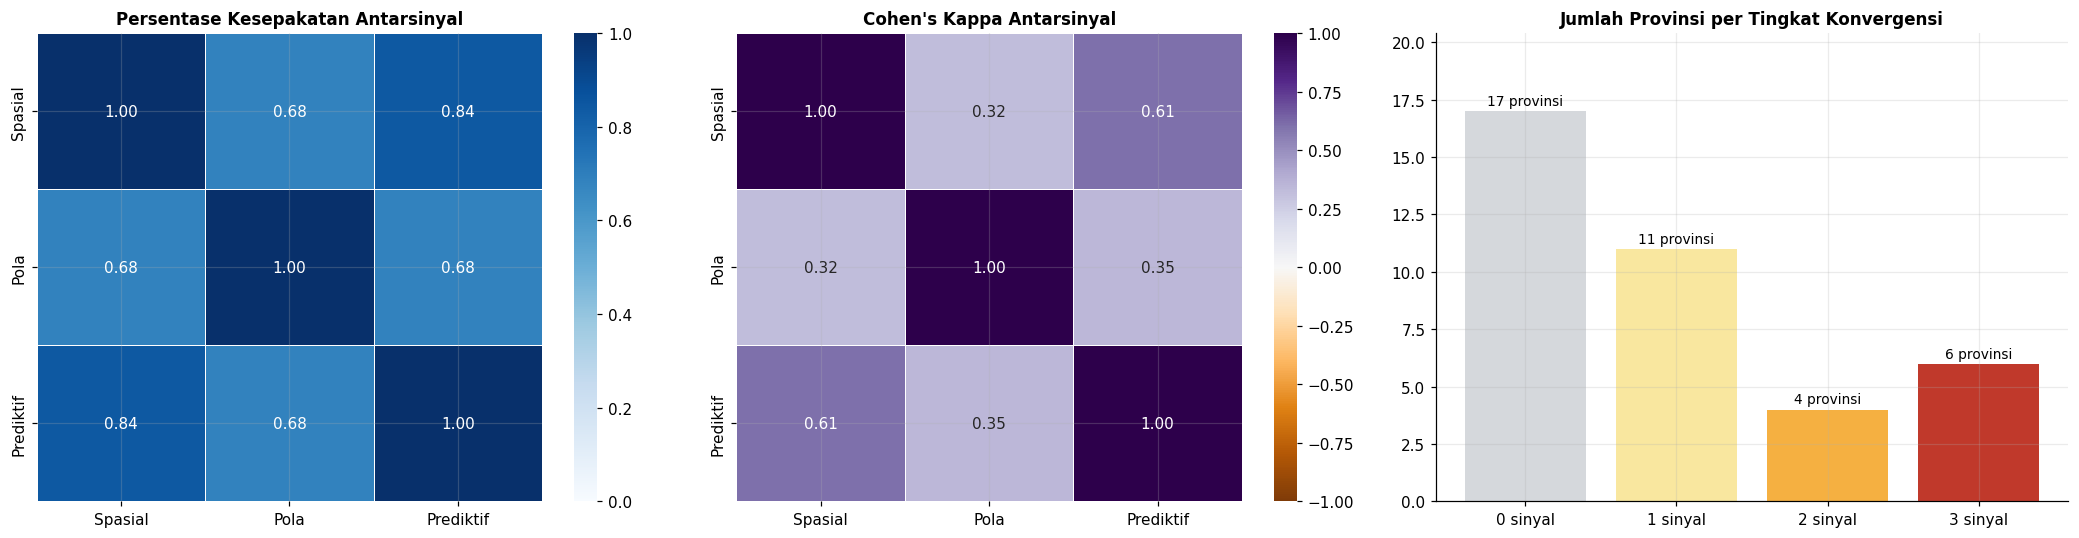

,sinyal,Spasial,Pola,Prediktif
0,Spasial,1.0000,0.3234,0.6055
1,Pola,0.3234,1.0000,0.3467
2,Prediktif,0.6055,0.3467,1.0000


In [52]:
signals = ["sinyal_spasial", "sinyal_pola", "sinyal_prediktif"]
signal_names = {"sinyal_spasial": "Spasial", "sinyal_pola": "Pola", "sinyal_prediktif": "Prediktif"}
agree = pd.DataFrame(index=signal_names.values(), columns=signal_names.values(), dtype=float)
kappa = agree.copy()
for a in signals:
    for b in signals:
        agree.loc[signal_names[a], signal_names[b]] = (tri[a] == tri[b]).mean()
        same = tri[a].astype(int).equals(tri[b].astype(int))
        kappa.loc[signal_names[a], signal_names[b]] = 1.0 if same else cohen_kappa_score(tri[a].astype(int), tri[b].astype(int))
print("Persentase kesepakatan:\n" + agree.round(3).to_string())
print("\nCohen's kappa:\n" + kappa.round(3).to_string())

weight_schemes = {"Setara (1/3 masing-masing)": (1 / 3, 1 / 3, 1 / 3), "Prediktif dominan (0,25/0,25/0,5)": (0.25, 0.25, 0.5),
                  "Spasial dominan (0,5/0,25/0,25)": (0.5, 0.25, 0.25), "Pola dominan (0,25/0,5/0,25)": (0.25, 0.5, 0.25)}
ipi_alt = pd.DataFrame({name: tri[["skor_spasial", "skor_pola", "skor_prediktif"]].to_numpy() @ np.array(w) * 100
                        for name, w in weight_schemes.items()})
weight_corr = ipi_alt.corr(method="spearman")
top10 = set(tri.head(10)["provinsi"])
overlap = {name: len(top10 & set(tri.loc[ipi_alt[name].nlargest(10).index, "provinsi"])) for name in weight_schemes}
print("\nIrisan 10 provinsi prioritas teratas dengan skema setara:", overlap)
save_table(weight_corr.round(4).reset_index().rename(columns={"index": "skema"}), "07_triangulation", "sensitivitas_bobot_ipi")

fig, axes = plt.subplots(1, 3, figsize=(19, 5))
sns.heatmap(agree.astype(float), annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, linewidths=0.5, ax=axes[0])
axes[0].set_title("Persentase Kesepakatan Antarsinyal", fontsize=11)
sns.heatmap(kappa.astype(float), annot=True, fmt=".2f", cmap="PuOr", vmin=-1, vmax=1, linewidths=0.5, ax=axes[1])
axes[1].set_title("Cohen's Kappa Antarsinyal", fontsize=11)
conv = tri["jumlah_sinyal"].value_counts().reindex([0, 1, 2, 3], fill_value=0)
bars = axes[2].bar([f"{k} sinyal" for k in conv.index], conv.to_numpy(), color=["#D5D8DC", "#F9E79F", "#F5B041", "#C0392B"])
axes[2].bar_label(bars, labels=[f"{v} provinsi" for v in conv.to_numpy()], fontsize=9, padding=2)
axes[2].set_ylim(0, conv.max() * 1.2)
axes[2].set_title("Jumlah Provinsi per Tingkat Konvergensi", fontsize=11)
fig.tight_layout()
save_fig(fig, "07_triangulation", "konvergensi_sinyal")
save_table(agree.astype(float).round(4).reset_index().rename(columns={"index": "sinyal"}), "07_triangulation", "kesepakatan_sinyal")
save_table(kappa.astype(float).round(4).reset_index().rename(columns={"index": "sinyal"}), "07_triangulation", "kappa_sinyal")

### 9.3 Peringkat Indeks Prioritas Intervensi

Batang bertumpuk menunjukkan sumbangan masing-masing sinyal terhadap IPI, sehingga terlihat apakah sebuah provinsi diprioritaskan karena faktor spasial, pola, prediksi, atau gabungan ketiganya. Label di ujung batang adalah nilai IPI dan tipologinya.

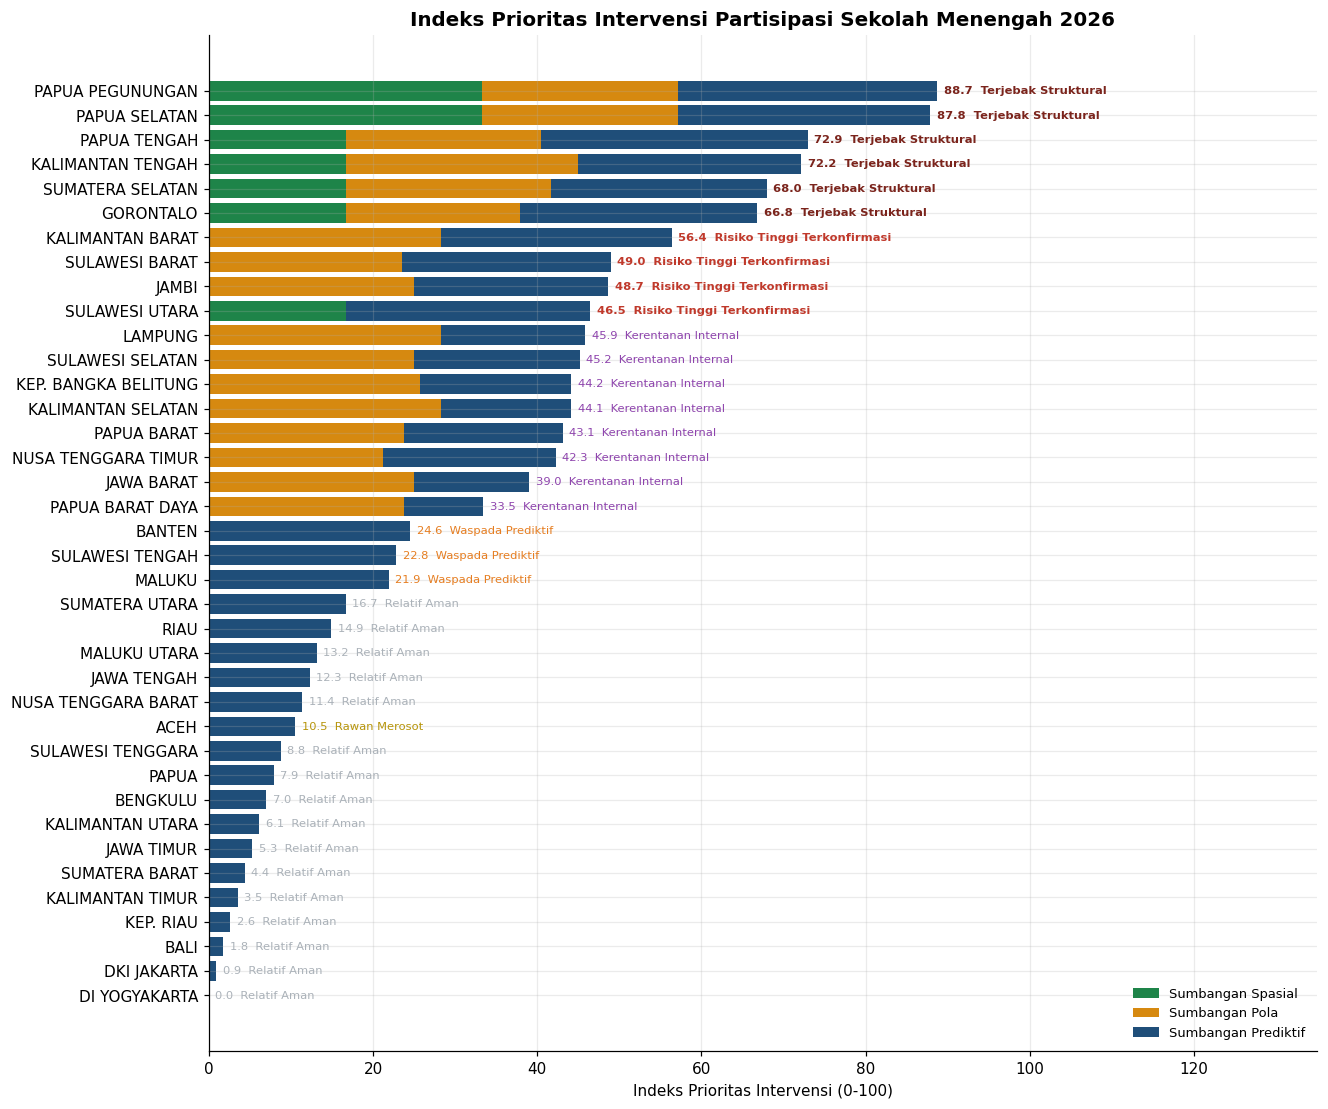

In [53]:
TYPE_COLORS = {"Terjebak Struktural": "#7B241C", "Risiko Tinggi Terkonfirmasi": "#C0392B", "Waspada Prediktif": "#E67E22",
               "Terseret Lingkungan": "#2471A3", "Kerentanan Internal": "#8E44AD", "Rawan Merosot": "#B7950B", "Relatif Aman": "#ABB2B9"}
plot_tri = tri.iloc[::-1]
fig, ax = plt.subplots(figsize=(13, 12))
left = np.zeros(len(plot_tri))
for col, label, color in [("skor_spasial", "Spasial", COLORS["good"]), ("skor_pola", "Pola", COLORS["warn"]),
                          ("skor_prediktif", "Prediktif", COLORS["primary"])]:
    width = plot_tri[col].to_numpy() * 100 / 3
    ax.barh(plot_tri["provinsi"], width, left=left, color=color, label=f"Sumbangan {label}")
    left += width
for i, (_, row) in enumerate(plot_tri.iterrows()):
    ax.text(row["IPI"] + 0.8, i, f"{row['IPI']:.1f}  {row['tipologi']}", va="center", fontsize=7.5, color=TYPE_COLORS[row["tipologi"]],
            fontweight="bold" if row["jumlah_sinyal"] >= 2 else "normal")
ax.set_xlim(0, 135)
ax.set_xlabel("Indeks Prioritas Intervensi (0-100)")
ax.set_title("Indeks Prioritas Intervensi Partisipasi Sekolah Menengah 2026")
ax.legend(loc="lower right", fontsize=8.5)
save_fig(fig, "07_triangulation", "peringkat_ipi")

### 9.4 Peta Tipologi dan Prioritas Intervensi

Peta akhir menyatukan seluruh pipeline: warna adalah tipologi hasil triangulasi, ukuran lingkaran sebanding dengan IPI, dan angka di bawah kode provinsi adalah proyeksi APS 16-18 tahun 2026.

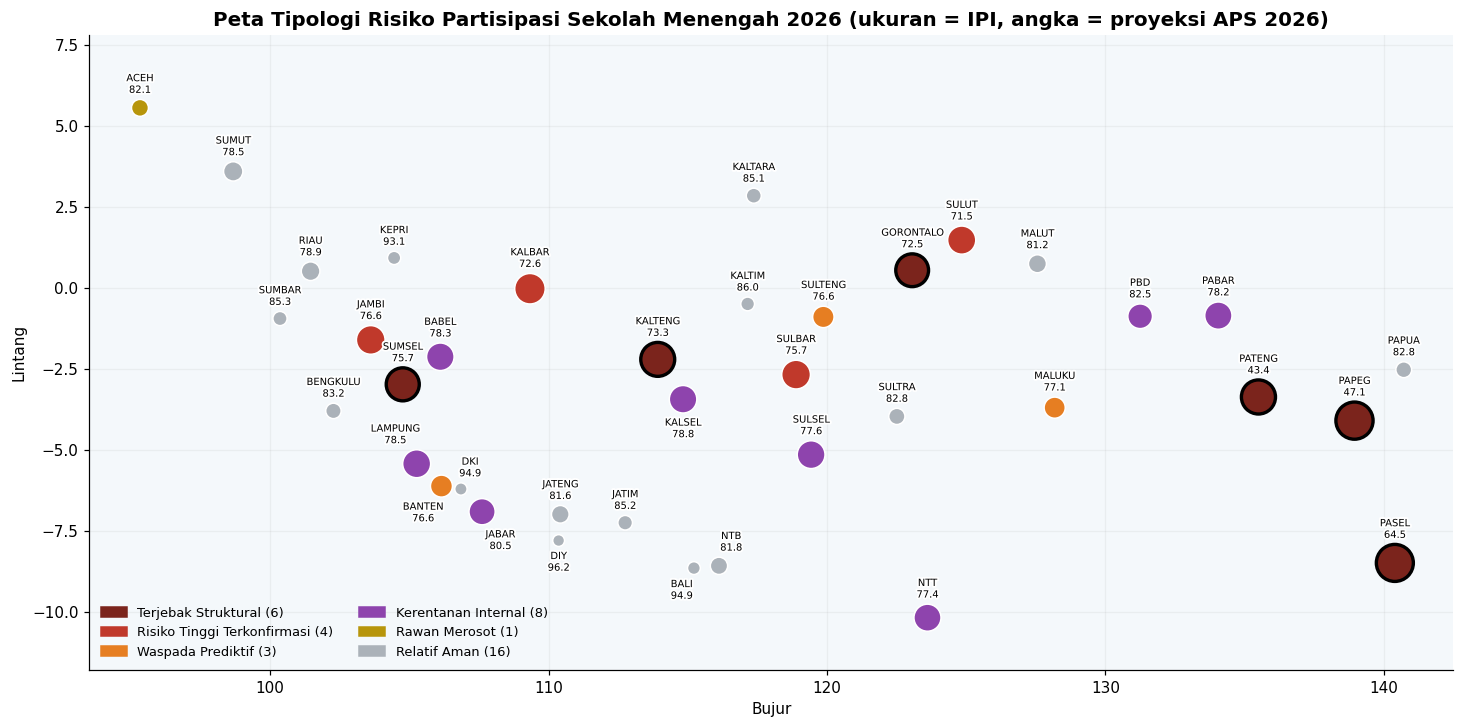

                             jumlah  rata2_IPI  rata2_aps_2026                                                                                                                                                                                                               provinsi
tipologi                                                                                                                                                                                                                                                                             
Terjebak Struktural               6      76.08           62.74                                                                                                                          PAPUA PEGUNUNGAN, PAPUA SELATAN, PAPUA TENGAH, KALIMANTAN TENGAH, SUMATERA SELATAN, GORONTALO
Risiko Tinggi Terkonfirmasi       4      50.14           74.11                                                                                                        

,tipologi,jumlah,rata2_IPI,rata2_aps_2026,provinsi
0,Terjebak Struktural,6,76.083,62.738,"PAPUA PEGUNUNGAN, PAPUA SELATAN, PAPUA TENGAH, KALIMANTAN TENGAH, SUMATERA S..."
1,Risiko Tinggi Terkonfirmasi,4,50.137,74.108,"KALIMANTAN BARAT, SULAWESI BARAT, JAMBI, SULAWESI UTARA"
2,Kerentanan Internal,8,42.153,78.984,"LAMPUNG, SULAWESI SELATAN, KEP. BANGKA BELITUNG, KALIMANTAN SELATAN, PAPUA B..."
3,Waspada Prediktif,3,23.099,76.776,"BANTEN, SULAWESI TENGAH, MALUKU"
4,Rawan Merosot,1,10.526,82.138,ACEH
5,Relatif Aman,16,7.292,85.731,"SUMATERA UTARA, RIAU, MALUKU UTARA, JAWA TENGAH, NUSA TENGGARA BARAT, SULAWE..."


In [54]:
fig, ax = plt.subplots(figsize=(16, 7.5))
province_map(ax, tri, tri["tipologi"].map(TYPE_COLORS), size=60 + tri["IPI"] * 6, value_col="aps_2026_pred",
             edge=np.where(tri["jumlah_sinyal"] == 3, "black", "white"), linewidth=np.where(tri["jumlah_sinyal"] == 3, 2.2, 1.0),
             title="Peta Tipologi Risiko Partisipasi Sekolah Menengah 2026 (ukuran = IPI, angka = proyeksi APS 2026)")
present = [t for t in TYPE_COLORS if t in set(tri["tipologi"])]
ax.legend(handles=[Patch(color=TYPE_COLORS[t], label=f"{t} ({int((tri['tipologi'] == t).sum())})") for t in present],
          loc="lower left", fontsize=8.5, ncol=2)
save_fig(fig, "07_triangulation", "peta_tipologi_2026")
type_summary = tri.groupby("tipologi").agg(jumlah=("provinsi", "count"), rata2_IPI=("IPI", "mean"),
                                           rata2_aps_2026=("aps_2026_pred", "mean"),
                                           provinsi=("provinsi", lambda s: ", ".join(s))).sort_values("rata2_IPI", ascending=False)
print(type_summary.round(2).to_string())
save_table(type_summary.round(3).reset_index(), "07_triangulation", "ringkasan_tipologi")

## 10. Ekspor Data untuk Dashboard Web

Seluruh hasil utama diekspor ke JSON di folder `web_data/` agar bisa langsung dibaca oleh aplikasi web (misalnya Next.js atau Vite di Vercel). Setiap file berisi array objek dengan nama kolom yang konsisten. Nilai kosong ditulis sebagai `null`.

| File | Isi |
|---|---|
| `provinces.json` | Metadata, koordinat, dan wilayah provinsi |
| `panel.json` | Data panel bersih analisis inti |
| `moran.json` | Global Moran's I, sensitivitas k, Moran perubahan, bivariat |
| `lisa.json` | Hasil LISA semua tahun |
| `rules.json` | Aturan terpilih, dinamika, dan spatial Markov |
| `forecast.json` | Leaderboard, metrik per fold, proyeksi 2026-2027, interval conformal |
| `shap.json` | Kepentingan global, per blok, dan SHAP lokal 2026 |
| `triangulation.json` | IPI, tipologi, tuas intervensi |
| `summary.json` | Angka kunci untuk kartu ringkasan di halaman utama |

In [55]:
def records_of(frame):
    clean = frame.copy()
    for col in clean.columns:
        if clean[col].dtype == bool:
            clean[col] = clean[col].astype(bool)
    return json.loads(clean.to_json(orient="records", double_precision=6))


def write_json(name, payload):
    with open(DIRS["web"] / name, "w", encoding="utf-8") as handle:
        json.dump(payload, handle, ensure_ascii=False, indent=2)


panel_cols = ["provinsi", "kode", "wilayah", "tahun", "lat", "lon"] + NUMERIC_COLS + ["log_pdrb_kapita", "log_pengeluaran_makanan"]
rules_export = selected_rules.assign(antecedent=selected_rules["antecedent"].apply(list))
summary_payload = {
    "judul": "EduGap-XAI",
    "jumlah_provinsi_2025": int(len(frame_2025)),
    "rata2_aps_16_18_2025": float(national_mean_2025),
    "perubahan_sd_semua_provinsi": float(sd_change_all),
    "perubahan_sd_32_provinsi_konsisten": float(sd_change_fixed),
    "moran_I_2025": float(I_2025),
    "moran_p_2025": float(moran_table.query("tahun == 2025 and variabel == @TARGET")["p_sim"].iloc[0]),
    "jumlah_cluster_LL_2025": int((map_2025["cluster"] == "LL").sum()),
    "jumlah_aturan_terpilih": int(len(selected_rules)),
    "model_final": {str(FORECAST_YEAR[h]): {"model": FINAL[h][0], "set_fitur": FINAL[h][1], "mae": float(final_rows[h]["MAE"]),
                                             "mae_persistence": float(persist_mae[h]), "skill": float(final_rows[h]["skill_agregat"]),
                                             "p_wilcoxon_vs_persistence": float(final_rows[h]["p_wilcoxon_vs_persistence"]),
                                             "conformal_halfwidth_90": float(conformal[h])} for h in HORIZONS},
    "provinsi_terjebak_struktural": tri.loc[tri["tipologi"] == "Terjebak Struktural", "provinsi"].tolist(),
    "prioritas_teratas": tri.head(5)["provinsi"].tolist(),
}
write_json("provinces.json", records_of(PROVINCE_META))
write_json("panel.json", records_of(analysis[panel_cols]))
write_json("moran.json", {"global": records_of(moran_table), "sensitivitas_k": records_of(sens_table),
                          "perubahan": records_of(change_moran), "bivariat": records_of(bv_table)})
write_json("lisa.json", records_of(lisa_all[lisa_cols + ["lat", "lon", "wilayah"]]))
write_json("rules.json", {"aturan": records_of(rules_export[["rule_id", "antecedent", "support", "confidence", "lift", "p_fisher", "q_fdr", "stabilitas"]]),
                          "dinamika": records_of(rule_dynamics), "keanggotaan": records_of(match_all),
                          "spatial_markov": records_of(markov_table), "uji_lr": {"statistik": float(lr_stat), "df": int(df_lr), "p": float(lr_p)}})
write_json("forecast.json", {"leaderboard": records_of(leaderboard), "per_fold": records_of(fold_metrics),
                             "proyeksi": records_of(forecast), "uji_cakupan": records_of(coverage),
                             "model_final": summary_payload["model_final"]})
write_json("shap.json", {"global": records_of(importance), "per_blok": records_of(group_importance.reset_index()),
                         "lokal_2026": records_of(local_2026), "base_value": base_value,
                         "perbandingan_horizon": records_of(share.reset_index().rename(columns={"index": "fitur"})), "skenario": records_of(scenario)})
write_json("triangulation.json", records_of(tri))
write_json("summary.json", summary_payload)
for path in sorted(DIRS["web"].glob("*.json")):
    print(f"{path.name:<22} {path.stat().st_size / 1024:8.1f} KB")

forecast.json              45.3 KB
lisa.json                  62.6 KB
moran.json                  6.2 KB
panel.json                123.2 KB
provinces.json              4.7 KB
rules.json                 47.9 KB
shap.json                  27.8 KB
summary.json                1.3 KB
triangulation.json         36.0 KB


## 11. Ringkasan Temuan Otomatis

Sel ini menyusun ringkasan temuan utama dari angka yang benar-benar dihasilkan notebook, lalu menyimpannya ke `report/ringkasan_temuan.md`. Ringkasan ini bisa menjadi kerangka bagian hasil dan kesimpulan makalah.

In [56]:
moran_target = moran_table[moran_table["variabel"] == TARGET].set_index("tahun")
sig_years = moran_target.index[moran_target["signifikan"]].tolist()
ll_2025 = map_2025.loc[map_2025["cluster"] == "LL", "provinsi"].tolist()
hh_2025 = map_2025.loc[map_2025["cluster"] == "HH", "provinsi"].tolist()
top_rule = selected_rules.iloc[0] if len(selected_rules) else None
abl = {h: summary[(summary["horizon"] == h) & (summary["model"] == FINAL[h][0])].set_index("fitur")["MAE"].reindex(list(FEATURE_SETS))
       for h in HORIZONS}
cov90 = coverage.loc[coverage["target_cakupan"].round(2) == 0.9, "cakupan_empiris"]
stay_weak = stay_low.set_index("konteks")["probabilitas"]

lines = [
    "# Ringkasan Temuan EduGap-XAI", "",
    "## Data dan preprocessing",
    f"- Panel {len(raw)} baris (38 provinsi x 5 tahun); {int(df['backcast_dob'].sum())} baris DOB Papua 2021-2023 terdeteksi sebagai salinan provinsi induk dan dikeluarkan, menyisakan {len(analysis)} baris analisis inti.",
    f"- {len(impute_log)} sel diimputasi sesuai aturan (tahun sebelumnya, tahun sesudahnya, lalu provinsi induk); {len(imputed_in_core)} di antaranya berada di analisis inti.",
    f"- Simpangan baku APS 16-18 berubah {sd_change_all:+.1%} (2021-2025) pada semua provinsi valid, tetapi {sd_change_fixed:+.1%} pada 32 provinsi dengan batas konsisten.", "",
    "## RQ1 Spatial autocorrelation",
    f"- Moran's I APS 16-18: " + ", ".join(f"{y}: {r['moran_I']:.3f} (p={r['p_sim']:.3f})" for y, r in moran_target.iterrows()) + ".",
    f"- Tahun dengan autokorelasi signifikan (p < 0,05): {sig_years if sig_years else 'tidak ada'}.",
    f"- Cluster LL 2025: {', '.join(ll_2025) if ll_2025 else 'tidak ada'}; cluster HH 2025: {', '.join(hh_2025) if hh_2025 else 'tidak ada'}.",
    f"- Bivariate Moran terkuat 2025: APS vs {LABELS[bv_table.iloc[0]['variabel_tetangga']]} tetangga, I = {bv_table.iloc[0]['moran_I_bv']:.3f} (p = {bv_table.iloc[0]['p_sim']:.3f}).", "",
    "## RQ2 Pattern mining",
    f"- {len(all_rules)} kandidat aturan, {len(selected_rules)} lolos FDR, stabilitas bootstrap, dan pruning; {int(has_spatial.sum())} di antaranya memuat item lingkungan spasial.",
    f"- Perbandingan dengan aturan tanpa item spasial: rata-rata lift {rule_compare.loc[0, 'rata2_lift']:.2f} vs {rule_compare.loc[1, 'rata2_lift']:.2f}, rata-rata confidence {rule_compare.loc[0, 'rata2_confidence']:.2f} vs {rule_compare.loc[1, 'rata2_confidence']:.2f}.",
    (f"- Aturan terkuat {top_rule['rule_id']}: {' & '.join(top_rule['antecedent'])} => {TARGET_ITEM} (support {top_rule['support']:.3f}, confidence {top_rule['confidence']:.3f}, lift {top_rule['lift']:.2f}, stabilitas {top_rule['stabilitas']:.0%})."
     if top_rule is not None else "- Tidak ada aturan yang lolos seluruh uji."),
    f"- Spatial Markov: peluang bertahan di kelas Rendah {stay_weak.get('Tetangga lemah', np.nan):.2f} saat tetangga lemah vs {stay_weak.get('Tetangga kuat', np.nan):.2f} saat tetangga kuat (uji LR p = {lr_p:.3f}).", "",
    "## RQ3 Explainable forecasting",
    *[f"- Horizon {h} ({FORECAST_YEAR[h]}): {FINAL[h][0]} | {FINAL[h][1]}, MAE {final_rows[h]['MAE']:.4f} vs persistence {persist_mae[h]:.4f}, "
      f"skill agregat {final_rows[h]['skill_agregat']:+.2%}, Wilcoxon vs persistence p = {final_rows[h]['p_wilcoxon_vs_persistence']:.4f}, "
      f"interval 90% +/- {conformal[h]:.2f} poin." for h in HORIZONS],
    *[f"- Ablation {FINAL[h][0]} horizon {h}: " + ", ".join(f"{k} {v:.4f}" for k, v in abl[h].items()) + "." for h in HORIZONS],
    f"- Cakupan empiris interval 90% horizon 1 pada 2025: {cov90.iloc[0]:.1%}." if len(cov90) else "- Uji cakupan tidak tersedia.",
    f"- Porsi kepentingan SHAP: " + ", ".join(f"{k} {v:.1f}%" for k, v in group_importance.items()) + ".",
    f"- Tiga fitur terpenting 2026: {', '.join(importance['label'].head(3))}; 2027: {', '.join(share.iloc[::-1].sort_values(share.columns[1], ascending=False).index[:3])}.",
    f"- Rata-rata proyeksi nasional: 2026 {forecast['aps_2026_pred'].mean():.2f}, 2027 {forecast['aps_2027_pred'].mean():.2f} (2025 aktual {forecast['aps_2025'].mean():.2f}).", "",
    "## RQ4 Triangulasi",
    f"- Provinsi Terjebak Struktural (tiga sinyal menyala): {', '.join(summary_payload['provinsi_terjebak_struktural']) or 'tidak ada'}.",
    f"- Lima prioritas teratas IPI: {', '.join(summary_payload['prioritas_teratas'])}.",
    f"- Rata-rata Cohen's kappa antarsinyal: {kappa.where(~np.eye(3, dtype=bool)).stack().mean():.3f}.", "",
    "## Batasan",
    "- Panel hanya 5 tahun dan 34-38 provinsi; seluruh uji memakai permutasi, bootstrap, dan validasi rolling-origin untuk mengimbanginya.",
    "- SHAP, aturan asosiasi, dan simulasi skenario menunjukkan asosiasi, bukan hubungan sebab-akibat.",
    "- Koordinat ibu kota adalah pendekatan lokasi provinsi; uji sensitivitas k dilakukan untuk memeriksa ketahanan hasil.",
]
report_text = "\n".join(lines)
(DIRS["rep"] / "ringkasan_temuan.md").write_text(report_text, encoding="utf-8")
print(report_text)

# Ringkasan Temuan EduGap-XAI

## Data dan preprocessing
- Panel 190 baris (38 provinsi x 5 tahun); 12 baris DOB Papua 2021-2023 terdeteksi sebagai salinan provinsi induk dan dikeluarkan, menyisakan 178 baris analisis inti.
- 56 sel diimputasi sesuai aturan (tahun sebelumnya, tahun sesudahnya, lalu provinsi induk); 0 di antaranya berada di analisis inti.
- Simpangan baku APS 16-18 berubah +49.2% (2021-2025) pada semua provinsi valid, tetapi -0.7% pada 32 provinsi dengan batas konsisten.

## RQ1 Spatial autocorrelation
- Moran's I APS 16-18: 2021: 0.116 (p=0.086), 2022: 0.126 (p=0.071), 2023: 0.116 (p=0.082), 2024: 0.112 (p=0.077), 2025: 0.184 (p=0.022).
- Tahun dengan autokorelasi signifikan (p < 0,05): [2025].
- Cluster LL 2025: PAPUA PEGUNUNGAN, PAPUA SELATAN; cluster HH 2025: BALI, JAWA TENGAH, JAWA TIMUR, SUMATERA UTARA.
- Bivariate Moran terkuat 2025: APS vs Penduduk Miskin (%) tetangga, I = -0.374 (p = 0.000).

## RQ2 Pattern mining
- 20 kandidat aturan, 7 lolos FDR, stabilitas b

## 12. Kemas dan Unduh Seluruh Output

Seluruh folder output dikemas menjadi `EduGap_XAI_outputs.zip`. Di Google Colab, file zip akan terunduh otomatis. Struktur di dalam zip:

```
EduGap_XAI_outputs/
  figures/   01_eda_raw ... 07_triangulation (PNG)
  tables/    01_eda_raw ... 07_triangulation (CSV)
  data/      dataset bersih dan log imputasi
  web_data/  JSON untuk dashboard web
  report/    ringkasan temuan
```

In [57]:
inventory = pd.DataFrame([{"folder": str(p.parent.relative_to(OUT)), "file": p.name, "ukuran_KB": round(p.stat().st_size / 1024, 1)}
                          for p in sorted(OUT.rglob("*")) if p.is_file()])
print(inventory.groupby("folder").agg(jumlah_file=("file", "count"), total_KB=("ukuran_KB", "sum")).to_string())
print(f"\nTotal file: {len(inventory)}")
zip_path = shutil.make_archive(OUT.name, "zip", root_dir=OUT.parent, base_dir=OUT.name)
print(f"Arsip dibuat: {zip_path} ({Path(zip_path).stat().st_size / 1024 / 1024:.2f} MB)")
try:
    from google.colab import files
    files.download(zip_path)
except ImportError:
    print("Bukan lingkungan Colab, unduh file zip secara manual dari direktori kerja.")

                          jumlah_file  total_KB
folder                                         
data                                3      90.0
figures/01_eda_raw                  3     376.9
figures/02_eda_clean                6    1833.0
figures/03_spatial                  9    2007.4
figures/04_pattern                  5     769.2
figures/05_forecast                 6    1655.3
figures/06_xai                      7    2075.8
figures/07_triangulation            3     848.0
report                              1       3.1
tables/01_eda_raw                   5       3.8
tables/02_eda_clean                 6       6.7
tables/03_spatial                   8      21.4
tables/04_pattern                   8      12.7
tables/05_forecast                  7      12.2
tables/06_xai                       7      10.4
tables/07_triangulation             5      12.8
web_data                            9     355.0

Total file: 98
Arsip dibuat: /content/EduGap_XAI_outputs.zip (8.25 MB)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>